In [3]:
!pip uninstall opencv-python -y
!pip uninstall opencv-contrib-python -y

Found existing installation: opencv-contrib-python 4.12.0.88
Uninstalling opencv-contrib-python-4.12.0.88:
  Successfully uninstalled opencv-contrib-python-4.12.0.88


In [2]:
import cv2
import os
video_path = r"C:\Maze\Video Data\DLC done\NPC1_2025_09_10_11_54_31_stitched_blacked.mp4"

cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise ValueError(f"Could not open video: {video_path}")

ret, frame = cap.read()
cap.release()

if not ret:
    raise ValueError("Could not read the first frame from the video.")

output_path = os.path.splitext(video_path)[0] + ".png"
if not cv2.imwrite(output_path, frame):
    raise ValueError(f"Failed to save frame to: {output_path}")

print(f"Saved first frame to: {output_path}")

Saved first frame to: C:\Maze\Video Data\DLC done\NPC1_2025_09_10_11_54_31_stitched_blacked.png


In [4]:
!pip install --upgrade pip

In [5]:
!pip install opencv-contrib-python
!pip install scikit-learn networkx matplotlib
import cv2

  Using cached opencv_contrib_python-4.12.0.88-cp37-abi3-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (19 kB)
Using cached opencv_contrib_python-4.12.0.88-cp37-abi3-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (73.2 MB)


In [6]:
!pip install -U scikit-image
# !pip install -U numpy 
!pip install -U scipy
!pip install -U matplotlib
!pip install -U networkx
!pip install -U scikit-learn
!pip install -U pandas

In [7]:
%pip install scikit-learn --quiet
from sklearn.cluster import DBSCAN
from scipy.ndimage import rotate

Note: you may need to restart the kernel to use updated packages.


In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import networkx as nx
import cv2
import os

In [13]:
# 1. Load and preprocess the image
image_path = '/var/home/almogmeir/Documents/M.Sc/Project/Mazes/maze2.png'
img = cv2.imread('/var/home/almogmeir/Documents/M.Sc/Project/stitched_image2.png', cv2.IMREAD_GRAYSCALE)
_, img_binary = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY_INV)

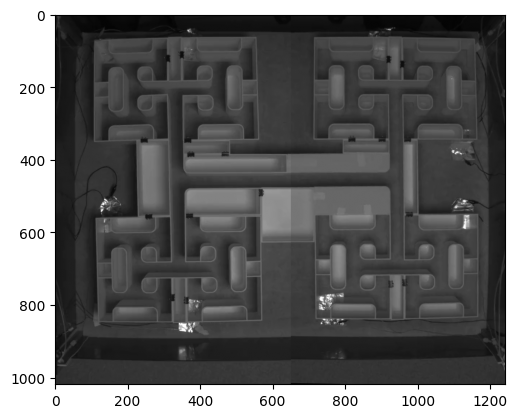

In [14]:
plt.imshow(img, cmap='gray')

# **Part 1 - Thresholding, Edge Detection, Transformations**

In [15]:
width  = img.shape[1]
height = img.shape[0]

distCoeff = np.zeros((4,1),np.float64)

k1 = -0.7e-5; # negative to remove barrel distortion
k2 = 0.0;
p1 = 0.0;
p2 = 0.0;

distCoeff[0,0] = k1;
distCoeff[1,0] = k2;
distCoeff[2,0] = p1;
distCoeff[3,0] = p2;

# assume unit matrix for camera
cam = np.eye(3,dtype=np.float32)

cam[0,2] = width/2.0  # define center x
cam[1,2] = height/2.0 # define center y
cam[0,0] = 10.        # define focal length x
cam[1,1] = 10.        # define focal length y

# here the undistortion will be computed
dst = cv2.undistort(img,cam,distCoeff)


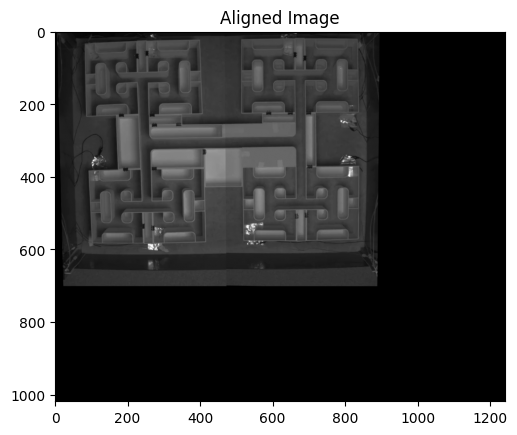

In [16]:
# Load the transformation matrix from a .npy file
transformation_matrix = np.load('/var/home/almogmeir/Documents/M.Sc/Project/Input/calibration_files/transform_matrix.npy')

# Apply the transformation to align the image
# If the matrix is 2x3 (affine), use warpAffine; if 3x3 (homography), use warpPerspective
if transformation_matrix.shape == (2, 3):
    aligned_dst = cv2.warpAffine(img, transformation_matrix, (img.shape[1], img.shape[0]))
elif transformation_matrix.shape == (3, 3):
    aligned_dst = cv2.warpPerspective(img, transformation_matrix, (img.shape[1], img.shape[0]))
else:
    raise ValueError("Transformation matrix must be 2x3 (affine) or 3x3 (homography).")

plt.imshow(aligned_dst, cmap='gray')
plt.title('Aligned Image')
plt.show()

In [17]:
aligned_dst = rotate(dst, -1.7)
aligned_img = rotate(img, -1.7)

In [18]:
aligned_dst = img
aligned_img = img

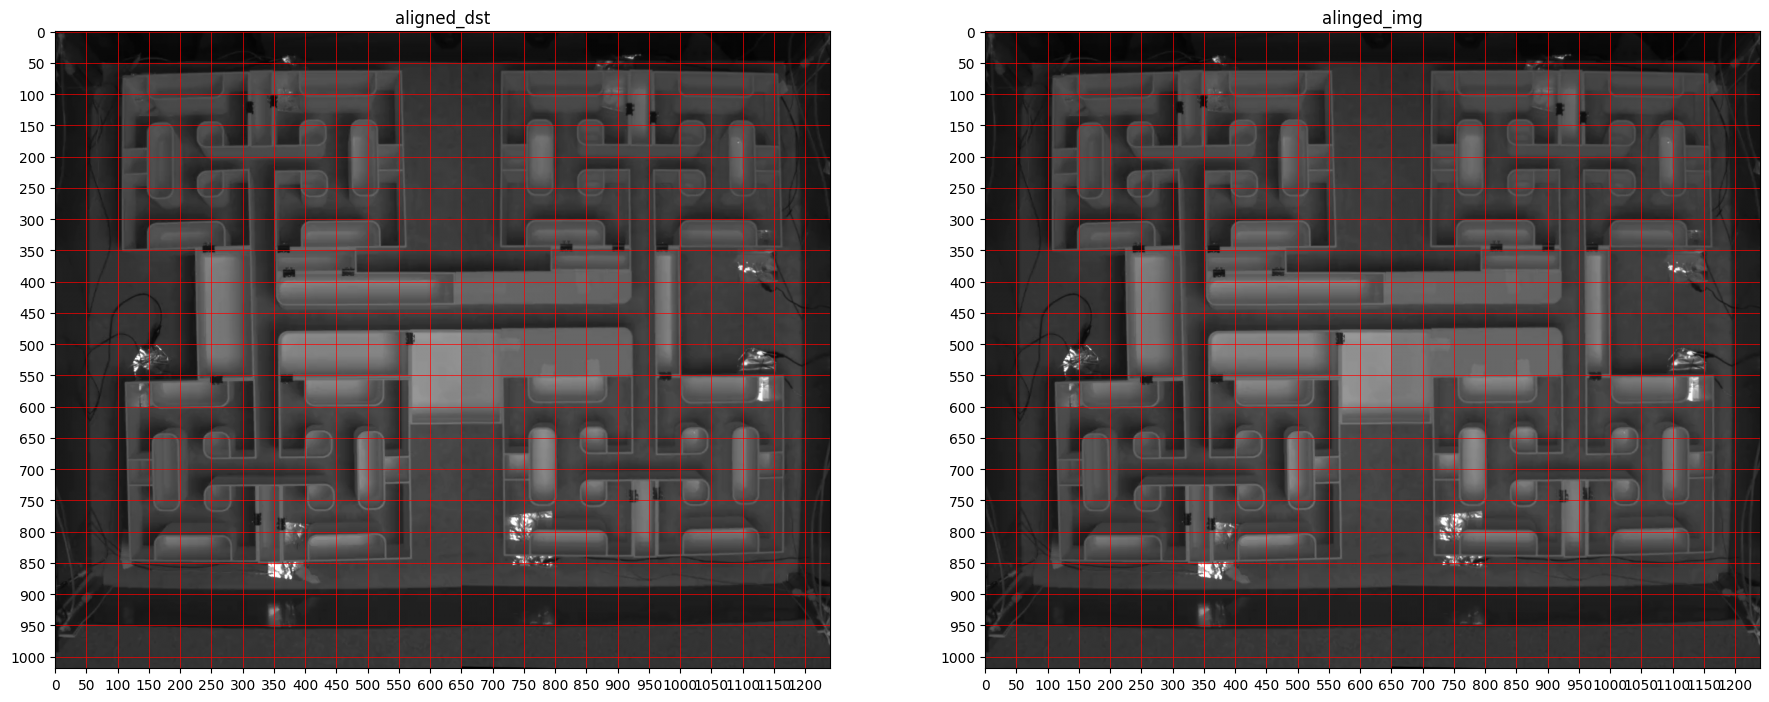

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(22, 11))

# Display 'img' image
axes[1].imshow(aligned_img, cmap='gray')
axes[1].set_title('alinged_img')
axes[1].grid(which='major', axis='both', linestyle='-', color='r', linewidth=0.5)
axes[1].set_xticks(np.arange(0, aligned_img.shape[1], 50))
axes[1].set_yticks(np.arange(0, aligned_img.shape[0], 50))
# Display 'dst' image
axes[0].imshow(aligned_dst, cmap='gray')
axes[0].set_title('aligned_dst')
axes[0].grid(which='major', axis='both', linestyle='-', color='r', linewidth=0.5)
axes[0].set_xticks(np.arange(0, aligned_dst.shape[1], 50))
axes[0].set_yticks(np.arange(0, aligned_dst.shape[0], 50))


plt.show()

In [20]:
# Create a FastLineDetector object
fld = cv2.ximgproc.createFastLineDetector(length_threshold = 9)
# Detect lines in the image
lines = fld.detect(aligned_dst)

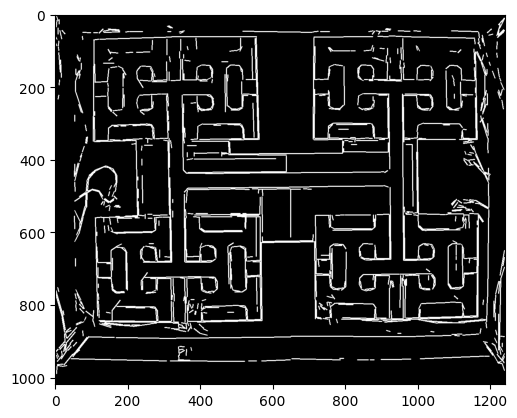

In [21]:
#Create blank image the size of aligned_dst
blank_image_for_dilate = np.zeros_like(aligned_dst)

# Draw the lines on the blank image
for line in lines:
    x0, y0, x1, y1 = map(int, line[0])
    cv2.line(blank_image_for_dilate, (x0, y0), (x1, y1), (255, 255, 255), 2)

# Display the image with detected lines
# Invert blank_image colors
blank_image = cv2.bitwise_not(blank_image_for_dilate)

plt.imshow(blank_image_for_dilate, cmap='gray')

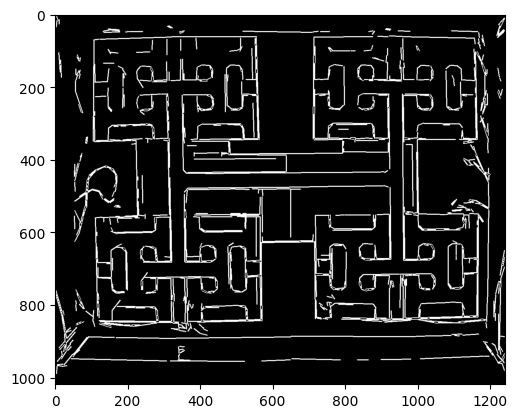

In [22]:
# Find contours in the image
contours, _ = cv2.findContours(blank_image_for_dilate, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)

# Iterate through the contours
for contour in contours:
    # Calculate the area of the contour
    area = cv2.contourArea(contour)

    # If the area is less than X pixels, remove the artifact
    if area < 50:
        cv2.drawContours(blank_image_for_dilate, [contour], -1, (0, 0, 0), -1)  # Fill the contour with white

# Display the image with artifacts removed
plt.imshow(blank_image_for_dilate, cmap='gray')

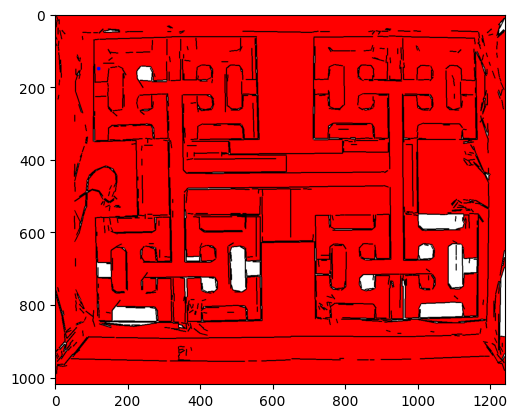

In [23]:
# Convert the blank image to a color image
blank_image_color = cv2.cvtColor(blank_image, cv2.COLOR_GRAY2BGR)

# Define the seed point and color
seed_point = (120, 150)
color = (255, 0, 0)  # Blue in BGR

# Flood fill the image
cv2.floodFill(blank_image_color, None, seed_point, color)
# Draw the seed point with red point
cv2.circle(blank_image_color, seed_point, 5, (0, 0, 255), -1)
# Display or save the image
plt.imshow(blank_image_color)

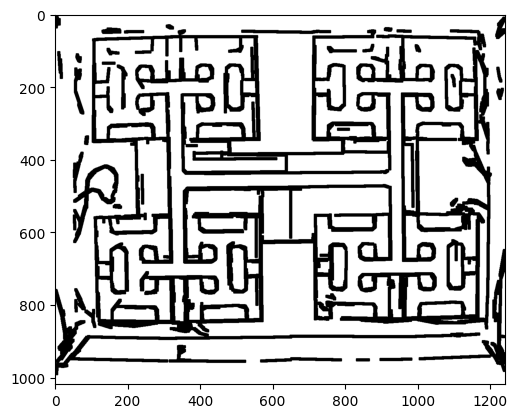

In [24]:
kernel_dilate = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7)) #(9, 9) for maze1, (7, 7) for maze2
dilated_black = cv2.morphologyEx(blank_image_for_dilate, cv2.MORPH_DILATE, kernel_dilate)
# Invert Dilated colors
dilated = cv2.bitwise_not(dilated_black)

plt.imshow(dilated, cmap='gray')

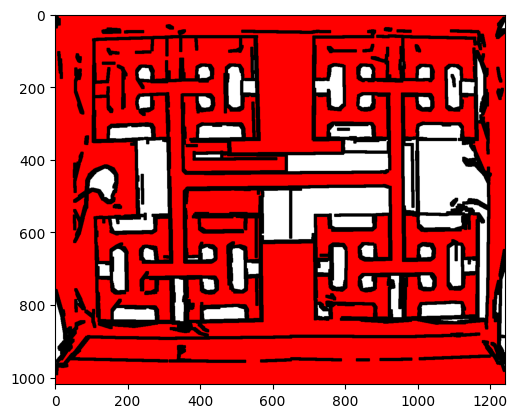

In [25]:
# Convert the blank image to a color image
dilated_image_color = cv2.cvtColor(dilated, cv2.COLOR_GRAY2BGR)

# Define the seed point and color
seed_point = (120, 150)
color = (255, 0, 0)  # Blue in BGR

# Flood fill the image
cv2.floodFill(dilated_image_color, None, seed_point, color)
# Draw the seed point with red point
# cv2.circle(dilated_image_color, seed_point, 5, (0, 0, 255), -1)
# Display or save the image
plt.imshow(dilated_image_color)

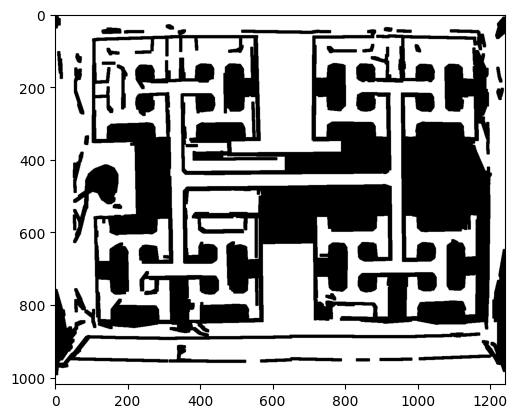

In [26]:
# Change black pixels to white in dilated_image_color
dilated_image_color[np.where((dilated_image_color == [0, 0, 0]).all(axis=2))] = [255, 255, 255]

# Convert the color image back to grayscale
dilated_image_gray = cv2.cvtColor(dilated_image_color, cv2.COLOR_BGR2GRAY)

# Threshold the image to binary
_, thresholded_image = cv2.threshold(dilated_image_gray, 127, 255, cv2.THRESH_BINARY)

# Invert thresholded_image
thresholded_image = cv2.bitwise_not(thresholded_image)

# Smooth edges
blurred = cv2.GaussianBlur(thresholded_image, (11, 11), 0)
_, refined_binary = cv2.threshold(blurred, 128, 255, cv2.THRESH_BINARY)

# Display the skeletonized image
plt.imshow(thresholded_image, cmap='gray')  

# **Part 2 - Pattern Matching**

In [27]:
# Load the image
pattern = cv2.imread('/var/home/almogmeir/Documents/M.Sc/Project/pattern.png', cv2.IMREAD_GRAYSCALE)
pattern_cut = cv2.imread('/var/home/almogmeir/Documents/M.Sc/Project/pattern_cut.png', cv2.IMREAD_GRAYSCALE)

kernel = np.ones((3, 3), np.uint8)

# Threshold the image to create a binary image
_, pattern_binary = cv2.threshold(pattern, 127, 255, cv2.THRESH_BINARY_INV)
_, pattern_cut_binary = cv2.threshold(pattern_cut, 127, 255, cv2.THRESH_BINARY_INV)


pattern_dilated_binary = cv2.dilate(pattern_cut_binary, kernel, iterations=1)
_, pattern_dilated_binary = cv2.threshold(pattern_dilated_binary, 127, 255, cv2.THRESH_BINARY)


# Resize the image to 218 pixels height, currently fixed but will be according
# to the affine transformation
height = 218
width = int(pattern_binary.shape[1] * height / pattern_binary.shape[0])
pattern_binary = cv2.resize(pattern_binary, (width, height), interpolation=cv2.INTER_AREA)
pattern_dilated_binary = cv2.resize(pattern_dilated_binary, (width, height), interpolation=cv2.INTER_AREA)


rotations = []
rotations_dilated = []

for angle in range(0, 360, 90):
  rotations.append(rotate(pattern_binary, angle, reshape=True))
  # Dilate the pattern a bit to make the lines stronger
  rotations_dilated.append(rotate(pattern_dilated_binary, angle, reshape=True))


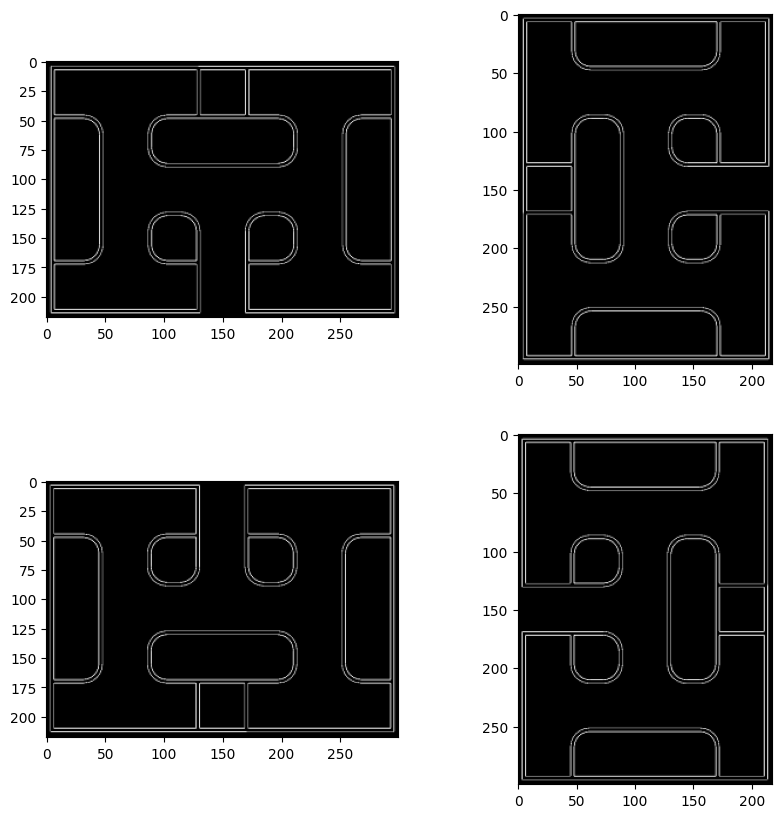

In [28]:
# Display the 4 rotations with plt
plt.figure(figsize=(10, 10))



for i in range(len(rotations)):
  plt.subplot(2, 2, i + 1)
  plt.imshow(rotations[i], cmap='gray')

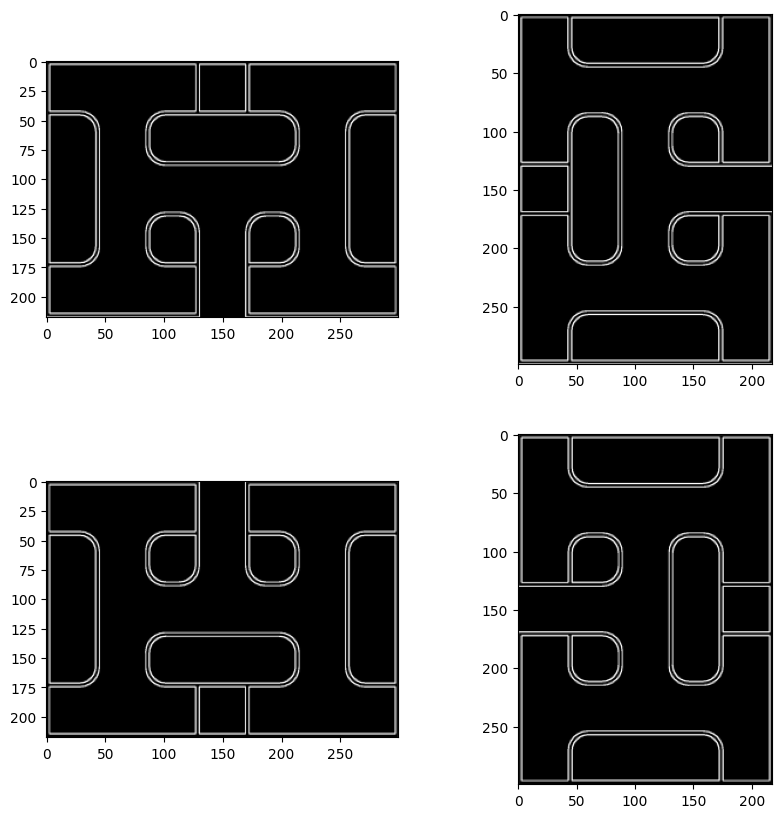

In [29]:
# Display the 4 rotations with plt
plt.figure(figsize=(10, 10))



for i in range(len(rotations_dilated)):
  plt.subplot(2, 2, i + 1)
  plt.imshow(rotations_dilated[i], cmap='gray')

In [30]:
pattern_binary.shape

(218, 300)

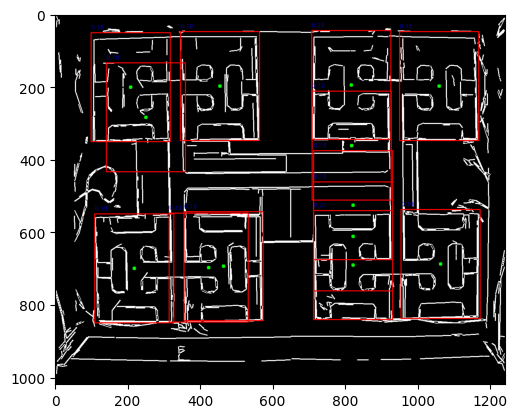

In [31]:
def get_overlap_count(matches, match, template_shape):
    """
    Count how many existing matches overlap with the given match.

    Args:
        matches: List of top-left corners of matches.
        match: Top-left corner of the match to check.
        template_shape: Shape of the template (height, width).

    Returns:
        The number of matches that overlap with the given match.
    """
    new_rect = [match[0], match[1], match[0] + template_shape[1], match[1] + template_shape[0]]
    overlap_count = 0

    for existing in matches:
        existing_rect = [existing[0], existing[1], existing[0] + template_shape[1], existing[1] + template_shape[0]]
        # Check if rectangles overlap
        if not (new_rect[2] <= existing_rect[0] or  # new right <= existing left
                new_rect[0] >= existing_rect[2] or  # new left >= existing right
                new_rect[3] <= existing_rect[1] or  # new bottom <= existing top
                new_rect[1] >= existing_rect[3]):   # new top >= existing bottom
            overlap_count += 1

    return overlap_count

def filter_close_points(points, distance_threshold, min_samples=2):
    """
    Remove points that are closer than the distance_threshold and exclude clusters smaller than min_samples.

    Args:
        points: List of (x, y) tuples representing locations.
        distance_threshold: Minimum allowable distance between points (for clustering).
        min_samples: Minimum number of points in a cluster to keep it.

    Returns:
        Filtered list of points.
    """
    if len(points) == 0:
        return []

    # Convert points to numpy array
    points_array = np.array(points)

    # Apply DBSCAN clustering
    clustering = DBSCAN(eps=distance_threshold, min_samples=min_samples).fit(points_array)

    # Filter points: Keep clusters with at least min_samples points
    filtered_points = []
    for cluster_label in set(clustering.labels_):
        if cluster_label == -1:
            continue  # Ignore noise (label -1)

        # Get all points in this cluster
        cluster_points = points_array[clustering.labels_ == cluster_label]

        # Only process clusters with enough points
        if len(cluster_points) >= min_samples:
            # Remove points that are too close within the cluster
            cluster_filtered = []
            for pt in cluster_points:
                if all(np.linalg.norm(pt - np.array(fp)) > distance_threshold for fp in cluster_filtered):
                    cluster_filtered.append(pt)
            filtered_points.extend(cluster_filtered)

    # Convert to list of tuples
    return [tuple(pt) for pt in filtered_points]


def filter_close_points_post(points, distance_threshold):
    """
    Remove points that are closer than the distance_threshold.

    Args:
        points: List of (x, y) tuples representing locations.
        distance_threshold: Minimum allowable distance between points.

    Returns:
        Filtered list of points.
    """
    filtered_points = []
    for pt in points:
        # Check if this point is far enough from all already-kept points
        if all(np.linalg.norm(np.array(pt) - np.array(fp)) > distance_threshold for fp in filtered_points):
            filtered_points.append(pt)
    return filtered_points


def match_template(img, template):
    result = cv2.matchTemplate(img, template, cv2.TM_CCOEFF_NORMED)
    return result

# Clone blank_image_for_dilate to preserve the original
matches = blank_image_for_dilate.copy()
distance_threshold = 30

for template in rotations:
    res = match_template(matches, template)
    loc = np.where(res >= 0.18)  # Adjust the threshold as needed
    # Create a list of (x, y) points from loc
    points = list(zip(*loc[::-1]))

    # Filter points to remove close duplicates
    filtered_points = filter_close_points(points, distance_threshold, 10)

    # Convert to RGB for drawing (after template matching)
    matches_rgb = cv2.cvtColor(matches, cv2.COLOR_GRAY2RGB)

    # Draw points in the center of the matched regions
    for pt in filtered_points:
        # print(f"Drawing at: {pt}")
        cv2.circle(matches_rgb, (pt[0] + template.shape[1] // 2, pt[1] + template.shape[0] // 2), 5, (0, 255, 0), -1)

    # Draw rectangles around the matched regions
    for pt in filtered_points:
        top_left = pt
        bottom_right = (pt[0] + template.shape[1], pt[1] + template.shape[0])
        # print(f"Rectangle: {top_left} to {bottom_right}")
        cv2.rectangle(matches_rgb, top_left, bottom_right, (255, 0, 0), 2)

        # Add probability text
        probability = res[pt[1], pt[0]]
        cv2.putText(matches_rgb, f"{probability:.2f}", (pt[0], pt[1] - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)

plt.imshow(matches_rgb)

points: [(np.int64(753), np.int64(584)), (np.int64(752), np.int64(585)), (np.int64(753), np.int64(585)), (np.int64(753), np.int64(586)), (np.int64(753), np.int64(587)), (np.int64(148), np.int64(592)), (np.int64(149), np.int64(592)), (np.int64(150), np.int64(592)), (np.int64(151), np.int64(592)), (np.int64(148), np.int64(593)), (np.int64(149), np.int64(593)), (np.int64(150), np.int64(593)), (np.int64(151), np.int64(593)), (np.int64(148), np.int64(594)), (np.int64(149), np.int64(594)), (np.int64(150), np.int64(594)), (np.int64(151), np.int64(594)), (np.int64(149), np.int64(595))]
points: [(np.int64(704), np.int64(46)), (np.int64(705), np.int64(46)), (np.int64(706), np.int64(46)), (np.int64(707), np.int64(46)), (np.int64(708), np.int64(46)), (np.int64(709), np.int64(46)), (np.int64(704), np.int64(47)), (np.int64(705), np.int64(47)), (np.int64(706), np.int64(47)), (np.int64(707), np.int64(47)), (np.int64(708), np.int64(47)), (np.int64(709), np.int64(47)), (np.int64(703), np.int64(48)), (np

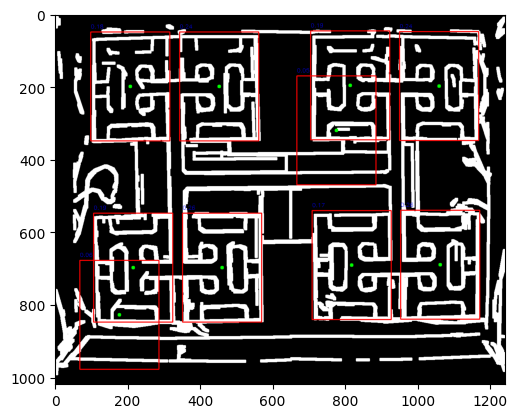

In [32]:
# Clone blank_image_for_dilate to preserve the original
matches = dilated_black.copy()
distance_threshold = 20
filtered_points = []

for i, template in enumerate(rotations):
    res = match_template(matches, template)
    loc = np.where(res >= 0.23)  # Adjust the threshold as needed
    # Create a list of (x, y) points from loc
    points = list(zip(*loc[::-1]))
    print(f'points: {points}')

    # Filter points to remove close duplicates
    curr_filtered_points = filter_close_points(points, distance_threshold, 10)
    filtered_points.extend(curr_filtered_points)

print(f'filtered points length: {len(filtered_points)}')
print(f'filtered points: {filtered_points}')

filtered_points = filter_close_points_post(filtered_points, 10)
print(f'filtered points length: {len(filtered_points)}')
print(f'filtered points: {filtered_points}')

# # Remove matches that overlap with 2 or more other matches
final_matches = []
for m in filtered_points:
  overlap_count = get_overlap_count(filtered_points, m, template.shape)
  # print(f'overlap count is: {overlap_count}')
  if overlap_count < 4:  # Keep matches with less than 3 overlaps
      final_matches.append(m)
print(f'final matches length: {len(final_matches)}')
print(f'final matches: {final_matches}')
# Convert to RGB for drawing
matches_rgb = cv2.cvtColor(matches, cv2.COLOR_GRAY2RGB)

# Draw points in the center of the matched regions
for pt in final_matches:
    # print(f"Drawing at: {pt}")
    cv2.circle(matches_rgb, (pt[0] + template.shape[1] // 2, pt[1] + template.shape[0] // 2), 5, (0, 255, 0), -1)

# Draw rectangles around the matched regions
for pt in final_matches:
    top_left = pt
    bottom_right = (pt[0] + template.shape[1], pt[1] + template.shape[0])
    # print(f"Rectangle: {top_left} to {bottom_right}")
    cv2.rectangle(matches_rgb, top_left, bottom_right, (255, 0, 0), 2)

    # Add probability text
    probability = res[pt[1], pt[0]]
    cv2.putText(matches_rgb, f"{probability:.2f}", (pt[0], pt[1] - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)

plt.imshow(matches_rgb)

points: [(np.int64(705), np.int64(172)), (np.int64(706), np.int64(172)), (np.int64(707), np.int64(172)), (np.int64(708), np.int64(172)), (np.int64(753), np.int64(583)), (np.int64(750), np.int64(584)), (np.int64(751), np.int64(584)), (np.int64(752), np.int64(584)), (np.int64(753), np.int64(584)), (np.int64(754), np.int64(584)), (np.int64(755), np.int64(584)), (np.int64(832), np.int64(584)), (np.int64(750), np.int64(585)), (np.int64(751), np.int64(585)), (np.int64(752), np.int64(585)), (np.int64(753), np.int64(585)), (np.int64(754), np.int64(585)), (np.int64(755), np.int64(585)), (np.int64(750), np.int64(586)), (np.int64(751), np.int64(586)), (np.int64(752), np.int64(586)), (np.int64(753), np.int64(586)), (np.int64(754), np.int64(586)), (np.int64(755), np.int64(586)), (np.int64(752), np.int64(587)), (np.int64(753), np.int64(587)), (np.int64(753), np.int64(588)), (np.int64(148), np.int64(591)), (np.int64(149), np.int64(591)), (np.int64(150), np.int64(591)), (np.int64(151), np.int64(591)),

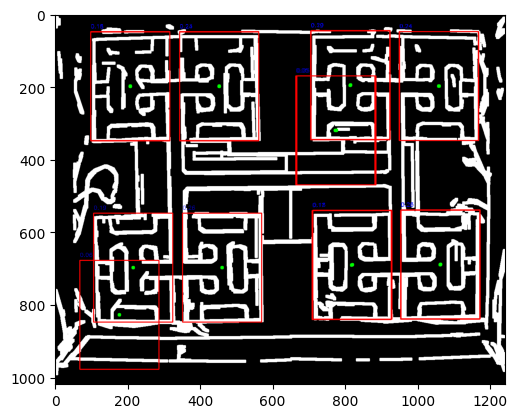

In [33]:
# Clone blank_image_for_dilate to preserve the original
matches = dilated_black.copy()
distance_threshold = 20
filtered_points = []

for template in rotations:
    res = match_template(matches, template)
    loc = np.where(res >= 0.22)  # Adjust the threshold as needed
    # Create a list of (x, y) points from loc
    points = list(zip(*loc[::-1]))
    print(f'points: {points}')

    # Filter points to remove close duplicates
    curr_filtered_points = filter_close_points(points, distance_threshold, 10)
    filtered_points.extend(curr_filtered_points)
    print(f'curr filtered points length: {len(curr_filtered_points)}')

print(f'filtered points length: {len(filtered_points)}')
print(f'filtered points: {filtered_points}')

filtered_points = filter_close_points_post(filtered_points, 10)
print(f'filtered points length: {len(filtered_points)}')
print(f'filtered points: {filtered_points}')

# # Remove matches that overlap with 2 or more other matches
final_matches = []
for m in filtered_points:
  overlap_count = get_overlap_count(filtered_points, m, template.shape)
  # print(f'overlap count is: {overlap_count}')
  if overlap_count < 4:  # Keep matches with less than 3 overlaps
      final_matches.append(m)
print(f'final matches length: {len(final_matches)}')
print(f'final matches: {final_matches}')
# Convert to RGB for drawing
# matches_rgb = cv2.cvtColor(matches, cv2.COLOR_GRAY2RGB)

# Draw points in the center of the matched regions
for pt in final_matches:
    # print(f"Drawing at: {pt}")
    cv2.circle(matches_rgb, (pt[0] + template.shape[1] // 2, pt[1] + template.shape[0] // 2), 5, (0, 255, 0), -1)

# Draw rectangles around the matched regions
for pt in final_matches:
    top_left = pt
    bottom_right = (pt[0] + template.shape[1], pt[1] + template.shape[0])
    # print(f"Rectangle: {top_left} to {bottom_right}")
    cv2.rectangle(matches_rgb, top_left, bottom_right, (255, 0, 0), 2)

    # Add probability text
    probability = res[pt[1], pt[0]]
    cv2.putText(matches_rgb, f"{probability:.2f}", (pt[0], pt[1] - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)

plt.imshow(matches_rgb)

Points for template 0: [(np.int64(753), np.int64(584), 0), (np.int64(752), np.int64(585), 0), (np.int64(753), np.int64(585), 0), (np.int64(753), np.int64(586), 0), (np.int64(753), np.int64(587), 0), (np.int64(148), np.int64(592), 0), (np.int64(149), np.int64(592), 0), (np.int64(150), np.int64(592), 0), (np.int64(151), np.int64(592), 0), (np.int64(148), np.int64(593), 0), (np.int64(149), np.int64(593), 0), (np.int64(150), np.int64(593), 0), (np.int64(151), np.int64(593), 0), (np.int64(148), np.int64(594), 0), (np.int64(149), np.int64(594), 0), (np.int64(150), np.int64(594), 0), (np.int64(151), np.int64(594), 0), (np.int64(149), np.int64(595), 0)]
Current filtered points length (template 0): 1
Points for template 1: [(np.int64(704), np.int64(46), 1), (np.int64(705), np.int64(46), 1), (np.int64(706), np.int64(46), 1), (np.int64(707), np.int64(46), 1), (np.int64(708), np.int64(46), 1), (np.int64(709), np.int64(46), 1), (np.int64(704), np.int64(47), 1), (np.int64(705), np.int64(47), 1), (np

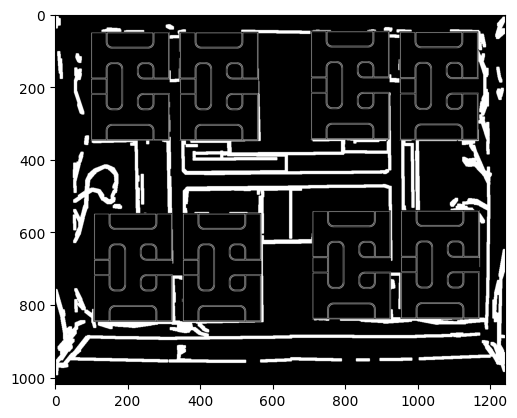

In [34]:
# Clone blank_image_for_dilate to preserve the original
matches = dilated_black.copy()
patterns_drawn = dilated_black.copy()
distance_threshold = 20
filtered_points_with_template = []

for template_index, template in enumerate(rotations):
    res = match_template(matches, template)
    loc = np.where(res >= 0.23)  # Adjust the threshold as needed
    # Create a list of (x, y, template_index) tuples
    points_with_template = [(x, y, template_index) for x, y in zip(*loc[::-1])]
    print(f'Points for template {template_index}: {points_with_template}')

    # Filter points to remove close duplicates
    curr_filtered_points_with_template = filter_close_points(
        points_with_template, distance_threshold, 10
    )
    filtered_points_with_template.extend(curr_filtered_points_with_template)
    print(f'Current filtered points length (template {template_index}): {len(curr_filtered_points_with_template)}')

print(f'Total filtered points length: {len(filtered_points_with_template)}')
print(f'Total filtered points: {filtered_points_with_template}')

# Perform post-filtering to remove very close matches
filtered_points_with_template = filter_close_points_post(
    filtered_points_with_template, 10
)
print(f'Post-filtered points length: {len(filtered_points_with_template)}')
print(f'Post-filtered points: {filtered_points_with_template}')

# Remove matches that overlap with 2 or more other matches
final_matches_with_template = []
for match in filtered_points_with_template:
    x, y, template_index = match
    overlap_count = get_overlap_count(
        [(m[0], m[1]) for m in filtered_points_with_template], (x, y), rotations[template_index].shape
    )
    if overlap_count < 4:  # Keep matches with less than 4 overlaps
        final_matches_with_template.append(match)
print(f'Final matches length: {len(final_matches_with_template)}')
print(f'Final matches: {final_matches_with_template}')

# Replace the corresponding parts in the image with the correct rotation of the template
for x, y, template_index in final_matches_with_template[:-1]:
    template = rotations_dilated[template_index]
    h, w = template.shape
    # Replace the region in the patterns_drawn image with the rotated template
    patterns_drawn[y:y + h, x:x + w] = template
    print(f'Placed template {template_index} at ({x}, {y})')

# Display the result
plt.imshow(patterns_drawn, cmap='gray')

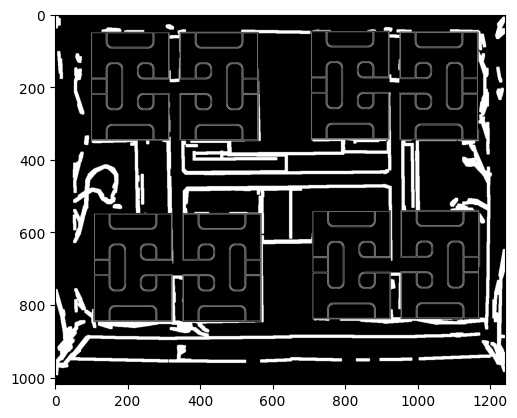

In [35]:
# Manual fix of patterns_drawn for maze1, treshold 0.23

# # Replace template 1 at (379, 540) with template 3
# patterns_drawn[540:540 + 300, 379:379 + 218] = rotations_dilated[3]
# # Replace template 1 at (899, 540) with template 3
# patterns_drawn[540:540 + 300, 899:899 + 218] = rotations_dilated[3]
# # Display the result
# plt.imshow(patterns_drawn, cmap='gray')

# Manual fix of patterns_drawn for maze2, treshold 0.205

# # Replace template 1 at (1010, 182) with template 3
# patterns_drawn[182:182 + 300, 1010:1010 + 218] = rotations_dilated[3]
# # Replace template 1 at (1008, 579)with template 3
# patterns_drawn[579:579 + 300, 1008:1008 + 218] = rotations_dilated[3]

# # (376, 185)
# patterns_drawn[185:185 + 300, 376:376 + 218] = rotations_dilated[3]

# Manual fix for maze3 (stotched_image), threshold 0.21

# Replace template 1 at (309, 72) with template 3
# patterns_drawn[72:72 + 300, 309:309 + 218] = rotations_dilated[3]

# # Replace template 1 at (910, 86) with template 3
# patterns_drawn[86:86 + 300, 910:910 + 218] = rotations_dilated[3]

# # Replace template 1 at (310, 567) with template 3
# patterns_drawn[567:567 + 300, 310:310 + 218] = rotations_dilated[3]

# # Replace template 1 at (921, 574) with template 3
# patterns_drawn[574:574 + 300, 921:921 + 218] = rotations_dilated[3]

# Manual fix for maze4 (stitched_image2), threshold 0.21
# Replace template 1 at (949, 48) with template 3
patterns_drawn[48:48 + 300, 949:949 + 218] = rotations_dilated[3]
# Replace template 1 at (343, 49) with template 3
patterns_drawn[49:49 + 300, 343:343 + 218] = rotations_dilated[3]
# Replace template 1 at (952, 540) with template 3
patterns_drawn[540:540 + 300, 952:952 + 218] = rotations_dilated[3]
# Replace template 1 at (351, 548) with template 3
patterns_drawn[548:548 + 300, 351:351 + 218] = rotations_dilated[3]


# Draw a black rectangle between (340, 570) and (360, 570) (open clogged path)
# cv2.rectangle(patterns_drawn, (340, 570), (371, 572), (0, 0, 0), -1)

# Export the image
cv2.imwrite('/var/home/almogmeir/Documents/M.Sc/Project/patterns_drawn.png', patterns_drawn)

plt.imshow(patterns_drawn, cmap='gray')



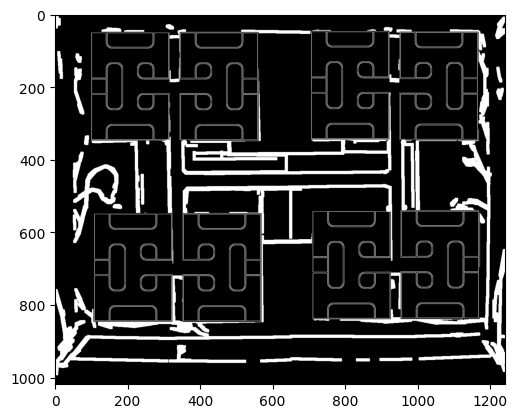

In [9]:
# Import the fixed image
patterns_drawn = cv2.imread('/var/home/almogmeir/Documents/M.Sc/Project/patterns_drawn_fixed_stitched2.png', cv2.IMREAD_GRAYSCALE)

# patterns_drawn = cv2.imread('/var/home/almogmeir/Documents/M.Sc/Project/maze3.png', cv2.IMREAD_GRAYSCALE)

plt.imshow(patterns_drawn, cmap='gray')



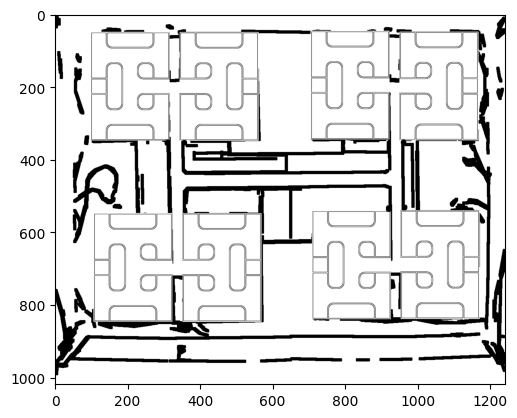

In [10]:
# Define the seed point and color
# seed_point = (100, 180) # maze3
seed_point = (120, 150) # maze2
color = (255, 0, 0)  # Blue in BGR

# Invert Dilated colors
patterns_drawn_inverted = cv2.bitwise_not(patterns_drawn)
# Convert the blank image to a color image
patterns_drawn_color = cv2.cvtColor(patterns_drawn_inverted, cv2.COLOR_GRAY2BGR)
plt.imshow(patterns_drawn_color)

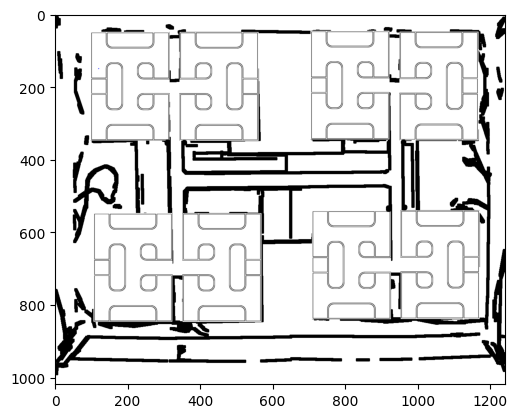

In [13]:
# Draw the seed point on patterns_drawn_color in red
cv2.circle(patterns_drawn_color, seed_point, 1, (0, 0, 255), -1)
plt.imshow(patterns_drawn_color)

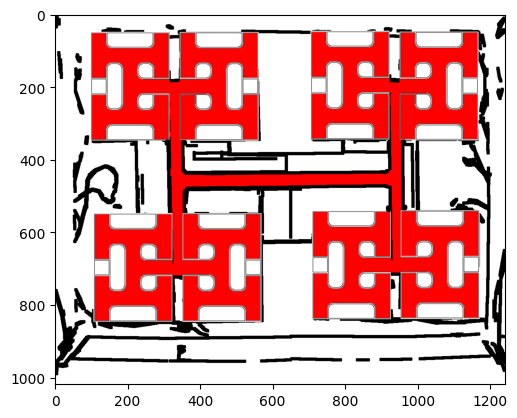

In [11]:
# Flood fill the image
cv2.floodFill(patterns_drawn_color, None, seed_point, color)
# Draw the seed point with red point
# cv2.circle(dilated_image_color, seed_point, 5, (0, 0, 255), -1)
# Display or save the image
plt.imshow(patterns_drawn_color)

# Part 3 - Tiling & Graph extraction

In [12]:
def is_tile_blue(tile, threshold=0.5):
    """
    Determine if a tile is mostly blue.

    Parameters:
    - tile: Numpy array representing the tile.
    - threshold: Proportion of blue pixels required to label the tile as part of the graph.

    Returns:
    - True if the tile is mostly blue, False otherwise.
    """
    # Calculate the proportion of blue pixels
    blue_pixels = (tile[:, :, 2] > 150) & (tile[:, :, 2] > tile[:, :, 1]) & (tile[:, :, 2] > tile[:, :, 0])
    proportion_blue = np.sum(blue_pixels) / (tile.shape[0] * tile.shape[1])
    return proportion_blue > threshold

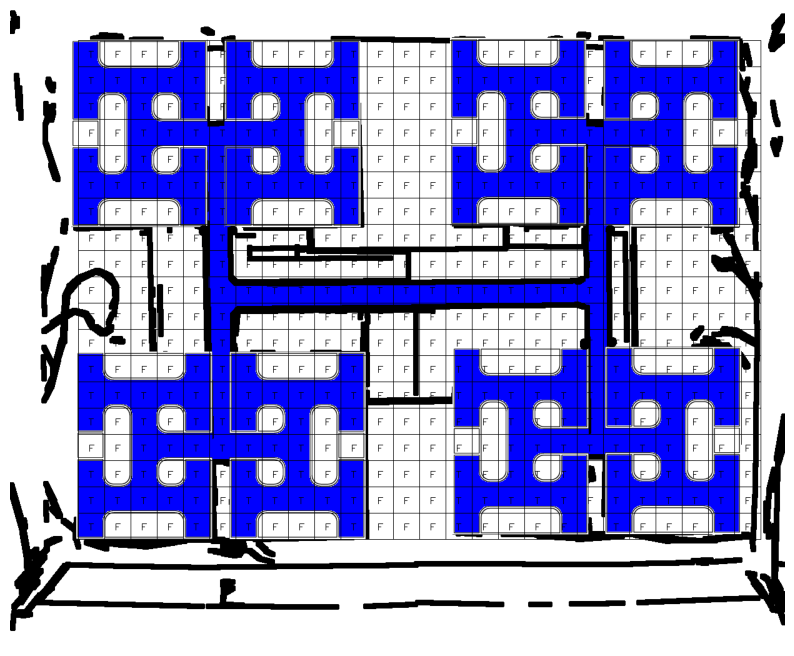

In [13]:
def label_maze_with_text(image, tile_size=42, threshold=0.45, maze_borders=None):
    """
    Split the maze image into tiles, label them, and visualize the result with text labels.

    Parameters:
    - image_path: Path to the maze image.
    - tile_size: Size of each tile (tile_size x tile_size).
    - threshold: Proportion of blue pixels to determine if a tile is part of the graph.
    - maze_borders: List of 4 coordinates [x_min, y_min, x_max, y_max] defining the borders of the maze.
    """
    # Load image
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB
    height, width, _ = image.shape

    # Create a copy of the image for visualization
    labeled_image = image.copy()

    # Define maze boundaries
    if maze_borders:
        x_min, y_min, x_max, y_max = maze_borders
    else:
        x_min, y_min, x_max, y_max = 0, 0, width, height

    for y in range(y_min, y_max, tile_size):
        for x in range(x_min, x_max, tile_size):
            tile = image[y:y+tile_size, x:x+tile_size]
            if tile.shape[0] == tile_size and tile.shape[1] == tile_size:  # Ensure full tile
                is_graph = is_tile_blue(tile, threshold)
                label = "T" if is_graph else "F"

                # Put label text on the tile
                font_scale = 0.5
                thickness = 1
                # color = (0, 255, 0) if is_graph else (255, 0, 0)  # Green for graph, Red for not graph
                text_size = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)[0]
                text_x = x + (tile_size - text_size[0]) // 2
                text_y = y + (tile_size + text_size[1]) // 2

                cv2.putText(labeled_image, label, (text_x, text_y), cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 0, 0), thickness)
                # add border to the tile
                cv2.rectangle(labeled_image, (x, y), (x+tile_size, y+tile_size), (0, 0, 0), 1)

    # Display the result
    plt.figure(figsize=(10, 10))
    plt.imshow(labeled_image)
    plt.axis("off")
    plt.show()

# Usage
# maze1_borders = [130, 203, 1116, 837]
# label_maze_with_text(patterns_drawn_color, maze_borders=maze1_borders)

# maze2_borders = [120, 190, 1216, 844]
# label_maze_with_text(patterns_drawn_color, maze_borders=maze2_borders)

# maze3_borders = [67, 73, 1134, 867]
# label_maze_with_text(patterns_drawn_color, maze_borders=maze3_borders)

maze4_borders = [109, 50, 1170, 840]
label_maze_with_text(patterns_drawn_color, maze_borders=maze4_borders)

In [14]:
def get_maze_tiles(image, tile_size=42, threshold=0.45, maze_borders=None):
    """
    Split the maze image into tiles, return list of tiles that are part of the graph.

    """

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB
    height, width, _ = image.shape

    # Define maze boundaries
    if maze_borders:
        x_min, y_min, x_max, y_max = maze_borders
    else:
        x_min, y_min, x_max, y_max = 0, 0, width, height

    graph_tiles = []
    for y in range(y_min, y_max, tile_size):
        for x in range(x_min, x_max, tile_size):
            tile = image[y:y+tile_size, x:x+tile_size]
            if tile.shape[0] == tile_size and tile.shape[1] == tile_size:  # Ensure full tile
                is_graph = is_tile_blue(tile, threshold)
                # (coordinates, is_graph, borders[right,down,left,up])
                # Append tile data as a dictionary
                graph_tiles.append({
                    'coordinates': (x // tile_size, y // tile_size),
                    'is_graph': is_graph,
                    'borders': [False, False, False, False]
                })
    graph_tiles = pd.DataFrame(graph_tiles)
    graph_tiles = graph_tiles.sort_values(by=['coordinates'], key=lambda col: col.apply(lambda x: (x[0], x[1])))
    # Re-index the df
    graph_tiles = graph_tiles.reset_index(drop=True)

    return graph_tiles

In [15]:
# maze1_borders = [130, 203, 1116, 837]
tiles = get_maze_tiles(patterns_drawn_color, maze_borders=maze4_borders)
tiles
#'borders': {'right':False, 'down':False, 'left':False, 'up':False}

,coordinates,is_graph,borders
0,"(2, 1)",True,"[False, False, False, False]"
1,"(2, 2)",True,"[False, False, False, False]"
2,"(2, 3)",True,"[False, False, False, False]"
3,"(2, 4)",False,"[False, False, False, False]"
4,"(2, 5)",True,"[False, False, False, False]"
...,...,...,...
489,"(27, 15)",False,"[False, False, False, False]"
490,"(27, 16)",False,"[False, False, False, False]"
491,"(27, 17)",False,"[False, False, False, False]"
492,"(27, 18)",False,"[False, False, False, False]"


In [16]:
# Manual fix tile labeling for maze1

# # update tile where coordinates are (25,12), (25,16), (25,10), (25,6) to be a graph tile
# tiles.loc[(tiles['coordinates'] == (25, 12)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (25, 16)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (25, 10)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (25, 6)), 'is_graph'] = True


# # (24, 8), (22, 8), (22,6), (22, 4) are not part of the graph
# tiles.loc[(tiles['coordinates'] == (24, 8)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (22, 8)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (22, 6)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (22, 4)), 'is_graph'] = False

# Manual fix tile labeling for maze2

# # update tile where coordinates are (25,4) to be a graph tile
# tiles.loc[(tiles['coordinates'] == (27, 10)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (27, 6)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (7, 7)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (7, 12)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (22, 14)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (22, 15)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (27, 17)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (27, 13)), 'is_graph'] = True


# tiles.loc[(tiles['coordinates'] == (24, 4)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (24, 8)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (26, 8)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (7, 17)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (7, 18)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (7, 19)), 'is_graph'] = False

# #
# tiles.loc[(tiles['coordinates'] == (7, 4)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (7, 5)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (7, 6)), 'is_graph'] = False


# Manual fix tile labeling for maze3

# tiles.loc[(tiles['coordinates'] == (25, 1)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (19, 1)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (15, 1)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (15, 5)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (15, 5)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (17, 4)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (18, 3)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (16, 3)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (25, 5)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (17, 16)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (15, 13)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (15, 14)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (15, 15)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (15, 17)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (15, 18)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (15, 19)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (17, 15)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (17, 16)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (17, 17)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (19, 13)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (19, 15)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (19, 17)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (19, 19)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (20, 9)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (20, 11)), 'is_graph'] = True
# tiles.loc[(tiles['coordinates'] == (20, 12)), 'is_graph'] = True

# tiles.loc[(tiles['coordinates'] == (18, 5)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (16, 3)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (16, 7)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (16, 13)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (16, 15)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (16, 19)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (18, 3)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (18, 5)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (18, 15)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (18, 17)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (20, 17)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (20, 18)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (20, 19)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (15, 11)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (15, 12)), 'is_graph'] = False
# tiles.loc[(tiles['coordinates'] == (21, 8)), 'is_graph'] = False

# Manual fix tile labeling for maze4

tiles.loc[(tiles['coordinates'] == (17, 13)), 'is_graph'] = False
tiles.loc[(tiles['coordinates'] == (19, 15)), 'is_graph'] = False
tiles.loc[(tiles['coordinates'] == (19, 17)), 'is_graph'] = False
tiles.loc[(tiles['coordinates'] == (16, 15)), 'is_graph'] = True
tiles.loc[(tiles['coordinates'] == (20, 19)), 'is_graph'] = True

In [17]:
def find_and_update_pattern(tiles_df, pattern):
    """
    Given a DataFrame of tiles and a pattern (list of lists), find any occurrence of the pattern,
    horizontally or vertically, in the tiles, and update the borders according to the pattern.

    Args:
    - tiles_df (pd.DataFrame): DataFrame containing tile information with 'coordinates' and 'is_graph' columns.
    - pattern (list of lists): Pattern to find in the tiles.

    Returns:
    - Updated tiles_df.
    """
    pattern_height = len(pattern)
    pattern_width = len(pattern[0])

    # Create a 2D grid from the DataFrame for easy pattern matching
    grid = {}
    for idx, row in tiles_df.iterrows():
        grid[row['coordinates']] = row['is_graph']

    # Function to check for pattern match
    def check_pattern(x, y, pattern, grid):
        for dy in range(len(pattern)):
            for dx in range(len(pattern[0])):
                coord = (x + dx, y + dy)
                if coord not in grid or grid[coord] != pattern[dy][dx]:
                    return False
        return True

    # Function to update borders according to the pattern
    def update_borders(x, y, pattern, tiles_df):
        for dy in range(len(pattern)):
            for dx in range(len(pattern[0])):
                coord = (x + dx, y + dy)
                if pattern[dy][dx]:  # Only update borders for 'True' tiles in the pattern
                    tile_idx = tiles_df[(tiles_df['coordinates'] == coord) & (tiles_df['is_graph'] == True)].index
                    if not tile_idx.empty:
                        borders = [True, True, True, True]  # Initialize all borders to True
                        # Check each direction and update borders
                        if dy == 0 or not pattern[dy - 1][dx]:  # Top border
                            borders[0] = True
                        else:
                            borders[0] = False
                        if dy == len(pattern) - 1 or not pattern[dy + 1][dx]:  # Bottom border
                            borders[2] = True
                        else:
                            borders[2] = False
                        if dx == 0 or not pattern[dy][dx - 1]:  # Left border
                            borders[3] = True
                        else:
                            borders[3] = False
                        if dx == len(pattern[0]) - 1 or not pattern[dy][dx + 1]:  # Right border
                            borders[1] = True
                        else:
                            borders[1] = False
                        
                        # Handle the edge case for the entry point
                        # borders[right,down,left,up])
                        if dy == 3 and all(pattern[i][dx] for i in range(7)):  # Middle row in the column where all 7 tiles are True
                            if pattern == patterns[0]:  # Original pattern
                                borders[2] = False  # No bottom border
                                borders[1] = True  # Right border
                                borders[3] = True  # Left border
                            elif pattern == patterns[1]:  # 90 degrees rotation
                                borders[3] = False  # No left border
                                borders[2] = True  # Bottom border
                                borders[0] = True # Top border
                            elif pattern == patterns[2]:  # 180 degrees rotation
                                borders[0] = False  # No top border
                                borders[1] = True  # Right border
                                borders[3] = True  # Left border
                            elif pattern == patterns[3]:  # 270 degrees rotation
                                borders[1] = False  # No right border
                                borders[2] = True  # Bottom border
                                borders[0] = True # Top border

                        tiles_df.at[tile_idx[0], 'borders'] = borders

    # Function to rotate pattern 90 degrees clockwise
    def rotate_pattern(pattern):
        return [list(row) for row in zip(*pattern[::-1])]

    # Generate all four rotations of the pattern
    patterns = [pattern]
    for _ in range(3):
        patterns.append(rotate_pattern(patterns[-1]))

    # Check for matches for all rotations
    for pat in patterns:
        pat_height = len(pat)
        pat_width = len(pat[0])
        for y in range(tiles_df['coordinates'].apply(lambda x: x[1]).max() - pat_height + 2):
            for x in range(tiles_df['coordinates'].apply(lambda x: x[0]).max() - pat_width + 2):
                if check_pattern(x, y, pat, grid):
                    update_borders(x, y, pat, tiles_df)

    return tiles_df

pattern = [[True, True, True, False, True, True, True],
  [False, True, False, False, False, True, False],
  [False, True, True, True, True, True, False],
  [False, True, False, True, False, True, False],
  [True, True, True, True, True, True, True]]

pattern_height = len(pattern[0])
pattern_width = len(pattern)

test_tiles = find_and_update_pattern(tiles, pattern)
test_tiles

,coordinates,is_graph,borders
0,"(2, 1)",True,"[True, True, False, True]"
1,"(2, 2)",True,"[False, False, False, True]"
2,"(2, 3)",True,"[False, True, True, True]"
3,"(2, 4)",False,"[False, False, False, False]"
4,"(2, 5)",True,"[True, True, False, True]"
...,...,...,...
489,"(27, 15)",False,"[False, False, False, False]"
490,"(27, 16)",False,"[False, False, False, False]"
491,"(27, 17)",False,"[False, False, False, False]"
492,"(27, 18)",False,"[False, False, False, False]"


In [18]:
# Sort test_tiles row by row
test_tile_rows = test_tiles.sort_values(by=['coordinates'], key=lambda col: col.apply(lambda x: (x[1], x[0]))).reset_index(drop=True)

test_tile_rows

,coordinates,is_graph,borders
0,"(2, 1)",True,"[True, True, False, True]"
1,"(3, 1)",False,"[False, False, False, False]"
2,"(4, 1)",False,"[False, False, False, False]"
3,"(5, 1)",False,"[False, False, False, False]"
4,"(6, 1)",True,"[True, True, False, True]"
...,...,...,...
489,"(23, 19)",False,"[False, False, False, False]"
490,"(24, 19)",False,"[False, False, False, False]"
491,"(25, 19)",False,"[False, False, False, False]"
492,"(26, 19)",True,"[False, True, True, True]"


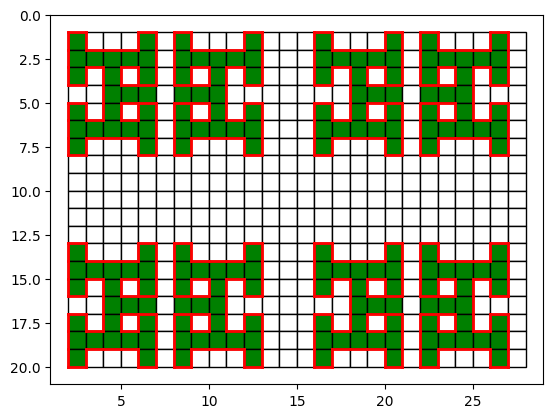

In [19]:
def visualize_tiles(tiles_df):
    """
    Visualize the tiles with green color for graph tiles that are part of the pattern and red borders for tiles in the pattern.

    Args:
    - tiles_df (pd.DataFrame): DataFrame containing tile information with 'coordinates', 'is_graph', and 'borders' columns.
    """
    fig, ax = plt.subplots()
    for idx, row in tiles_df.iterrows():
        x, y = row['coordinates']
        color = 'green' if row['borders'] != [False, False, False, False] else 'white'
        rect = plt.Rectangle((x, y), 1, 1, facecolor=color, edgecolor='black')
        ax.add_patch(rect)
        
        # Draw red borders for tiles in the pattern
        if row['borders'] != [True, True, True, True]:
            if row['borders'][0]:  # Top border
                ax.plot([x, x + 1], [y, y], color='red', linewidth=2)
            if row['borders'][1]:  # Right border
                ax.plot([x + 1, x + 1], [y, y + 1], color='red', linewidth=2)
            if row['borders'][2]:  # Bottom border
                ax.plot([x, x + 1], [y + 1, y + 1], color='red', linewidth=2)
            if row['borders'][3]:  # Left border
                ax.plot([x, x], [y, y + 1], color='red', linewidth=2)
    
    ax.set_xlim(tiles_df['coordinates'].apply(lambda x: x[0]).min() - 1, tiles_df['coordinates'].apply(lambda x: x[0]).max() + 2)
    ax.set_ylim(tiles_df['coordinates'].apply(lambda x: x[1]).min() - 1, tiles_df['coordinates'].apply(lambda x: x[1]).max() + 2)
    ax.set_aspect('equal')
    plt.gca().invert_yaxis()
    plt.show()

visualize_tiles(test_tiles)

In [20]:
def update_borders_based_on_neighbors(tiles_df):
    """
    Traverse the entire tiles_df and for each tile that is in the graph, check for each border that is set to False.
    If the neighboring tiles have a defined border with it, update the corresponding border to True as well.

    Args:
    - tiles_df (pd.DataFrame): DataFrame containing tile information with 'coordinates', 'is_graph', and 'borders' columns.

    Returns:
    - Updated tiles_df.
    """
    # Define the directions for neighbors
    directions = {
        'top': (0, -1),
        'right': (1, 0),
        'bottom': (0, 1),
        'left': (-1, 0)
    }

    # Traverse the entire tiles_df
    for idx, row in tiles_df.iterrows():
        if row['is_graph']:
            x, y = row['coordinates']
            borders = row['borders']

            # Check each direction
            for i, (direction, (dx, dy)) in enumerate(directions.items()):
                if not borders[i]:  # If the border is set to False
                    neighbor_coord = (x + dx, y + dy)
                    neighbor_idx = tiles_df[tiles_df['coordinates'] == neighbor_coord].index
                    if not neighbor_idx.empty:
                        neighbor_borders = tiles_df.at[neighbor_idx[0], 'borders']
                        # Update the corresponding border if the neighbor has a defined border with it
                        if direction == 'top' and neighbor_borders[2]:
                            borders[i] = True
                        elif direction == 'right' and neighbor_borders[3]:
                            borders[i] = True
                        elif direction == 'bottom' and neighbor_borders[0]:
                            borders[i] = True
                        elif direction == 'left' and neighbor_borders[1]:
                            borders[i] = True

            # Update the borders in the DataFrame
            tiles_df.at[idx, 'borders'] = borders

    return tiles_df

test_tiles = update_borders_based_on_neighbors(test_tiles)

In [21]:
width = img.shape[1]
height = img.shape[0]

print(f'Image width: {img_width}, Image height: {img_height}')

NameError: name 'img' is not defined

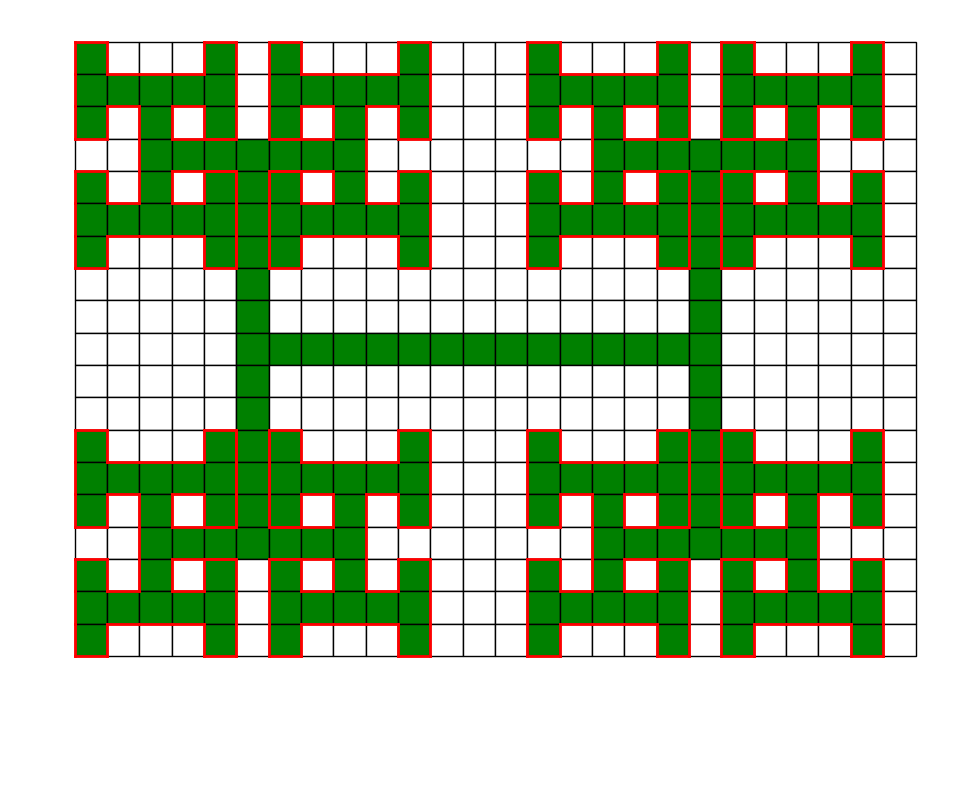

In [22]:
def visualize_full_grid(tiles_df, export=False):
    """
    Visualize the entire grid with green color for tiles in the graph and red borders for all tiles.
    The plot is scaled to match the resolution of the original image as closely as possible.

    Args:
    - tiles_df (pd.DataFrame): DataFrame containing tile information with 'coordinates', 'is_graph', and 'borders' columns.
    """
    # Use width, height, and tile_size from the notebook context if available
    # Default to 42 if not defined
    tile_size = 42
    try:
        img_width = width
        img_height = height
    except NameError:
        img_width = 1240
        img_height = 1019

    _, ax = plt.subplots(figsize=(img_width / 100, img_height / 100), dpi=100)
    for _, row in tiles_df.iterrows():
        x, y = row['coordinates']
        color = 'green' if row['is_graph'] else 'white'
        rect = plt.Rectangle((x * tile_size, y * tile_size), tile_size, tile_size, facecolor=color, edgecolor='black')
        ax.add_patch(rect)
        
        # Draw red borders for all tiles
        if row['borders'][0]:  # Top border
            ax.plot([x * tile_size, (x + 1) * tile_size], [y * tile_size, y * tile_size], color='red', linewidth=2)
        if row['borders'][1]:  # Right border
            ax.plot([(x + 1) * tile_size, (x + 1) * tile_size], [y * tile_size, (y + 1) * tile_size], color='red', linewidth=2)
        if row['borders'][2]:  # Bottom border
            ax.plot([x * tile_size, (x + 1) * tile_size], [(y + 1) * tile_size, (y + 1) * tile_size], color='red', linewidth=2)
        if row['borders'][3]:  # Left border
            ax.plot([x * tile_size, x * tile_size], [y * tile_size, (y + 1) * tile_size], color='red', linewidth=2)
    
    ax.set_xlim(0, img_width)
    ax.set_ylim(img_height, 0)
    ax.set_aspect('equal')
    plt.axis('off')
    if export:
        plt.savefig('/var/home/almogmeir/Documents/M.Sc/Project/Input/full_grid_new.png', bbox_inches='tight', pad_inches=0)
    plt.show()


visualize_full_grid(test_tiles, export=True)

In [23]:
test_tiles

,coordinates,is_graph,borders
0,"(2, 1)",True,"[True, True, False, True]"
1,"(2, 2)",True,"[False, False, False, True]"
2,"(2, 3)",True,"[False, True, True, True]"
3,"(2, 4)",False,"[False, False, False, False]"
4,"(2, 5)",True,"[True, True, False, True]"
...,...,...,...
489,"(27, 15)",False,"[False, False, False, False]"
490,"(27, 16)",False,"[False, False, False, False]"
491,"(27, 17)",False,"[False, False, False, False]"
492,"(27, 18)",False,"[False, False, False, False]"


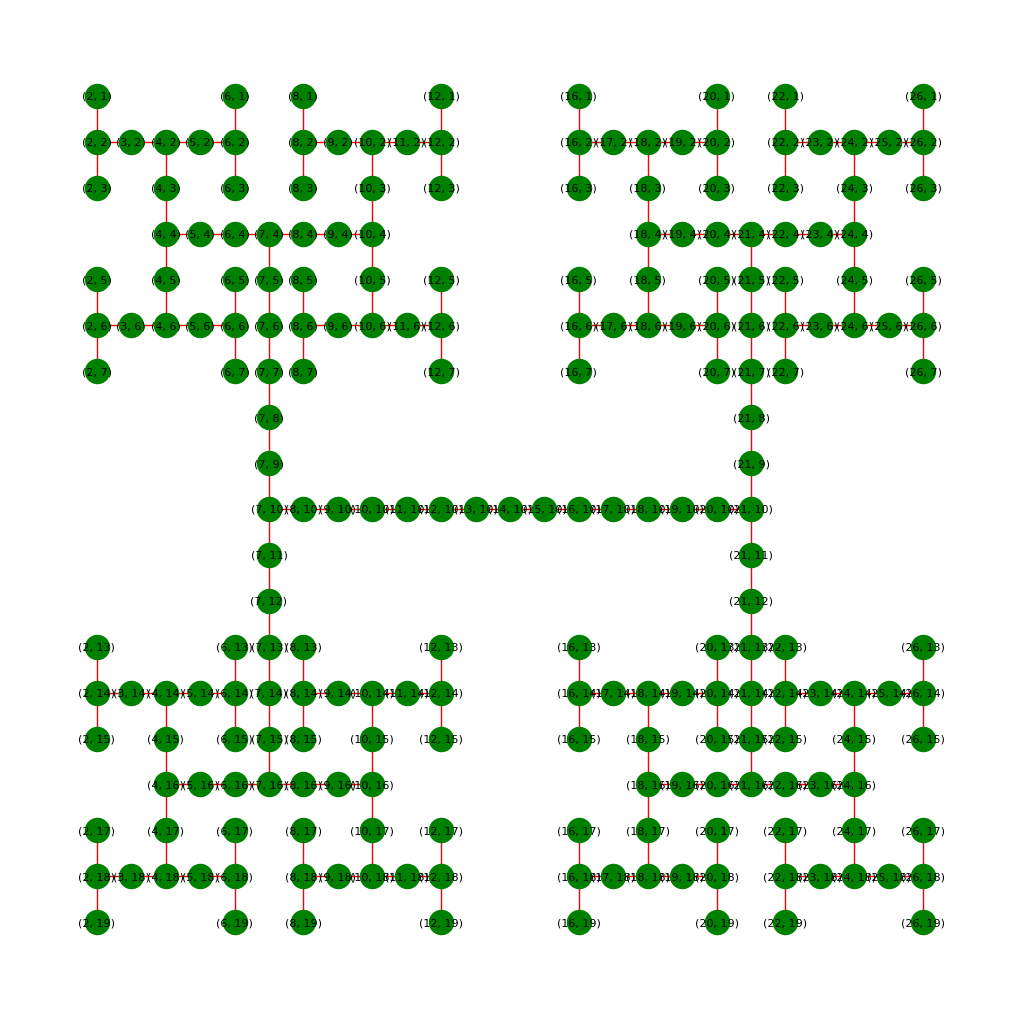

In [24]:
import networkx as nx

def create_graph_from_tiles(tiles_df):
    """
    Create a graph from the tiles_df based on the neighbors of each tile, taking into account the borders.
    Nodes are created for tiles that are endpoints or junctions, and tiles that have neighbors only to the left and right or up and down are considered part of the edge between nodes.

    Args:
    - tiles_df (pd.DataFrame): DataFrame containing tile information with 'coordinates', 'is_graph', and 'borders' columns.

    Returns:
    - G (networkx.Graph): Graph representing the tiles and their neighbors.
    """
    G = nx.Graph()

    # Define the directions for neighbors
    directions = {
        'top': (0, -1),
        'right': (1, 0),
        'bottom': (0, 1),
        'left': (-1, 0)
    }

    # Helper function to get neighbors
    def get_neighbors(x, y, borders):
        neighbors = []
        for i, (dx, dy) in enumerate(directions.values()):
            if not borders[i]:  # If there is no border in this direction
                neighbor_coord = (x + dx, y + dy)
                neighbor_idx = tiles_df[tiles_df['coordinates'] == neighbor_coord].index
                if not neighbor_idx.empty and tiles_df.at[neighbor_idx[0], 'is_graph']:
                    neighbors.append((neighbor_coord, i))
        return neighbors

    # Add nodes and edges to the graph
    for idx, row in tiles_df.iterrows():
        if row['is_graph']:
            x, y = row['coordinates']
            borders = row['borders']
            neighbors = get_neighbors(x, y, borders)

            G.add_node((x, y))

    # Add edges to the graph
    for idx, row in tiles_df.iterrows():
        if row['is_graph']:
            x, y = row['coordinates']
            borders = row['borders']
            neighbors = get_neighbors(x, y, borders)

            if len(neighbors) == 2 and neighbors[0][1] % 2 != neighbors[1][1] % 2:  # Part of a straight line
                continue

            for neighbor, _ in neighbors:
                if G.has_node(neighbor):
                    G.add_edge((x, y), neighbor)

    return G

tiles_G = create_graph_from_tiles(test_tiles)

def visualize_graph(G):
    """
    Visualize the graph with nodes and edges.

    Args:
    - G (networkx.Graph): Graph representing the tiles and their neighbors.
    """
    pos = {node: node for node in G.nodes()}
    plt.figure(figsize=(10, 10))
    nx.draw(G, pos, with_labels=True, node_color='green', edge_color='red', node_size=300, font_size=8)
    plt.gca().invert_yaxis()
    plt.show()

visualize_graph(tiles_G)

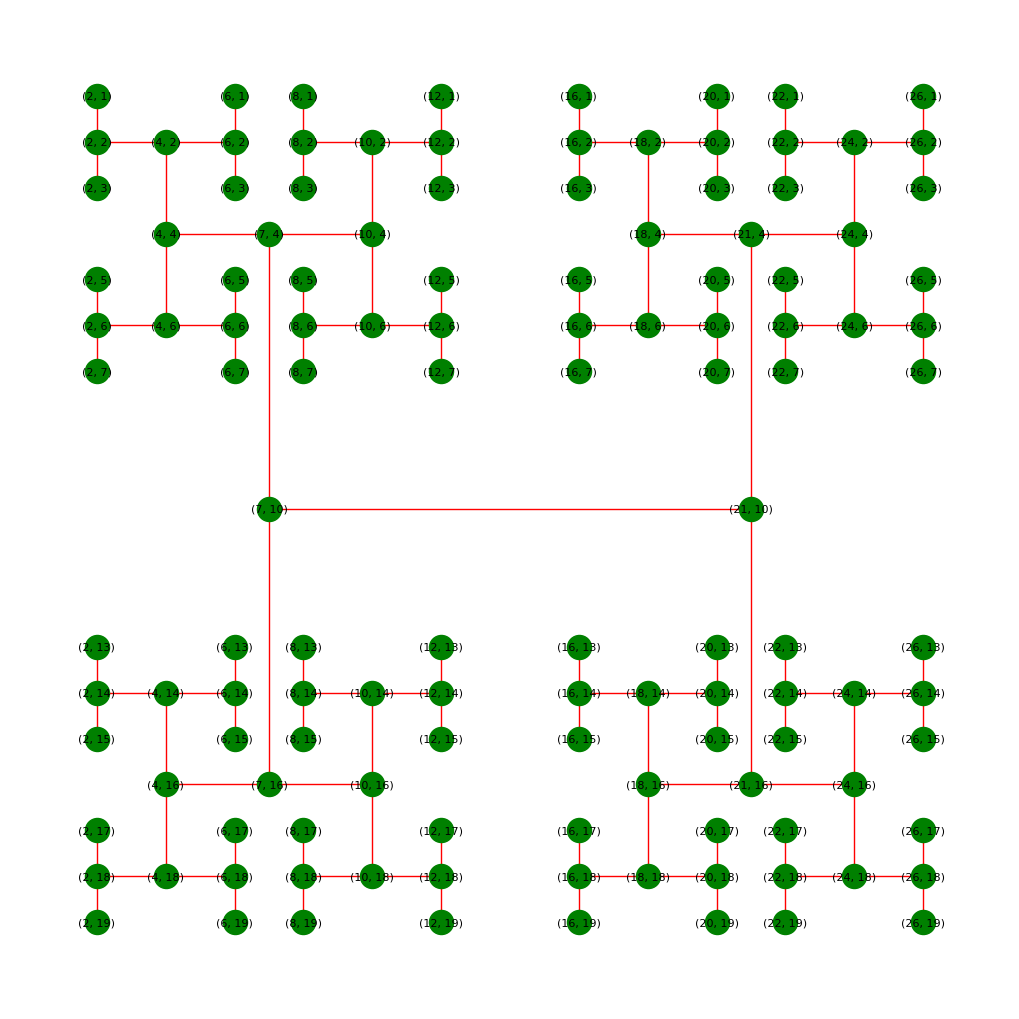

In [25]:
def simplify_graph(G):
    """
    Simplify the graph by removing nodes that have exactly two edges that go to nodes on the same straight line,
    and connecting their neighbor nodes directly. This is done row by row and then column by column.

    Args:
    - G (networkx.Graph): Graph representing the tiles and their neighbors.

    Returns:
    - G (networkx.Graph): Simplified graph.
    """
    def simplify_row(G):
        nodes_to_remove = []
        for y in sorted(set(node[1] for node in G.nodes())):  # Iterate over each row
            row_nodes = sorted([node for node in G.nodes() if node[1] == y], key=lambda node: node[0])
            for i in range(1, len(row_nodes) - 1):
                node = row_nodes[i]
                neighbors = list(G.neighbors(node))
                if len(neighbors) == 2:
                    (x1, y1), (x2, y2) = neighbors
                    if y1 == y and y2 == y:  # Check if neighbors are on the same row
                        # Add an edge between the two neighbors
                        G.add_edge(neighbors[0], neighbors[1])
                        # Mark the current node for removal
                        nodes_to_remove.append(node)
        # Remove the marked nodes
        G.remove_nodes_from(nodes_to_remove)
        return nodes_to_remove

    def simplify_column(G):
        nodes_to_remove = []
        for x in sorted(set(node[0] for node in G.nodes())):  # Iterate over each column
            column_nodes = sorted([node for node in G.nodes() if node[0] == x], key=lambda node: node[1])
            for i in range(1, len(column_nodes) - 1):
                node = column_nodes[i]
                neighbors = list(G.neighbors(node))
                if len(neighbors) == 2:
                    (x1, y1), (x2, y2) = neighbors
                    if x1 == x and x2 == x:  # Check if neighbors are on the same column
                        # Add an edge between the two neighbors
                        G.add_edge(neighbors[0], neighbors[1])
                        # Mark the current node for removal
                        nodes_to_remove.append(node)
        # Remove the marked nodes
        G.remove_nodes_from(nodes_to_remove)
        return nodes_to_remove

    # Simplify the graph row by row and column by column until no more nodes can be removed
    G = G.copy()
    edges = []
    while True:
        r = simplify_row(G)
        c = simplify_column(G)
        # Append to edges all the edges that were removed
        edges.extend([(r[i]) for i in range(len(r))])
        edges.extend([(c[i]) for i in range(len(c))])
        if len(r) == 0 and len(c) == 0:
            break
    edges_G = nx.Graph()
    edges_G.add_nodes_from(edges)

    return G, edges_G

G, edges_G = simplify_graph(tiles_G)
visualize_graph(G)

In [ ]:
print(G)

Graph with 126 nodes and 125 edges


In [26]:
def compute_turn(prev, curr, next_):
    """Compute left/right/straight turn from three coordinates."""
    v1 = (curr[0] - prev[0], curr[1] - prev[1])
    v2 = (next_[0] - curr[0], next_[1] - curr[1])
    cross = v1[0] * v2[1] - v1[1] * v2[0]
    if cross < 0:
        return "left"
    elif cross > 0:
        return "right"
    else:
        return "straight"

def is_leaf(G, node):
    """A node is a leaf if it has only one neighbor."""
    return G.degree[node] == 1

def get_all_turns_from_leaves(G):
    """Extract (prev, curr, next) turns from all root-to-leaf paths."""
    leaves = [n for n in G.nodes if is_leaf(G, n)]
    all_turns = set()

    for leaf in leaves:
        # Perform DFS from leaf to gather path up
        paths = nx.single_source_shortest_path(G, leaf)
        for target, path in paths.items():
            if len(path) < 3:
                continue  # Need at least 3 nodes to compute a turn
            for i in range(len(path) - 2):
                prev, curr, next_ = path[i], path[i+1], path[i+2]
                direction = compute_turn(prev, curr, next_)
                all_turns.add((prev, curr, next_, direction))

    df = pd.DataFrame(list(all_turns), columns=["prev", "curr", "next", "direction"])
    return df

# Example usage
full_turns_df = get_all_turns_from_leaves(G)
full_turns_df

,prev,curr,next,direction
0,"(4, 18)","(6, 18)","(6, 19)",right
1,"(18, 2)","(18, 4)","(18, 6)",straight
2,"(8, 1)","(8, 2)","(10, 2)",left
3,"(4, 18)","(6, 18)","(6, 17)",left
4,"(8, 14)","(10, 14)","(10, 16)",right
...,...,...,...,...
367,"(20, 18)","(18, 18)","(18, 16)",right
368,"(24, 18)","(22, 18)","(22, 17)",right
369,"(24, 16)","(24, 14)","(22, 14)",left
370,"(26, 17)","(26, 18)","(26, 19)",straight


In [ ]:
# export full_turns_df
full_turns_df.to_csv('/var/home/almogmeir/Documents/M.Sc/Project/Input/full_turns_df.csv', index=False)

In [27]:
# print all edges that include the node (21, 10) in turns_df
edges = []
for i in range(len(full_turns_df)):
    if (16, 1) in (full_turns_df['prev'][i], full_turns_df['curr'][i], full_turns_df['next'][i]):
        edges.append({'prev': full_turns_df['prev'][i], 'curr': full_turns_df['curr'][i], 'next': full_turns_df['next'][i], 'direction': full_turns_df['direction'][i]})
edges

[{'prev': (18, 2), 'curr': (16, 2), 'next': (16, 1), 'direction': 'right'},
 {'prev': (16, 1), 'curr': (16, 2), 'next': (16, 3), 'direction': 'straight'},
 {'prev': (16, 1), 'curr': (16, 2), 'next': (18, 2), 'direction': 'left'},
 {'prev': (16, 3), 'curr': (16, 2), 'next': (16, 1), 'direction': 'straight'}]

In [28]:
# count number of left turns
full_turns_df['direction'].value_counts()

direction
right       124
straight    124
left        124
Name: count, dtype: int64

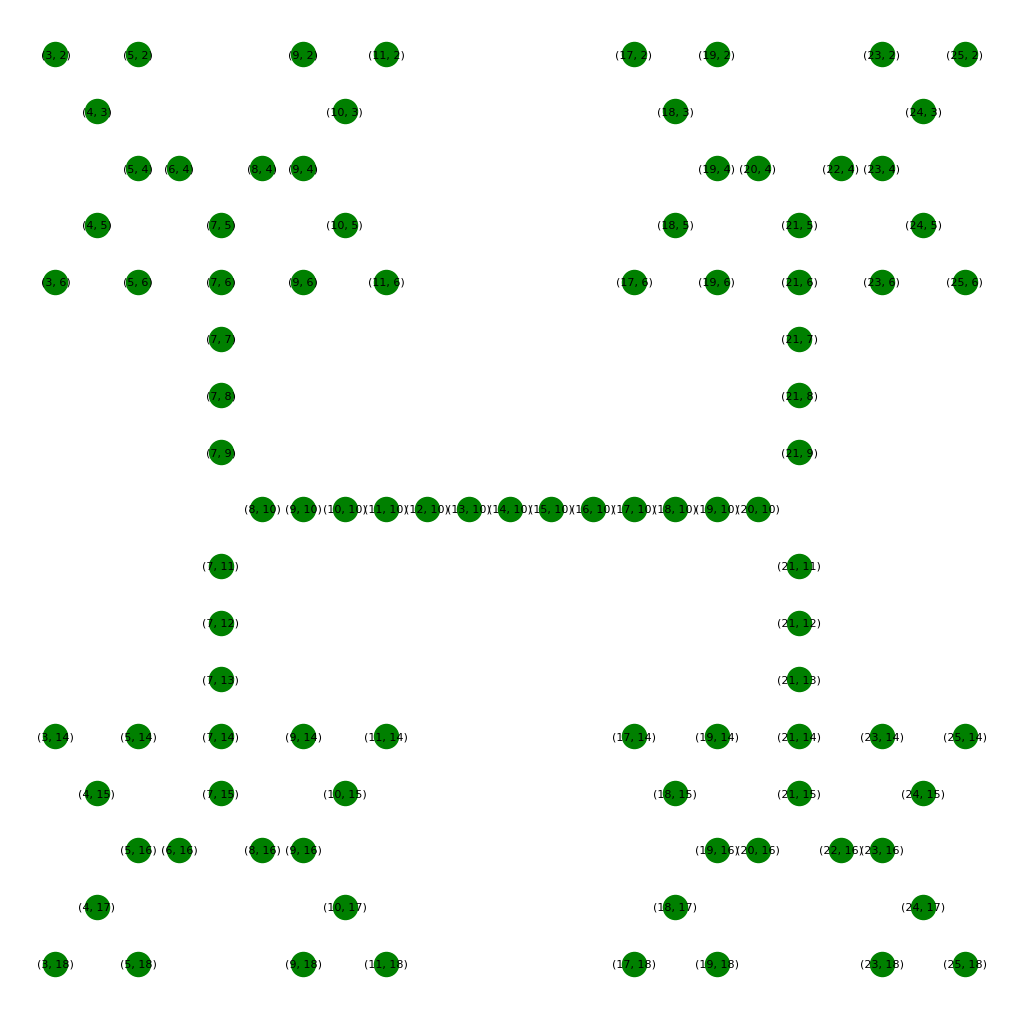

In [ ]:
visualize_graph(edges_G)

In [29]:
!pip install pydot

In [30]:
import pydot
from networkx.drawing.nx_pydot import graphviz_layout

# root_node = (14,7)
root_node = (7,10)
plt.figure(figsize=(15,15))
pos = graphviz_layout(G, prog="neato", root=root_node)
nx.draw(G, pos, with_labels=True, node_size=150, font_size=10, node_color='pink')
plt.show()

FileNotFoundError: [Errno 2] "neato" not found in path.

<Figure size 1500x1500 with 0 Axes>

In [31]:
# maze1
# root_node = (14,7)
# grid_size = (24,16)
# grid_start = (3,4)

# # maze2
# root_node = (7,12)
# grid_size = (27,16)
# grid_start = (2,4)

# # maze3
# root_node = (6,10)
# grid_size = (26,19)
# grid_start = (1,1)

# maze4
root_node = (7,10)
grid_size = (26,19)
grid_start = (2,1)


tiles_dict = {(x + grid_start[0], y + grid_start[1]): y * grid_size[0] + x for y in range(grid_size[1]) for x in range(grid_size[0])}  
print(tiles_dict)

{(2, 1): 0, (3, 1): 1, (4, 1): 2, (5, 1): 3, (6, 1): 4, (7, 1): 5, (8, 1): 6, (9, 1): 7, (10, 1): 8, (11, 1): 9, (12, 1): 10, (13, 1): 11, (14, 1): 12, (15, 1): 13, (16, 1): 14, (17, 1): 15, (18, 1): 16, (19, 1): 17, (20, 1): 18, (21, 1): 19, (22, 1): 20, (23, 1): 21, (24, 1): 22, (25, 1): 23, (26, 1): 24, (27, 1): 25, (2, 2): 26, (3, 2): 27, (4, 2): 28, (5, 2): 29, (6, 2): 30, (7, 2): 31, (8, 2): 32, (9, 2): 33, (10, 2): 34, (11, 2): 35, (12, 2): 36, (13, 2): 37, (14, 2): 38, (15, 2): 39, (16, 2): 40, (17, 2): 41, (18, 2): 42, (19, 2): 43, (20, 2): 44, (21, 2): 45, (22, 2): 46, (23, 2): 47, (24, 2): 48, (25, 2): 49, (26, 2): 50, (27, 2): 51, (2, 3): 52, (3, 3): 53, (4, 3): 54, (5, 3): 55, (6, 3): 56, (7, 3): 57, (8, 3): 58, (9, 3): 59, (10, 3): 60, (11, 3): 61, (12, 3): 62, (13, 3): 63, (14, 3): 64, (15, 3): 65, (16, 3): 66, (17, 3): 67, (18, 3): 68, (19, 3): 69, (20, 3): 70, (21, 3): 71, (22, 3): 72, (23, 3): 73, (24, 3): 74, (25, 3): 75, (26, 3): 76, (27, 3): 77, (2, 4): 78, (3, 4):

In [ ]:
# def create_graph_with_pos(G, root_node):
#     new_G = nx.Graph()
#     pos = {}
    
#     def traverse(node, level=0, label_id=0, parent=None):
#         if node not in pos:
#             pos[node] = (level, label_id)
#             new_G.add_node(tiles_dict[node], pos=(label_id, level))
#             if parent is not None:
#                 new_G.add_edge(parent, node)
        
#         children = [n for n in G.neighbors(node) if n != parent]
#         for i, child in enumerate(children):
#             traverse(child, level + 1, i, node)
    
#     traverse(root_node)
#     return new_G

# G = create_graph_with_pos(G, root_node)
# # visualize_graph(G)

In [32]:
tiles_dict[(2,4)]

78

In [ ]:
nx.get_node_attributes(G, 'pos')

{}

In [ ]:
import pickle
with open('/var/home/almogmeir/Documents/M.Sc/Project/maze2.gpickle', 'wb') as f:
    pickle.dump(G, f, pickle.HIGHEST_PROTOCOL)

In [ ]:
with open('/var/home/almogmeir/Documents/M.Sc/Project/maze2.gpickle', 'rb') as f:
    read_G = pickle.load(f)

nx.get_node_attributes(read_G, 'pos')

{}

In [ ]:
nx.get_node_attributes(read_G, 'pos')[518]

KeyError: 518

In [33]:
tiles_dict[(14,11)]

272

In [34]:
max_grid_row, max_grid_col = np.array((16, 29)) * 32
origin_row, origin_col = eval(str((147, 182)))
origin_row

147

In [35]:
from collections import deque

def numerate_nodes(G, root_node, grid_size, grid_start):
    tiles_dict = {(x + grid_start[0], y + grid_start[1]): y * grid_size[0] + x for y in range(grid_size[1]) for x in range(grid_size[0])}    
    return tiles_dict

def create_dict_nodes(G, root_node, tiles_dict):
    """
    Traverse a tree graph and create a dictionary where each key is a tile number
    and the value is an integer based on the level of the tree.

    Args:
    - G (networkx.Graph): Tree graph to traverse.
    - root_node (tuple): Coordinates of the root node.
    - grid_size (tuple): Size of the grid (width, height).
    - grid_start (tuple): Coordinates of the first tile in the grid.

    Returns:
    - dict: Dictionary with tile numbers as keys and level integers as values.
    """

    # Initialize the dictionary and the queue for BFS
    nodes_dict = {}
    queue = deque([(root_node, 0)])  # (node, level)
    # Map the tiles coordinates to tile numbers row by row starting with 0, from the top left
    level_counters = {}  # To keep track of the index for each level


    while queue:
        node, level = queue.popleft()
        x, y = node[0], node[1]
        tile_number = tiles_dict[(x, y)]
        
        # Initialize the counter for this level if not already done
        if level not in level_counters:
            level_counters[level] = 0

        # Assign the unique level number to the tile number
        if level_counters[level] < 10:
            unique_level_number = level * 10 + level_counters[level]
        else:
            unique_level_number = level * 100 + level_counters[level]
        nodes_dict[tile_number] = unique_level_number

        # Increment the counter for this level
        level_counters[level] += 1

        # print(f"Node: {node}, Level: {unique_level_number}, Tile Number: {tile_number}")

        # Add children to the queue with incremented level
        for neighbor in G.neighbors(node):
            n_x = neighbor[0]
            n_y = neighbor[1]
            if tiles_dict[(n_x, n_y)] not in nodes_dict:
                queue.append((neighbor, level + 1))

    return nodes_dict

# Example usage:
# G is the graph, root_node is the root node, grid_size is (42, 42), grid_start is (0, 0)
tiles_dict = numerate_nodes(G, root_node, grid_size, grid_start)
nodes_dict = create_dict_nodes(G, root_node, tiles_dict)
print(nodes_dict)

{239: 0, 83: 10, 395: 11, 253: 12, 80: 20, 86: 21, 392: 22, 398: 23, 97: 24, 409: 25, 28: 30, 132: 31, 34: 32, 138: 33, 340: 34, 444: 35, 346: 36, 450: 37, 94: 38, 100: 39, 406: 310, 412: 311, 26: 40, 30: 41, 130: 42, 134: 43, 32: 44, 36: 45, 136: 46, 140: 47, 338: 48, 342: 49, 442: 410, 446: 411, 344: 412, 348: 413, 448: 414, 452: 415, 42: 416, 146: 417, 48: 418, 152: 419, 354: 420, 458: 421, 360: 422, 464: 423, 0: 50, 52: 51, 4: 52, 56: 53, 104: 54, 156: 55, 108: 56, 160: 57, 6: 58, 58: 59, 10: 510, 62: 511, 110: 512, 162: 513, 114: 514, 166: 515, 312: 516, 364: 517, 316: 518, 368: 519, 416: 520, 468: 521, 420: 522, 472: 523, 318: 524, 370: 525, 322: 526, 374: 527, 422: 528, 474: 529, 426: 530, 478: 531, 40: 532, 44: 533, 144: 534, 148: 535, 46: 536, 50: 537, 150: 538, 154: 539, 352: 540, 356: 541, 456: 542, 460: 543, 358: 544, 362: 545, 462: 546, 466: 547, 14: 60, 66: 61, 18: 62, 70: 63, 118: 64, 170: 65, 122: 66, 174: 67, 20: 68, 72: 69, 24: 610, 76: 611, 124: 612, 176: 613, 128: 6

In [ ]:
nodes_dict[83]

10

In [36]:
# Get number of leaf nodes in G
leaf_nodes = [node for node in G.nodes() if G.degree(node) == 1]
len(leaf_nodes)

64

In [37]:
def create_full_dict(nodes_dict, G, tiles_G, tiles_dict):
    """
    Create a dictionary that includes all the tiles that are edges.

    Args:
    - nodes_dict (dict): Dictionary with tile numbers as keys and node information as values.
    - G (networkx.Graph): Graph representing the tiles and their neighbors.
    - tiles_G (networkx.Graph): Graph representing the edges.
    - tiles_dict (dict): Dictionary mapping tile coordinates to tile numbers.

    Returns:
    - dict: Updated dictionary with edge information.
    """
    full_dict = nodes_dict.copy()

    def traverse_to_find_two_nodes(start_node, visited):
        """
        Traverse the neighbors until two node tiles (which exist in G) are found.

        Args:
        - start_node (tuple): The starting node for traversal.
        - visited (set): Set of visited nodes to avoid cycles.

        Returns:
        - tuple: The two node tiles found in G.
        """
        queue = deque([start_node])
        found_nodes = []
        while queue and len(found_nodes) < 2:
            node = queue.popleft()
            if node in G.nodes() and node not in found_nodes:
                found_nodes.append(node)
            visited.add(node)
            for neighbor in tiles_G.neighbors(node):
                if neighbor not in visited:
                    queue.append(neighbor)
        return tuple(found_nodes) if len(found_nodes) == 2 else None

    for edge_node in tiles_G.nodes():
        if edge_node in G.nodes():
            x, y = edge_node
            tile_number = tiles_dict[(x, y)]
            neighbors = list(tiles_G.neighbors(edge_node))
            found_node = False
            for neighbor in neighbors:
                if neighbor in G.nodes():
                    neighbor_tile_number = tiles_dict[neighbor]
                    tile_level = nodes_dict[tile_number]
                    neighbor_level = nodes_dict[neighbor_tile_number]
                    sorted_tup = tuple(sorted((tile_level, neighbor_level)))
                    full_dict[tile_number] = frozenset([full_dict[tile_number], sorted_tup])
                    found_node = True
                    break
        else:
            visited = set()
            node_tiles = traverse_to_find_two_nodes(edge_node, visited)
            if node_tiles:
                tile1_level = nodes_dict[tiles_dict[node_tiles[0]]]
                tile2_level = nodes_dict[tiles_dict[node_tiles[1]]]
                node_tile_numbers = tuple(sorted((tile1_level, tile2_level)))
                x, y = edge_node
                tile_number = tiles_dict[(x, y)]
                full_dict[tile_number] = node_tile_numbers

    return full_dict

# Example usage:
# nodes_dict is the dictionary with node information
# G is the graph, edges_G is the edges graph, tiles_dict is the dictionary mapping tile coordinates to tile numbers
final_dict = create_full_dict(nodes_dict, G, tiles_G, tiles_dict)
print(final_dict)

{239: 0, 83: 10, 395: 11, 253: 12, 80: 20, 86: 21, 392: 22, 398: 23, 97: 24, 409: 25, 28: 30, 132: 31, 34: 32, 138: 33, 340: 34, 444: 35, 346: 36, 450: 37, 94: 38, 100: 39, 406: 310, 412: 311, 26: frozenset({40, (40, 50)}), 30: frozenset({41, (41, 52)}), 130: frozenset({(42, 54), 42}), 134: frozenset({43, (43, 56)}), 32: frozenset({(44, 58), 44}), 36: frozenset({(45, 510), 45}), 136: frozenset({46, (46, 512)}), 140: frozenset({(47, 514), 47}), 338: frozenset({48, (48, 516)}), 342: frozenset({(49, 518), 49}), 442: frozenset({(410, 520), 410}), 446: frozenset({411, (411, 522)}), 344: frozenset({412, (412, 524)}), 348: frozenset({(413, 526), 413}), 448: frozenset({(414, 528), 414}), 452: frozenset({(415, 530), 415}), 42: 416, 146: 417, 48: 418, 152: 419, 354: 420, 458: 421, 360: 422, 464: 423, 0: frozenset({50, (40, 50)}), 52: frozenset({51, (40, 51)}), 4: frozenset({(41, 52), 52}), 56: frozenset({(41, 53), 53}), 104: frozenset({(42, 54), 54}), 156: frozenset({(42, 55), 55}), 108: frozens

In [ ]:
# Save the final dictionary to a file
# import json

# # Convert frozenset to list for JSON serialization
# serializable_dict = {k: list(v) if isinstance(v, frozenset) else v for k, v in final_dict.items()}

# with open('/var/home/almogmeir/Documents/M.Sc/Project/final_dict_maze1.json', 'w') as f:
#     # Save the final dictionary to a file

#     # Convert frozenset to list for JSON serialization
#     serializable_dict = {k: list(v) if isinstance(v, frozenset) else v for k, v in final_dict.items()}

#     # Save as JSON
#     with open('/var/home/almogmeir/Documents/M.Sc/Project/final_dict_maze1.json', 'w') as f:
#         json.dump(serializable_dict, f)

import pickle
# Save as pickle
with open('/var/home/almogmeir/Documents/M.Sc/Project/final_dict_maze4.pkl', 'wb') as f:
    pickle.dump(final_dict, f)


# Add graph position to the raw pkl data from NaviGraph

In [74]:
%pip install ruamel.yaml

Note: you may need to restart the kernel to use updated packages.


In [38]:
import pickle

with open('/var/home/almogmeir/Documents/M.Sc/Project/MazeMaster-dev/outputs/2025-07-24/16-37-58/NPC1_2025_07_21_12_03_54_stitched_gamma_raw.pkl', 'rb') as f:
    data_full = pickle.load(f)

# /var/home/almogmeir/Documents/M.Sc/Project/MazeMaster-dev/outputs/2025-01-27/13-31-53/01_16_2025_rewardsize_17NC-01162025152516-0000_raw.pkl
# with open('/var/home/almogmeir/Documents/M.Sc/Project/DLC/01_23_2025_13NC_rewardSize-01232025170447-0000/01_23_2025_13NC_rewardSize-01232025170447-0000_raw.pkl', 'rb') as f:
#     data_before = pickle.load(f)

# Load the dlc data from csv to df
# dlc_raw = pd.read_csv('/var/home/almogmeir/Documents/M.Sc/Project/MazeMaster-dev/outputs/2025-01-27/13-31-53/01_16_2025_rewardsize_17NC-01162025152516-0000DLC_resnet50_AD_4lp_maze1Oct15shuffle1_150000.csv')

# h5_file = pd.read_hdf('/var/home/almogmeir/Documents/M.Sc/Project/01_16_2025_rewardsize_17NC-01162025152516-0000.h5')

In [41]:
# Read the graph using adjlist
# G = nx.read_adjlist('/var/home/almogmeir/Documents/M.Sc/Project/Mazes/maze2.adjlist')

In [39]:
# Find the first and last index where 'tree_position' is not null for at least 2 consecutive rows
first_valid_index = None
last_valid_index = None

for i in range(len(data_full) - 1):
    if pd.notnull(data_full.loc[i, 'tree_position']) and pd.notnull(data_full.loc[i + 1, 'tree_position']):
        first_valid_index = i
        break

for i in range(len(data_full) - 1, 0, -1):
    if pd.notnull(data_full.loc[i, 'tree_position']) and pd.notnull(data_full.loc[i - 1, 'tree_position']):
        last_valid_index = i
        break

# Calculate the number of rows to be removed from start and end
rows_removed_start = first_valid_index
rows_removed_end = len(data_full) - last_valid_index - 1

# Remove the rows
data = data_full.loc[first_valid_index:last_valid_index]

# Print the number of rows removed
print(f"Number of rows removed from start: {rows_removed_start}")
print(f"Number of rows removed from end: {rows_removed_end}")

Number of rows removed from start: 1
Number of rows removed from end: 0


In [43]:
data

coords,x,y,likelihood,tile_box,tile_id,tree_position
1,766.687988,188.867767,0.727511,"[542, 104, 28, 28]",68,"(38, 416)"
2,767.544556,188.642807,0.705884,"[542, 104, 28, 28]",68,"(38, 416)"
3,767.311951,188.284256,0.715563,"[542, 104, 28, 28]",68,"(38, 416)"
4,766.961121,188.428314,0.712139,"[542, 104, 28, 28]",68,"(38, 416)"
5,766.003723,187.994553,0.727802,"[542, 104, 28, 28]",68,"(38, 416)"
...,...,...,...,...,...,...
129028,800.034119,249.163086,0.971797,"[571, 133, 28, 28]",95,"(24, 38)"
129029,800.113159,248.237442,1.000000,"[571, 133, 28, 28]",95,"(24, 38)"
129030,799.411194,246.969330,1.000000,"[571, 133, 28, 28]",95,"(24, 38)"
129031,799.487305,245.697754,0.993419,"[571, 133, 28, 28]",95,"(24, 38)"


In [ ]:
# data_before

coords,x,y,likelihood,tile_box,tile_id,tree_position
0,551.053162,820.800171,0.963719,"[502, 595, 31, 31]",388.0,"((47, 514), 47)"
1,550.746338,823.011230,0.949312,"[502, 595, 31, 31]",388.0,"((47, 514), 47)"
2,551.094788,825.726379,0.909568,"[502, 595, 31, 31]",388.0,"((47, 514), 47)"
3,550.287659,826.767578,0.909067,"[502, 595, 31, 31]",388.0,"((47, 514), 47)"
4,551.438599,830.332092,0.978875,"[502, 627, 31, 31]",415.0,"(515, (47, 515))"
...,...,...,...,...,...,...
99570,149.979324,633.626343,0.451042,"[182, 467, 31, 31]",270.0,"(40, (40, 50))"
99571,147.265808,632.973816,0.627250,"[182, 467, 31, 31]",270.0,"(40, (40, 50))"
99572,146.065842,633.263550,0.714764,"[182, 467, 31, 31]",270.0,"(40, (40, 50))"
99573,143.665802,634.119751,0.789346,"[182, 467, 31, 31]",270.0,"(40, (40, 50))"


In [78]:
dlc_raw
likelihood_columns = dlc_raw.loc[:, dlc_raw.iloc[1] == 'likelihood']
likelihood_columns

NameError: name 'dlc_raw' is not defined

In [79]:
# Convert the likelihood columns to float
likelihood_columns = likelihood_columns.astype(float)

# Filter rows where all likelihoods are less than 0.3
filtered_likelihoods = likelihood_columns[(likelihood_columns < 0.3).all(axis=1)]

filtered_likelihoods

NameError: name 'likelihood_columns' is not defined

In [80]:
data['tile_id'] = data['tile_id'].fillna(0).astype(int)
# data_before['tile_id'] = data_before['tile_id'].fillna(0).astype(int)

/tmp/ipykernel_8638/2191276676.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['tile_id'] = data['tile_id'].fillna(0).astype(int)


In [40]:
data[300:310]

coords,x,y,likelihood,tile_box,tile_id,tree_position
301,317.462311,446.970184,0.615847,"[223, 278, 28, 28]",213,"(0, 10)"
302,8.164328,933.780701,0.591171,None,-1,None
303,320.305969,449.714111,0.614234,"[223, 278, 28, 28]",213,"(0, 10)"
304,330.473877,455.375549,0.865093,"[223, 307, 28, 28]",239,0
305,330.504059,453.971710,0.758573,"[223, 278, 28, 28]",213,"(0, 10)"
306,330.026245,451.874512,0.719615,"[223, 278, 28, 28]",213,"(0, 10)"
307,332.817902,451.994446,0.677918,"[223, 278, 28, 28]",213,"(0, 10)"
308,334.247040,451.901245,0.748333,"[223, 278, 28, 28]",213,"(0, 10)"
309,347.630066,458.779480,0.753891,"[252, 307, 28, 28]",240,"(0, 10)"
310,349.065704,457.925232,0.737614,"[252, 307, 28, 28]",240,"(0, 10)"


In [ ]:
# Show row in data_before where likelihood is nan
# data_before[data_before['likelihood'].isna()]

coords,x,y,likelihood,tile_box,tile_id,tree_position
156,NaN,NaN,NaN,NaN,0,NaN
157,NaN,NaN,NaN,NaN,0,NaN
158,NaN,NaN,NaN,NaN,0,NaN
159,NaN,NaN,NaN,NaN,0,NaN
160,NaN,NaN,NaN,NaN,0,NaN
...,...,...,...,...,...,...
99502,NaN,NaN,NaN,NaN,0,NaN
99503,NaN,NaN,NaN,NaN,0,NaN
99504,NaN,NaN,NaN,NaN,0,NaN
99505,NaN,NaN,NaN,NaN,0,NaN


In [82]:
# Show row in data where likelihood is nan
data[data['likelihood'].isna()]

coords,x,y,likelihood,tile_box,tile_id,tree_position


In [41]:
tiles_dict

{(2, 1): 0,
 (3, 1): 1,
 (4, 1): 2,
 (5, 1): 3,
 (6, 1): 4,
 (7, 1): 5,
 (8, 1): 6,
 (9, 1): 7,
 (10, 1): 8,
 (11, 1): 9,
 (12, 1): 10,
 (13, 1): 11,
 (14, 1): 12,
 (15, 1): 13,
 (16, 1): 14,
 (17, 1): 15,
 (18, 1): 16,
 (19, 1): 17,
 (20, 1): 18,
 (21, 1): 19,
 (22, 1): 20,
 (23, 1): 21,
 (24, 1): 22,
 (25, 1): 23,
 (26, 1): 24,
 (27, 1): 25,
 (2, 2): 26,
 (3, 2): 27,
 (4, 2): 28,
 (5, 2): 29,
 (6, 2): 30,
 (7, 2): 31,
 (8, 2): 32,
 (9, 2): 33,
 (10, 2): 34,
 (11, 2): 35,
 (12, 2): 36,
 (13, 2): 37,
 (14, 2): 38,
 (15, 2): 39,
 (16, 2): 40,
 (17, 2): 41,
 (18, 2): 42,
 (19, 2): 43,
 (20, 2): 44,
 (21, 2): 45,
 (22, 2): 46,
 (23, 2): 47,
 (24, 2): 48,
 (25, 2): 49,
 (26, 2): 50,
 (27, 2): 51,
 (2, 3): 52,
 (3, 3): 53,
 (4, 3): 54,
 (5, 3): 55,
 (6, 3): 56,
 (7, 3): 57,
 (8, 3): 58,
 (9, 3): 59,
 (10, 3): 60,
 (11, 3): 61,
 (12, 3): 62,
 (13, 3): 63,
 (14, 3): 64,
 (15, 3): 65,
 (16, 3): 66,
 (17, 3): 67,
 (18, 3): 68,
 (19, 3): 69,
 (20, 3): 70,
 (21, 3): 71,
 (22, 3): 72,
 (23, 3): 73

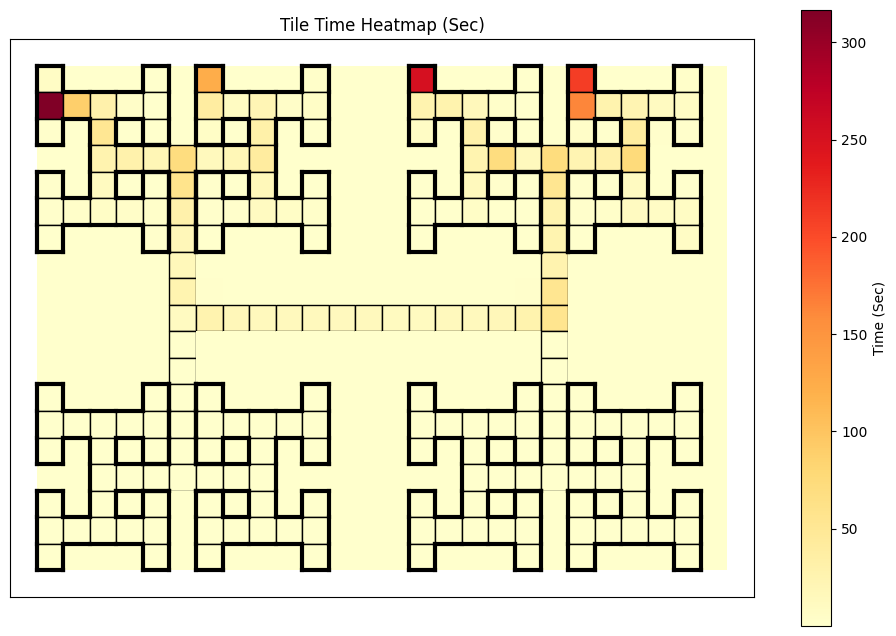

In [84]:
import matplotlib.pyplot as plt
import pandas as pd

def visualize_maze_heatmap(tiles_df, freq_dict, export=False):
    """
    Visualize the entire grid with colors for each tile based on frequency (heatmap-like).

    Args:
      tiles_df (pd.DataFrame): DataFrame containing tile information with 'coordinates', 'borders',
                               and optionally 'tile_id' (if not present, the DataFrame index is used).
      freq_dict (dict): Mapping of tile id (or index) to frequency.
      export (bool): If True, save the plot to disk.
    """
    fig, ax = plt.subplots()

    # Apply log scale to frequencies
    # freq_dict = {k: np.emath.logn(2, v) for k, v in freq_dict.items()}
    # divide all frequencis by 40 to get time in seconds
    freq_dict = {k: v / 40 for k, v in freq_dict.items()}
    cmap = plt.cm.YlOrRd  # You can change this to another colormap (e.g., plt.cm.viridis)

    # Set up the colormap and normalization from the frequency dictionary:
    if freq_dict:
        vmin = min(freq_dict.values())
        vmax = max(freq_dict.values())
    else:
        vmin, vmax = 0, 1
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    # Draw each tile with a color given by its frequency and add gray border for graph tiles:
    for idx, row in tiles_df.iterrows():
        x, y = row['coordinates']
        tile_id = tiles_dict.get(tuple(row['coordinates']), -1)
        # tile_id = row.get('tile_id', idx)  # use tile_id if present, else the index
        freq = freq_dict.get(tile_id, 0)
        color = cmap(norm(freq))
        rect = plt.Rectangle((x, y), 1, 1, facecolor=color, edgecolor='black' if row['is_graph'] else 'none', linewidth=1)
        ax.add_patch(rect)

        borders = row['borders']
        if borders[0]:  # Top border
            ax.plot([x, x + 1], [y, y], color='black', linewidth=3)
        if borders[1]:  # Right border
            ax.plot([x + 1, x + 1], [y, y + 1], color='black', linewidth=3)
        if borders[2]:  # Bottom border
            ax.plot([x, x + 1], [y + 1, y + 1], color='black', linewidth=3)
        if borders[3]:  # Left border
            ax.plot([x, x], [y, y + 1], color='black', linewidth=3)


    # Set plot limits
    xs = tiles_df['coordinates'].apply(lambda c: c[0])
    ys = tiles_df['coordinates'].apply(lambda c: c[1])
    ax.set_xlim(xs.min() - 1, xs.max() + 2)
    ax.set_ylim(ys.min() - 1, ys.max() + 2)
    ax.set_aspect('equal')
    fig.set_size_inches(12, 8)
    ax.invert_yaxis()

    # Add a colorbar showing frequency normalization
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])  # dummy array for the colorbar
    fig.colorbar(sm, ax=ax, label='Time (Sec)')

    # Set the title and labels
    ax.set_title('Tile Time Heatmap (Sec)')
    # Remove x and y ticks
    ax.set_xticks([])
    ax.set_yticks([])

    if export:
        plt.savefig('/var/home/almogmeir/Documents/M.Sc/Project/Graphs/17L_2025_05_27_15_20_41/heatmap_grid.png')
    plt.show()

# Example usage:
# Suppose 'data' is your DataFrame with tile occurrences.
# You can calculate the frequency of each tile using:
freq_dict = data['tile_id'].value_counts().to_dict()
freq_dict.pop(-1, None)
# freq_dict = {k: v for k, v in freq_dict.items() if v >= 30}
#
# And then call visualize_full_grid with your tiles DataFrame and freq_dict:
#
visualize_maze_heatmap(test_tiles, freq_dict, export=True)

In [43]:
%pip install mat73

Note: you may need to restart the kernel to use updated packages.


In [44]:
import mat73
import scipy.io

data_mat = mat73.loadmat('/var/home/almogmeir/Documents/M.Sc/Project/simplified_spike_data.mat')
data_simplified = data_mat['simplified_data']

trial_info = scipy.io.loadmat('/var/home/almogmeir/Documents/M.Sc/Project/trial_info.mat')
trial_times = trial_info['trial_info'][0][0][0]

unit_spikes_cols = ["session", "subject_id", "electrode_group", "unit", "spike_times"]
df_unit_spikes = pd.DataFrame(columns=unit_spikes_cols)

# Initialize a dictionary to collect spike times for each unit across all trials
unit_spike_times_dict = {unit: [] for unit in range(int(data_simplified['num_clusters']))}

for i in range(len(data_simplified['trial_spikes'])):
    for spike in range(len(data_simplified['trial_spikes'][i][0]['cluster_ids'])):
        unit = data_simplified['trial_spikes'][i][0]['cluster_ids'][spike]
        spike_time = data_simplified['trial_spikes'][i][0]['spike_times_sec'][spike]
        unit_spike_times_dict[unit].append(spike_time)

for unit in range(int(data_simplified['num_clusters'])):
    df_unit_spikes.loc[unit] = {
        "session": 1,
        "subject_id": 111,
        "electrode_group": 1,
        "unit": unit,
        "spike_times": unit_spike_times_dict[unit]
    }

print("UnitSpikes DataFrame:\n", df_unit_spikes)
print(f"Spike train length for unit 0: {len(unit_spike_times_dict[0])}")


    # print(f"Trial {i + 1} spike times: {spike_times_dict}")

UnitSpikes DataFrame:
      session  subject_id  electrode_group  unit  \
0          1         111                1     0   
1          1         111                1     1   
2          1         111                1     2   
3          1         111                1     3   
4          1         111                1     4   
..       ...         ...              ...   ...   
635        1         111                1   635   
636        1         111                1   636   
637        1         111                1   637   
638        1         111                1   638   
639        1         111                1   639   

                                           spike_times  
0    [0.0582, 0.21103333333333332, 0.40326666666666...  
1    [0.20503333333333335, 1.0298333333333334, 4.01...  
2    [4.3301, 15.620866666666666, 16.6061, 9.353333...  
3    [0.4433, 1.5676666666666668, 3.0416, 5.3860333...  
4    [0.19806666666666667, 0.42473333333333335, 0.4...  
..                    

In [45]:
# Load the simplified spike data and trial info
data_mat = mat73.loadmat('/var/home/almogmeir/Documents/M.Sc/Project/simplified_spike_data.mat')
data_simplified = data_mat['simplified_data']

trial_info = scipy.io.loadmat('/var/home/almogmeir/Documents/M.Sc/Project/trial_info.mat')
# trial_times should be an array or list of trial durations (in seconds)
trial_times = trial_info['trial_info'][0][0][0]

unit_spikes_cols = ["session", "subject_id", "electrode_group", "unit", "spike_times"]
df_unit_spikes = pd.DataFrame(columns=unit_spikes_cols)

# Initialize a dictionary to collect spike times for each unit across all trials
num_units = int(data_simplified['num_clusters'])
unit_spike_times_dict = {unit: [] for unit in range(num_units)}

# Loop over trials and for each spike add the accumulated time offset
for i in range(len(data_simplified['trial_spikes'])):
    # Calculate the offset for the current trial (sum of all previous trial lengths)
    time_offset = trial_times[i]
    trial_spikes = data_simplified['trial_spikes'][i][0]
    for spike in range(len(trial_spikes['cluster_ids'])):
        unit = trial_spikes['cluster_ids'][spike]
        # Adjust the spike time by adding the offset
        spike_time = trial_spikes['spike_times_sec'][spike] + time_offset
        unit_spike_times_dict[unit].append(spike_time)

# Populate the DataFrame with the actual (adjusted) spike times
for unit in range(num_units):
    df_unit_spikes.loc[unit] = {
        "session": 1,
        "subject_id": 111,
        "electrode_group": 1,
        "unit": unit,
        "spike_times": unit_spike_times_dict[unit]
    }

print("UnitSpikes DataFrame:\n", df_unit_spikes)
print(f"Spike train length for unit 0: {len(unit_spike_times_dict[0])}")

UnitSpikes DataFrame:
      session  subject_id  electrode_group  unit  \
0          1         111                1     0   
1          1         111                1     1   
2          1         111                1     2   
3          1         111                1     3   
4          1         111                1     4   
..       ...         ...              ...   ...   
635        1         111                1   635   
636        1         111                1   636   
637        1         111                1   637   
638        1         111                1   638   
639        1         111                1   639   

                                           spike_times  
0    [[0.0582], [0.21103333333333332], [0.403266666...  
1    [[0.20503333333333335], [1.0298333333333334], ...  
2    [[385.3985666666666], [402.0610666666666], [41...  
3    [[0.4433], [1.5676666666666668], [3.0416], [5....  
4    [[0.19806666666666667], [0.42473333333333335],...  
..                    

In [48]:
def get_key_from_value(tiles_dict, value):
    """
    Get the key in tiles_dict based on the value.

    Args:
        tiles_dict (dict): The dictionary to search.
        value: The value to find the corresponding key for.

    Returns:
        The key corresponding to the value, or None if not found.
    """
    key_list = list(tiles_dict.keys())
    val_list = list(tiles_dict.values())
    if value in val_list:
        position = val_list.index(value)
        return key_list[position]
    return None

# Example usage
value_to_find = 6  # Replace with the value you want to search for
key = get_key_from_value(tiles_dict, value_to_find)
print(f"The key for value {value_to_find} is {key}")

The key for value 6 is (8, 1)


In [50]:
def turn_directions_rt(data, tiles_dict, G, full_turns):
    """
    Count left, right, straight turns over time in maze navigation and keep turn tuples with reaction time,
    and also save the absolute time of the turn (middle tile entry index divided by 40).

    Parameters:
        data: pd.DataFrame with a 'tile_id' column (time-series).
        tiles_dict: dict mapping tile_id to coordinate (node in G).
        G: networkx graph where nodes are coordinates.
        full_turns: DataFrame with columns ['prev', 'curr', 'next', 'direction']

    Returns:
        A tuple with:
            - A dict with counts for 'left', 'right', 'straight'
            - A list of (prev, curr, next, direction, reaction_time_sec, turn_time_sec) tuples
    """
    from collections import Counter

    # Create a set of valid turn tuples for fast lookup
    valid_turns_set = set(
        tuple(row) for row in full_turns[['prev', 'curr', 'next']].itertuples(index=False, name=None)
    )
    direction_map = {
        (row.prev, row.curr, row.next): row.direction
        for row in full_turns.itertuples(index=False)
    }

    # Initialize state
    result = Counter()
    buffer = []
    turn_tuples = []
    last_coord = None
    frame_buffer = []  # stores tuples of (frame index, coord)

    for idx, tile_id in enumerate(data['tile_id']):
        # Skip if not in tiles_dict or not in G
        if tile_id not in tiles_dict.values():
            continue
        coord = get_key_from_value(tiles_dict, tile_id)
        if coord not in G:
            continue

        if coord == last_coord:
            continue

        last_coord = coord
        buffer.append(coord)
        frame_buffer.append((idx, coord))

        if len(buffer) < 3:
            continue

        triplet = tuple(buffer[-3:])
        if triplet in valid_turns_set:
            direction = direction_map[triplet]
            result[direction] += 1

            # Compute reaction time based on the middle tile (buffer[-2])
            curr_coord = triplet[1]
            prev_coord = triplet[0]
            # Find the frame index when entering curr_coord
            entry_idx = None
            entry_prev = None
            for i in range(len(frame_buffer) - 3, -1, -1):
                if frame_buffer[i][1] != curr_coord:
                    entry_idx = frame_buffer[i + 1][0]
                    break
            if entry_idx is None:
                entry_idx = frame_buffer[0][0]  # if never changed before

            for i in range(len(frame_buffer) - 3, -1, -1):
                if frame_buffer[i][1] != prev_coord:
                    entry_prev = frame_buffer[i + 1][0]
                    break
            if entry_prev is None:
                entry_prev = frame_buffer[0][0]  # if never changed before

            # The frame where we leave the current middle tile
            exit_idx = frame_buffer[-1][0]
            reaction_time_sec = (exit_idx - entry_idx) / 40.0

            # Compute absolute turn time as the time when arriving at the first tile (prev index / 40)
            turn_time_sec = entry_prev / 40.0

            turn_tuples.append((triplet[0], triplet[1], triplet[2], direction, reaction_time_sec, turn_time_sec))

            # Slide window: keep last two coordinates and frame_buffer entries.
            buffer = buffer[-2:]
            frame_buffer = frame_buffer[-2:]
        else:
            buffer.pop(0)
            frame_buffer.pop(0)

    return dict(result), turn_tuples

# Example usage:
turn_counts, turn_tuples = turn_directions_rt(data, tiles_dict, G, full_turns_df)
turn_tuples

[((7, 10), (21, 10), (21, 4), 'left', 1.475, 7.1),
 ((21, 10), (21, 4), (24, 4), 'right', 1.0, 9.95),
 ((21, 4), (24, 4), (24, 2), 'left', 0.5, 11.425),
 ((24, 4), (24, 2), (22, 2), 'left', 0.975, 12.425),
 ((24, 2), (22, 2), (22, 1), 'right', 1.025, 12.925),
 ((7, 4), (10, 4), (10, 2), 'left', 0.475, 39.35),
 ((10, 4), (10, 2), (8, 2), 'left', 0.55, 40.425),
 ((10, 2), (8, 2), (8, 1), 'right', 2.65, 40.9),
 ((10, 4), (7, 4), (4, 4), 'straight', 2.15, 48.25),
 ((7, 4), (4, 4), (4, 2), 'right', 0.525, 50.325),
 ((4, 4), (4, 2), (2, 2), 'left', 0.5, 52.475),
 ((2, 2), (4, 2), (4, 4), 'right', 0.3, 53.5),
 ((4, 2), (4, 4), (7, 4), 'left', 0.225, 60.1),
 ((4, 4), (7, 4), (7, 10), 'right', 1.0, 60.4),
 ((2, 7), (2, 6), (2, 5), 'straight', 0.325, 66.4),
 ((2, 5), (2, 6), (2, 7), 'straight', 0.5, 66.875),
 ((7, 4), (10, 4), (10, 2), 'left', 0.4, 72.9),
 ((10, 4), (10, 2), (12, 2), 'right', 0.75, 73.675),
 ((10, 2), (12, 2), (12, 1), 'left', 0.125, 74.075),
 ((12, 1), (12, 2), (10, 2), 'right'

In [100]:
import numpy as np
from scipy.ndimage import gaussian_filter1d

import matplotlib.pyplot as plt

def compute_psth_for_turns(unit_spike_times_dict, turn_tuples, window=(-2, 2), bin_size=0.05, min_spikes=1000):
    directions = ['left', 'right', 'straight']
    bins = np.arange(window[0], window[1] + bin_size, bin_size)
    psth_dict = {}
    turn_counts_dict = {}

    # Extract turn times for each direction
    turn_times_by_dir = {d: [t[-1] for t in turn_tuples if t[3] == d] for d in directions}

    for unit, spikes in unit_spike_times_dict.items():
        spikes_flat = np.concatenate([np.ravel(s) for s in spikes])
        if len(spikes_flat) < min_spikes:
            continue

        unit_psth = {}
        unit_turn_counts = {}
        for direction in directions:
            turn_times = np.array(turn_times_by_dir[direction])
            unit_turn_counts[direction] = len(turn_times)
            rel_spikes_all = []
            for t in turn_times:
                rel_spikes = spikes_flat[(spikes_flat >= t + window[0]) & (spikes_flat <= t + window[1])] - t
                rel_spikes_all.append(rel_spikes)
            all_rel_spikes = np.concatenate(rel_spikes_all) if rel_spikes_all else np.array([])
            counts, _ = np.histogram(all_rel_spikes, bins=bins)
            rate = counts / (len(turn_times) * bin_size) if len(turn_times) > 0 else np.zeros_like(counts)
            unit_psth[direction] = rate

        psth_dict[unit] = unit_psth
        turn_counts_dict[unit] = unit_turn_counts

    return bins[:-1], psth_dict, turn_counts_dict

# Example usage:
bins, psth_dict, turn_counts_dict = compute_psth_for_turns(unit_spike_times_dict, turn_tuples, window=(-1, 1), bin_size=0.1, min_spikes=10000)

def smooth_curve(curve, sigma=1):
    return gaussian_filter1d(curve, sigma=sigma)

# for unit, dir_dict in psth_dict.items():
#     plt.figure(figsize=(12, 6))
#     for direction, rate in dir_dict.items():
#         n_turns = turn_counts_dict[unit][direction]
#         smoothed_rate = smooth_curve(rate, sigma=1)
#         plt.plot(bins, smoothed_rate, label=f"{direction} (n={n_turns})")
#     plt.axvline(0, color='k', linestyle='--', linewidth=1)
#     plt.title(f"PSTH for Unit {unit} (Turns, Smoothed)")
#     plt.xlabel("Time (s) relative to turn")
#     plt.ylabel("Firing rate (Hz)")
#     plt.legend()
#     plt.show()


In [ ]:
def plot_psth_for_units(bins, psth_dict, turn_counts_dict, export_folder=None, smooth_sigma=1):
    for unit, dir_dict in psth_dict.items():
        plt.figure(figsize=(12, 6))
        for direction, rate in dir_dict.items():
            n_turns = turn_counts_dict[unit][direction]
            smoothed_rate = gaussian_filter1d(rate, sigma=smooth_sigma)
            plt.plot(bins, smoothed_rate, label=f"{direction} (n={n_turns})")
        plt.axvline(0, color='k', linestyle='--', linewidth=1)
        plt.title(f"PSTH for Unit {unit} (Turns, Smoothed)")
        plt.xlabel("Time (s) relative to turn")
        plt.ylabel("Firing rate (Hz)")
        plt.legend()
        if export_folder:
            os.makedirs(export_folder, exist_ok=True)
            plt.savefig(os.path.join(export_folder, f"unit_{unit}_psth.png"))
        plt.show()

# Example usage:
plot_psth_for_units(bins, psth_dict, turn_counts_dict, export_folder=None, smooth_sigma=1)

In [ ]:
def plot_psth_for_units(bins, psth_dict, turn_counts_dict, export_folder=None, smooth_sigma=1):
    # bins = bins[:-1]  # Adjust bins to match the length of rates
    for unit, dir_dict in psth_dict.items():
        plt.figure(figsize=(18, 9))
        for direction, rate in dir_dict.items():
            n_turns = turn_counts_dict[unit][direction]
            smoothed_rate = gaussian_filter1d(rate, sigma=smooth_sigma)
            plt.plot(bins, smoothed_rate, label=f"{direction} (n={n_turns})", alpha=1.0)

            # Split turns by odd/even index
            turn_times = np.array([t[-1] for t in turn_tuples if t[3] == direction])
            spikes_flat = np.concatenate([np.ravel(s) for s in unit_spike_times_dict[unit]])
            bins_edges = np.append(bins, bins[-1] + (bins[1] - bins[0]))

            # Odd turns
            odd_turns = turn_times[::2]
            odd_rel_spikes = []
            odd_bin_contrib = np.zeros_like(bins, dtype=int)
            for t in odd_turns:
                rel_spikes = spikes_flat[(spikes_flat >= t + bins[0]) & (spikes_flat <= t + bins[-1])] - t
                odd_rel_spikes.append(rel_spikes)
                # For each bin, check if this turn covers the bin window
                for i in range(len(bins)):
                    bin_start = t + bins[i]
                    bin_end = t + bins[i] + (bins[1] - bins[0])
                    # Only count if the bin window is within the spike range
                    if bin_start >= spikes_flat.min() and bin_end <= spikes_flat.max():
                        odd_bin_contrib[i] += 1
            odd_all_rel_spikes = np.concatenate(odd_rel_spikes) if odd_rel_spikes else np.array([])
            odd_counts, _ = np.histogram(odd_all_rel_spikes, bins=bins_edges)
            # Avoid division by zero
            odd_rate = np.array([odd_counts[i] / (odd_bin_contrib[i] * (bins[1] - bins[0])) if odd_bin_contrib[i] > 0 else 0 for i in range(len(bins))])
            odd_smoothed = gaussian_filter1d(odd_rate, sigma=smooth_sigma)
            odd_smoothed_plot = odd_smoothed[:-2]
            plt.plot(bins[:-2], odd_smoothed_plot, '--', color=plt.gca().lines[-1].get_color(), alpha=0.3, label=f"{direction} odd avg")

            # Even turns
            even_turns = turn_times[1::2]
            even_rel_spikes = []
            even_bin_contrib = np.zeros_like(bins, dtype=int)
            for t in even_turns:
                rel_spikes = spikes_flat[(spikes_flat >= t + bins[0]) & (spikes_flat <= t + bins[-1])] - t
                even_rel_spikes.append(rel_spikes)
                for i in range(len(bins)):
                    bin_start = t + bins[i]
                    bin_end = t + bins[i] + (bins[1] - bins[0])
                    if bin_start >= spikes_flat.min() and bin_end <= spikes_flat.max():
                        even_bin_contrib[i] += 1
            even_all_rel_spikes = np.concatenate(even_rel_spikes) if even_rel_spikes else np.array([])
            even_counts, _ = np.histogram(even_all_rel_spikes, bins=bins_edges)
            even_rate = np.array([even_counts[i] / (even_bin_contrib[i] * (bins[1] - bins[0])) if even_bin_contrib[i] > 0 else 0 for i in range(len(bins))])
            even_smoothed = gaussian_filter1d(even_rate, sigma=smooth_sigma)
            even_smoothed_plot = even_smoothed[:-2]
            plt.plot(bins[:-2], even_smoothed_plot, '--', color=plt.gca().lines[-1].get_color(), alpha=0.3, label=f"{direction} even avg")

        plt.axvline(0, color='k', linestyle='--', linewidth=1)
        plt.title(f"PSTH for Unit {unit} (Turns, Smoothed)")
        plt.xlabel("Time (s) relative to turn")
        plt.ylabel("Firing rate (Hz)")
        plt.legend()
        if export_folder:
            os.makedirs(export_folder, exist_ok=True)
            plt.savefig(os.path.join(export_folder, f"unit_{unit}_psth.png"))
        # close the plot to free memory
        plt.close()
        # else:
        #     plt.show()

plot_psth_for_units(bins, psth_dict, turn_counts_dict, export_folder='/var/home/almogmeir/Documents/M.Sc/Project/Graphs/21_07_Maze_NPC1/PSTH_Turns', smooth_sigma=1)

In [99]:
import numpy as np
import os
import matplotlib.pyplot as plt

def plot_trajectories_around_turns(data, turn_tuples, time_window=(-1, 1), export_folder=None):
    """
    Plot the trajectory of the mouse for each turn in turn_tuples, in a window around the turn time.
    The trajectory is color-coded by time, and a black dot marks the time 0 location.
    """
    # Add a time column based on index and 40Hz sampling
    data = data.copy()
    data['time'] = data.index / 40.0

    for i, turn in enumerate(turn_tuples):
        turn_time = turn[-1]
        mask = (data['time'] >= turn_time + time_window[0]) & (data['time'] <= turn_time + time_window[1])
        traj = data.loc[mask]
        if traj.empty or 'x' not in traj.columns or 'y' not in traj.columns:
            continue

        rel_time = traj['time'] - turn_time
        cmap = plt.cm.viridis
        norm = plt.Normalize(time_window[0], time_window[1])

        plt.figure(figsize=(12, 12))
        sc = plt.scatter(traj['x'], traj['y'], c=rel_time, cmap=cmap, norm=norm, s=10, label='Trajectory')
        zero_idx = np.argmin(np.abs(rel_time))
        plt.scatter(traj['x'].iloc[zero_idx], traj['y'].iloc[zero_idx], color='red', s=40, label='Turn (t=0)')
        plt.colorbar(sc, label='Time (s) relative to turn')
        plt.title(f"Turn {i+1}: {turn[3].capitalize()} at t={turn_time:.2f}s")
        plt.xlabel('x')
        plt.ylabel('y')
        plt.axis('equal')
        plt.legend()
        if export_folder:
            os.makedirs(export_folder, exist_ok=True)
            plt.savefig(f"{export_folder}/turn_{i+1}_trajectory_+-1sec.png")
            plt.close()
        else:
            plt.show()

plot_trajectories_around_turns(data, turn_tuples, time_window=(-1, 1), export_folder='/var/home/almogmeir/Documents/M.Sc/Project/Graphs/21_07_Maze_NPC1/Turn_Trajectories')


In [84]:
data

coords,x,y,likelihood,tile_box,tile_id,tree_position
1,766.687988,188.867767,0.727511,"[542, 104, 28, 28]",68,"(38, 416)"
2,767.544556,188.642807,0.705884,"[542, 104, 28, 28]",68,"(38, 416)"
3,767.311951,188.284256,0.715563,"[542, 104, 28, 28]",68,"(38, 416)"
4,766.961121,188.428314,0.712139,"[542, 104, 28, 28]",68,"(38, 416)"
5,766.003723,187.994553,0.727802,"[542, 104, 28, 28]",68,"(38, 416)"
...,...,...,...,...,...,...
129028,800.034119,249.163086,0.971797,"[571, 133, 28, 28]",95,"(24, 38)"
129029,800.113159,248.237442,1.000000,"[571, 133, 28, 28]",95,"(24, 38)"
129030,799.411194,246.969330,1.000000,"[571, 133, 28, 28]",95,"(24, 38)"
129031,799.487305,245.697754,0.993419,"[571, 133, 28, 28]",95,"(24, 38)"


In [41]:
trial_times

array([[   0.        ],
       [  17.6016    ],
       [  21.91366667],
       [  26.1611    ],
       [  30.47216667],
       [  46.63673333],
       [  56.0332    ],
       [  60.49856667],
       [  79.89276667],
       [  93.45576667],
       [ 111.5928    ],
       [ 115.42786667],
       [ 148.93486667],
       [ 158.374     ],
       [ 162.7998    ],
       [ 189.74646667],
       [ 193.9809    ],
       [ 213.94006667],
       [ 218.36373333],
       [ 222.66386667],
       [ 226.96453333],
       [ 247.3009    ],
       [ 261.97386667],
       [ 266.2676    ],
       [ 270.8497    ],
       [ 283.36956667],
       [ 295.41493333],
       [ 300.96316667],
       [ 305.35863333],
       [ 309.77466667],
       [ 318.13383333],
       [ 322.41926667],
       [ 336.72763333],
       [ 341.00493333],
       [ 345.29186667],
       [ 349.5878    ],
       [ 353.97013333],
       [ 367.9046    ],
       [ 372.331     ],
       [ 381.06846667],
       [ 386.4402    ],
       [ 402.759

In [42]:
%pip install tables

Note: you may need to restart the kernel to use updated packages.


In [87]:
h5_file = pd.read_hdf("/var/home/almogmeir/Documents/M.Sc/Project/Input/NPC1_2025_07_21_12_03_54_stitched_gamma.h5")
h5_file = h5_file['DLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle2_snapshot_140']


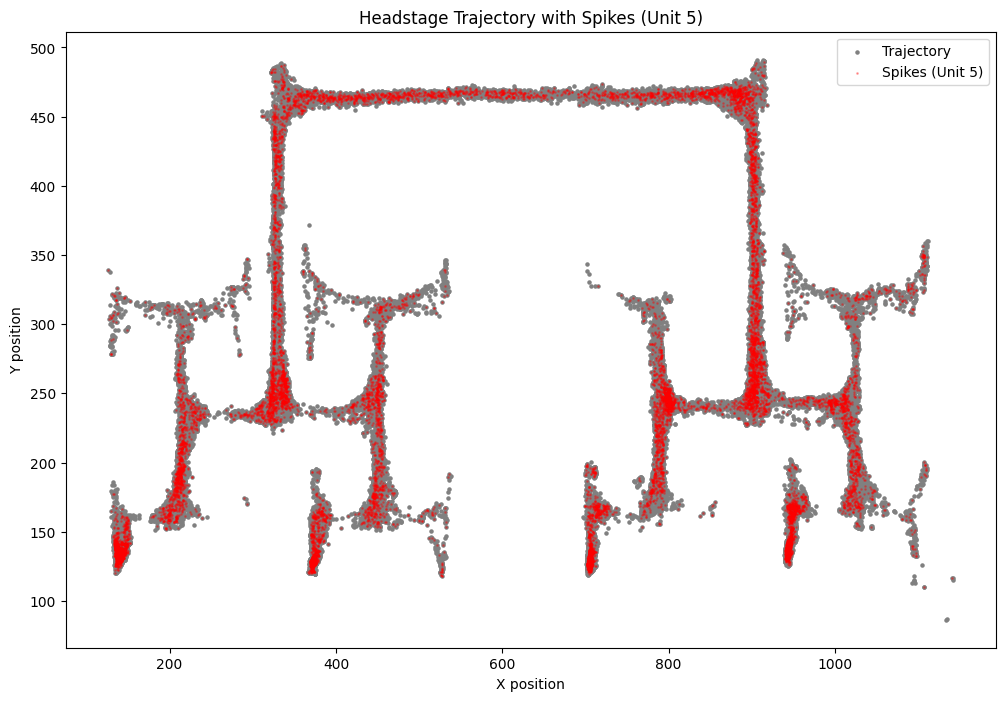

In [88]:
i = 5
# Extract headstage coordinates (assumes DLC format: multi-index columns)
likelihood = h5_file['headstage']['likelihood'].values
valid_mask = likelihood > 0.7
head_x = h5_file['headstage']['x'].values[valid_mask]
head_y = h5_file['headstage']['y'].values[valid_mask]
# head_x = h5_file['headstage']['x'].values
# head_y = h5_file['headstage']['y'].values

# Get spike frames for unit i (use variable 'unit' for the unit index)
spike_times = unit_spike_times_dict[i]
spike_frames = (np.array(spike_times) * 40).astype(int).flatten()

# Filter spike frames to be within the trajectory length
spike_frames = spike_frames[(spike_frames >= 0) & (spike_frames < len(head_x))]

# Get spike positions
spike_x = head_x[spike_frames]
spike_y = head_y[spike_frames]

# plt.gca().invert_xaxis()
plt.figure(figsize=(12, 8))

plt.scatter(head_x, head_y, color='grey', s=5, label='Trajectory', zorder=1)
plt.scatter(spike_x, spike_y, color='red', s=1, label=f'Spikes (Unit {i})', zorder=2, alpha=0.3)
# plt.plot(head_x, head_y, color='grey', linewidth=1, label='Trajectory')
# plt.scatter(spike_x, spike_y, color='red', s=10, label=f'Spikes (Unit 0)')
plt.xlabel('X position')
plt.ylabel('Y position')
plt.title(f'Headstage Trajectory with Spikes (Unit {i})')
plt.legend()
plt.show()

In [45]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec

# -----------------------------------------------------------------------------
# Assumptions:
# - unit_spike_times_dict: dict mapping unit -> spike times (in seconds)
# - data       : pd.DataFrame containing at least a 'tile_id' column per frame
# - tiles_df   : pd.DataFrame with tile info; must have columns:
#                'coordinates' (tuple), 'borders' (list of four booleans),
#                and optionally 'is_graph'
# - tiles_dict : dict mapping tile coordinate tuple to tile id
# - simplified_data: dict holding example waveforms,
#                e.g., simplified_data['example_waveforms']
# - head_x, head_y: np.array with headstage x and y coordinates
#                (from DLC or similar)
# - data_simplified: assumed equivalent to simplified_data for waveforms
# -----------------------------------------------------------------------------

# Destination folder to save the plots
output_folder = '/var/home/almogmeir/Documents/M.Sc/Project/Graphs/21_07_Maze_NPC1/spike_heatmaps'
os.makedirs(output_folder, exist_ok=True)

def visualize_spike_heatmap_with_waveform(tiles_df, freq_dict, unit, waveform, total_spikes, 
                                          head_x, head_y, spike_times, filename=None):
    """
    Create a figure with two main panels:
      - Left panel (larger): the spike heatmap computed from freq_dict over the grid in tiles_df.
      - Right panel (larger horizontally) subdivided vertically into three parts:
           1. Waveform plot (upper part)
           2. Raw headstage trajectory with unit's spikes (middle part; larger area)
           3. Total spike count text (bottom part)
    
    The headstage trajectory plot is drawn using the original data; its y‐axis is inverted
    so that its orientation matches that of the heatmap.
    
    Tiles with NaN spike rates are drawn as white.
    
    Args:
        tiles_df (pd.DataFrame): DataFrame with tile info (must have 'coordinates', 'borders', 'is_graph').
        freq_dict (dict): Mapping from tile id to normalized spike rate (NaN if tile visited < 50 frames overall).
        unit (int): Unit identifier.
        waveform (array-like): Waveform data for the unit.
        total_spikes (int): Total spike count for the unit.
        head_x (np.array): Headstage x-coordinates.
        head_y (np.array): Headstage y-coordinates.
        spike_times (list or np.array): Spike times (in seconds) for the unit.
        filename (str, optional): If provided, the figure is saved to this path.
    """
    # Adjust main grid so that right panel gets more horizontal space using width_ratios=[3,2]
    fig = plt.figure(figsize=(18, 8), constrained_layout=True)
    gs = gridspec.GridSpec(1, 2, width_ratios=[6, 5], figure=fig)
    ax_heat = fig.add_subplot(gs[0, 0])

    # Subdivide the right panel vertically (trajectory:waveform:text = 3:1:1)
    gs_right = gs[0, 1].subgridspec(nrows=3, ncols=1, height_ratios=[2, 4, 1])
    ax_wave = fig.add_subplot(gs_right[0, 0])
    ax_traj = fig.add_subplot(gs_right[1, 0])
    ax_text = fig.add_subplot(gs_right[2, 0])
    
    # ----- Left Panel: Heatmap -----
    cmap = plt.cm.plasma
    # Determine vmin and vmax from non-NaN values.
    valid_freqs = [v for v in freq_dict.values() if not np.isnan(v)]
    vmin = min(valid_freqs) if valid_freqs else 0
    vmax = max(valid_freqs) if valid_freqs else 1
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    
    for _, row in tiles_df.iterrows():
        x, y = row['coordinates']
        tile_id = tiles_dict.get(tuple(row['coordinates']), -1)
        freq = freq_dict.get(tile_id, 0)
        if np.isnan(freq):
            color = 'white'
        else:
            color = cmap(norm(freq))
        rect = plt.Rectangle((x, y), 1, 1, facecolor=color,
                             edgecolor='black' if row.get('is_graph', False) else 'none', linewidth=1)
        ax_heat.add_patch(rect)
        borders = row['borders']
        if borders[0]:
            ax_heat.plot([x, x + 1], [y, y], color='black', linewidth=2)
        if borders[1]:
            ax_heat.plot([x + 1, x + 1], [y, y + 1], color='black', linewidth=2)
        if borders[2]:
            ax_heat.plot([x, x + 1], [y + 1, y + 1], color='black', linewidth=2)
        if borders[3]:
            ax_heat.plot([x, x], [y, y + 1], color='black', linewidth=2)
    
    xs = tiles_df['coordinates'].apply(lambda c: c[0])
    ys = tiles_df['coordinates'].apply(lambda c: c[1])
    ax_heat.set_xlim(xs.min() - 1, xs.max() + 2)
    ax_heat.set_ylim(ys.min() - 1, ys.max() + 2)
    ax_heat.set_aspect('equal')
    ax_heat.invert_yaxis()
    ax_heat.set_title(f'Spike Rate (Hz) per Tile (Unit {unit})')
    ax_heat.set_xticks([])
    ax_heat.set_yticks([])
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array(valid_freqs)
    fig.colorbar(sm, ax=ax_heat, label='Spike Rate (Hz)')
    
    # ----- Top Right: Waveform Plot -----
    
    sampling_rate = 30000  # Hz
    if waveform is not None and len(waveform) > 0:
        x_wave = np.arange(len(waveform))
        time_ms = (x_wave / sampling_rate) * 1000  # convert to ms
        ax_wave.plot(time_ms, waveform, linewidth=1.5, color='tab:blue')
        ax_wave.set_title(f'Waveform (Unit {unit})')
        ax_wave.set_xlabel('Time (ms)')
        ax_wave.set_ylabel('Amplitude')
        ax_wave.set_xlim(0, time_ms[-1])
        ax_wave.grid(True)
    else:
        ax_wave.text(0.5, 0.5, 'No waveform data', ha='center', va='center')
    
    # ----- Middle Right: Raw Headstage Trajectory with Spikes -----
    spike_frames = (np.array(spike_times) * 40).astype(int).flatten()
    valid_frames = (spike_frames >= 0) & (spike_frames < len(head_x))
    spike_frames = spike_frames[valid_frames]

    # Use the original headstage data
    traj_x = head_x
    traj_y = head_y
    spike_traj_x = traj_x[spike_frames]
    spike_traj_y = traj_y[spike_frames]
    
    ax_traj.scatter(traj_x, traj_y, color='grey', s=8, label='Trajectory', zorder=1)
    ax_traj.scatter(spike_traj_x, spike_traj_y, color='red', s=1, label=f'Spikes (Unit {unit})', zorder=2, alpha=0.3)
    ax_traj.set_title('Headstage Trajectory with Spikes')
    ax_traj.set_xlabel('X Position')
    ax_traj.set_ylabel('Y Position')
    ax_traj.legend(fontsize=8)
    ax_traj.invert_yaxis()  # Invert y-axis to match heatmap orientation
    
    # ----- Bottom Right: Total Spike Count Text -----
    ax_text.text(0.5, 0.5, f'Total Spikes:\n{total_spikes}', ha='center', va='center', fontsize=12)
    ax_text.axis('off')
    
    # Use constrained layout engine to avoid colorbar layout error
    fig.set_layout_engine('constrained')
    if filename:
        plt.savefig(filename)
    plt.close(fig)

# -----------------------------------------------------------------------------
# Main Processing Loop:
# Assumes the following have been defined previously:
#   unit_spike_times_dict, data, tiles_df, tiles_dict, simplified_data, head_x, head_y
# -----------------------------------------------------------------------------

# Get total frames per tile from the complete data
raw_tile_time_counts = data['tile_id'].value_counts().to_dict()
# Ensure every tile defined in tiles_dict appears in the mapping (with 0 if absent)
all_tile_ids = set(tiles_dict.values())
tile_time_counts = {tid: raw_tile_time_counts.get(tid, 0) for tid in all_tile_ids}

num_units = len(unit_spike_times_dict)

for unit in range(587, num_units):
    spike_times = unit_spike_times_dict[unit]
    spike_frames = (np.array(spike_times) * 40).astype(int)
    
    # Map spike frames to tile ids using the data DataFrame
    spike_tile_ids = []
    for frame in spike_frames:
        if frame < len(data):
            tile_id = data.iloc[frame]['tile_id']
            if isinstance(tile_id, pd.Series):
                tile_id = tile_id.values[0]
            spike_tile_ids.append(int(tile_id))
    
    spike_counts = {}
    for tid in spike_tile_ids:
        spike_counts[tid] = spike_counts.get(tid, 0) + 1

    # Compute normalized spike rates using the full tile_time_counts;
    # For tiles with fewer than 50 frames overall, set the value to NaN.
    normalized_spike_counts = {}
    for tid, frames in tile_time_counts.items():
        if frames < 20:
            normalized_spike_counts[tid] = np.nan
        else:
            time_in_tile = frames / 40  # seconds
            normalized_spike_counts[tid] = spike_counts.get(tid, 0) / time_in_tile

    # Retrieve the waveform for this unit (assumes waveforms stored in data_simplified['example_waveforms'])
    waveform = np.array(data_simplified['example_waveforms']).squeeze()[unit]
    
    total_spikes = len(spike_times)
    
    filename = os.path.join(output_folder, f'combined_heatmap_waveform_unit_{unit}.png')
    
    visualize_spike_heatmap_with_waveform(test_tiles, normalized_spike_counts, unit, waveform, total_spikes,
                                          head_x, head_y, spike_times, filename=filename)
    print(f"Saved combined plot for Unit {unit} to {filename}")

Saved combined plot for Unit 587 to /var/home/almogmeir/Documents/M.Sc/Project/Graphs/21_07_Maze_NPC1/spike_heatmaps/combined_heatmap_waveform_unit_587.png
Saved combined plot for Unit 588 to /var/home/almogmeir/Documents/M.Sc/Project/Graphs/21_07_Maze_NPC1/spike_heatmaps/combined_heatmap_waveform_unit_588.png
Saved combined plot for Unit 589 to /var/home/almogmeir/Documents/M.Sc/Project/Graphs/21_07_Maze_NPC1/spike_heatmaps/combined_heatmap_waveform_unit_589.png
Saved combined plot for Unit 590 to /var/home/almogmeir/Documents/M.Sc/Project/Graphs/21_07_Maze_NPC1/spike_heatmaps/combined_heatmap_waveform_unit_590.png
Saved combined plot for Unit 591 to /var/home/almogmeir/Documents/M.Sc/Project/Graphs/21_07_Maze_NPC1/spike_heatmaps/combined_heatmap_waveform_unit_591.png
Saved combined plot for Unit 592 to /var/home/almogmeir/Documents/M.Sc/Project/Graphs/21_07_Maze_NPC1/spike_heatmaps/combined_heatmap_waveform_unit_592.png
Saved combined plot for Unit 593 to /var/home/almogmeir/Document

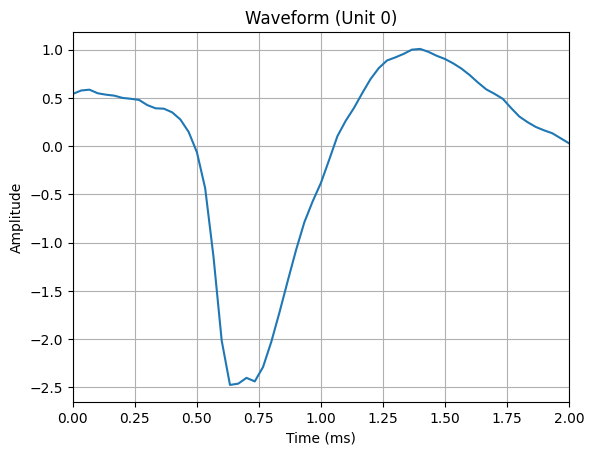

In [100]:
waveform_0 = np.array(data_simplified['example_waveforms']).squeeze()[0]
x_wave_0 = np.arange(len(waveform_0))
time_ms_0 = (x_wave_0 / 30000) * 1000  # convert to ms

plt.plot(time_ms_0, waveform_0, linewidth=1.5, color='tab:blue')
plt.title(f'Waveform (Unit {0})')
plt.xlabel('Time (ms)')
plt.ylabel('Amplitude')
plt.xlim(0, time_ms_0[-1])
plt.grid(True)

In [55]:
(np.array(unit_spike_times_dict[0]) * 40)

array([[2.32800000e+00],
       [8.44133333e+00],
       [1.61306667e+01],
       ...,
       [1.28853812e+05],
       [1.28855164e+05],
       [1.28858055e+05]], shape=(69463, 1))

In [56]:
unit_spike_times_dict[0][-1]

array([3221.45136667])

In [53]:
freq_dict_10 = data[:10*60*40]['tile_id'].value_counts().to_dict()
freq_dict_20 = data[10*60*40:20*60*40]['tile_id'].value_counts().to_dict()
freq_dict_30 = data[20*60*40:30*60*40]['tile_id'].value_counts().to_dict()
freq_dict_40 = data[30*60*40:40*60*40]['tile_id'].value_counts().to_dict()
freq_dict_50 = data[40*60*40:50*60*40]['tile_id'].value_counts().to_dict()
freq_dict_60 = data[50*60*40:60*60*40]['tile_id'].value_counts().to_dict()
freq_dict_70 = data[60*60*40:]['tile_id'].value_counts().to_dict()

In [107]:
data[60*60*40:]

coords,x,y,likelihood,tile_box,tile_id,tree_position
144000,173.972144,191.839682,0.908685,"[136, 133, 28, 28]",80.0,20
144001,174.495633,193.040463,0.900130,"[136, 133, 28, 28]",80.0,20
144002,174.403705,193.223216,0.892112,"[136, 133, 28, 28]",80.0,20
144003,174.550394,194.877342,0.876527,"[136, 133, 28, 28]",80.0,20
144004,173.519394,197.767642,0.833933,"[136, 133, 28, 28]",80.0,20
...,...,...,...,...,...,...
182625,117.926651,134.035004,0.764453,"[107, 75, 28, 28]",27.0,"(30, 40)"
182626,116.692673,133.840576,0.776231,"[107, 75, 28, 28]",27.0,"(30, 40)"
182627,115.411858,131.947937,0.808754,"[107, 75, 28, 28]",27.0,"(30, 40)"
182628,113.448509,128.816147,0.715322,"[107, 75, 28, 28]",27.0,"(30, 40)"


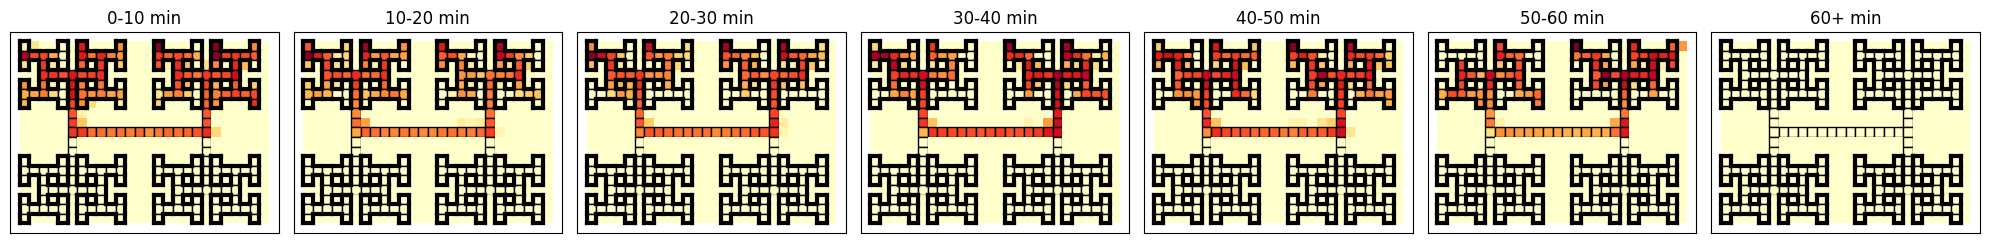

In [54]:
import numpy as np

import matplotlib.pyplot as plt

def visualize_maze_heatmap_subplot(ax, tiles_df, freq_dict, title):
    """
    Visualize the entire grid with colors for each tile based on frequency (heatmap-like) on a given subplot.

    Args:
      ax: Matplotlib Axes object to plot on.
      tiles_df (pd.DataFrame): DataFrame containing tile information with 'coordinates', 'borders',
                               and optionally 'tile_id' (if not present, the DataFrame index is used).
      freq_dict (dict): Mapping of tile id (or index) to frequency.
      title (str): Title for the subplot.
    """
    # Apply log scale to frequencies
    freq_dict = {k: np.emath.logn(2, v) for k, v in freq_dict.items()}
    cmap = plt.cm.YlOrRd  # You can change this to another colormap (e.g., plt.cm.viridis)

    # Set up the colormap and normalization from the frequency dictionary:
    if freq_dict:
        vmin = min(freq_dict.values())
        vmax = max(freq_dict.values())
    else:
        vmin, vmax = 0, 1
    norm = plt.Normalize(vmin=vmin, vmax=vmax)

    # Draw each tile with a color given by its frequency and add gray border for graph tiles:
    for idx, row in tiles_df.iterrows():
        x, y = row['coordinates']
        tile_id = tiles_dict.get(tuple(row['coordinates']), -1)
        freq = freq_dict.get(tile_id, 0)
        color = cmap(norm(freq))
        rect = plt.Rectangle((x, y), 1, 1, facecolor=color, edgecolor='black' if row['is_graph'] else 'none', linewidth=1)
        ax.add_patch(rect)

        borders = row['borders']
        if borders[0]:  # Top border
            ax.plot([x, x + 1], [y, y], color='black', linewidth=3)
        if borders[1]:  # Right border
            ax.plot([x + 1, x + 1], [y, y + 1], color='black', linewidth=3)
        if borders[2]:  # Bottom border
            ax.plot([x, x + 1], [y + 1, y + 1], color='black', linewidth=3)
        if borders[3]:  # Left border
            ax.plot([x, x], [y, y + 1], color='black', linewidth=3)

    # Set plot limits
    xs = tiles_df['coordinates'].apply(lambda c: c[0])
    ys = tiles_df['coordinates'].apply(lambda c: c[1])
    ax.set_xlim(xs.min() - 1, xs.max() + 2)
    ax.set_ylim(ys.min() - 1, ys.max() + 2)
    ax.set_aspect('equal')
    ax.invert_yaxis()

    # Set the title and labels
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

# Create a larger figure with subplots
fig, axes = plt.subplots(1, 7, figsize=(20, 5))

# Plot each heatmap on a subplot
freq_dicts = [freq_dict_10, freq_dict_20, freq_dict_30, freq_dict_40, freq_dict_50, freq_dict_60, freq_dict_70]
titles = ["0-10 min", "10-20 min", "20-30 min", "30-40 min", "40-50 min", "50-60 min", "60+ min"]

for ax, freq_dict, title in zip(axes, freq_dicts, titles):
    visualize_maze_heatmap_subplot(ax, test_tiles, freq_dict, title)

# Adjust layout and show the figure
plt.tight_layout()
plt.show()

In [ ]:
# def count_turn_directions(data, tiles_dict, G, full_turns):
#     """
#     Count left, right, straight turns over time in maze navigation.
    
#     Parameters:
#         data: pd.DataFrame with a 'tile_id' column (time-series).
#         tiles_dict: dict mapping tile_id to coordinate (node in G).
#         G: networkx graph where nodes are coordinates.
#         full_turns: DataFrame with columns ['prev', 'curr', 'next', 'direction']
    
#     Returns:
#         A dict with counts for 'left', 'right', 'straight'
#     """
#     from collections import Counter

#     # Create a set of valid turn tuples for fast lookup
#     valid_turns_set = set(
#         tuple(row) for row in full_turns[['prev', 'curr', 'next']].itertuples(index=False, name=None)
#     )
#     direction_map = {
#         (row.prev, row.curr, row.next): row.direction
#         for row in full_turns.itertuples(index=False)
#     }

#     # Initialize state
#     result = Counter()
#     buffer = []

#     for tile_id in data['tile_id']:
#         # Skip if not in tiles_dict or not in G
#         if tile_id not in tiles_dict.values():
#             continue
#         coord = get_key_from_value(tiles_dict, tile_id)
#         if coord not in G:
#             continue

#         # Skip if same as last added
#         if buffer and coord == buffer[-1]:
#             continue

#         buffer.append(coord)

#         if len(buffer) < 3:
#             continue

#         # Once we have 3 unique coords, check if it's a known turn
#         triplet = tuple(buffer[-3:])
#         if triplet in valid_turns_set:
#             direction = direction_map[triplet]
#             result[direction] += 1
#             # Slide window: remove first
#             buffer = buffer[-2:]
#         else:
#             # Remove the first to try a new triplet next time
#             buffer.pop(0)

#     return dict(result)

# # Example usage:
# turn_counts = count_turn_directions(data, tiles_dict, G, full_turns_df)

In [ ]:
# def turn_directions(data, tiles_dict, G, full_turns):
#     """
#     Count left, right, straight turns over time in maze navigation and keep turn tuples.

#     Parameters:
#         data: pd.DataFrame with a 'tile_id' column (time-series).
#         tiles_dict: dict mapping tile_id to coordinate (node in G).
#         G: networkx graph where nodes are coordinates.
#         full_turns: DataFrame with columns ['prev', 'curr', 'next', 'direction']

#     Returns:
#         A tuple with:
#             - A dict with counts for 'left', 'right', 'straight'
#             - A list of (prev, curr, next, direction) tuples
#     """
#     from collections import Counter

#     # Create a set of valid turn tuples for fast lookup
#     valid_turns_set = set(
#         tuple(row) for row in full_turns[['prev', 'curr', 'next']].itertuples(index=False, name=None)
#     )
#     direction_map = {
#         (row.prev, row.curr, row.next): row.direction
#         for row in full_turns.itertuples(index=False)
#     }

#     # Initialize state
#     result = Counter()
#     buffer = []
#     turn_tuples = []

#     for tile_id in data['tile_id']:
#         # Skip if not in tiles_dict or not in G
#         if tile_id not in tiles_dict.values():
#             continue
#         coord = get_key_from_value(tiles_dict, tile_id)
#         if coord not in G:
#             continue

#         # Skip if same as last added
#         if buffer and coord == buffer[-1]:
#             continue

#         buffer.append(coord)

#         if len(buffer) < 3:
#             continue

#         # Once we have 3 unique coords, check if it's a known turn
#         triplet = tuple(buffer[-3:])
#         if triplet in valid_turns_set:
#             direction = direction_map[triplet]
#             result[direction] += 1
#             turn_tuples.append((triplet[0], triplet[1], triplet[2], direction))
#             # Slide window: remove first
#             buffer = buffer[-2:]
#         else:
#             # Remove the first to try a new triplet next time
#             buffer.pop(0)

#     return dict(result), turn_tuples

# # Example usage:
# turn_counts, turn_tuples = turn_directions(data, tiles_dict, G, full_turns_df)

[((7, 10), (21, 10), (21, 4), 'left', 1.475),
 ((21, 10), (21, 4), (24, 4), 'right', 1.0),
 ((21, 4), (24, 4), (24, 2), 'left', 0.5),
 ((24, 4), (24, 2), (22, 2), 'left', 0.975),
 ((24, 2), (22, 2), (22, 1), 'right', 1.025),
 ((7, 4), (10, 4), (10, 2), 'left', 0.475),
 ((10, 4), (10, 2), (8, 2), 'left', 0.55),
 ((10, 2), (8, 2), (8, 1), 'right', 2.65),
 ((10, 4), (7, 4), (4, 4), 'straight', 2.15),
 ((7, 4), (4, 4), (4, 2), 'right', 0.525),
 ((4, 4), (4, 2), (2, 2), 'left', 0.5),
 ((2, 2), (4, 2), (4, 4), 'right', 0.3),
 ((4, 2), (4, 4), (7, 4), 'left', 0.225),
 ((4, 4), (7, 4), (7, 10), 'right', 1.0),
 ((2, 7), (2, 6), (2, 5), 'straight', 0.325),
 ((2, 5), (2, 6), (2, 7), 'straight', 0.5),
 ((7, 4), (10, 4), (10, 2), 'left', 0.4),
 ((10, 4), (10, 2), (12, 2), 'right', 0.75),
 ((10, 2), (12, 2), (12, 1), 'left', 0.125),
 ((12, 1), (12, 2), (10, 2), 'right', 0.725),
 ((12, 2), (10, 2), (8, 2), 'straight', 0.575),
 ((10, 2), (8, 2), (8, 1), 'right', 0.475),
 ((8, 1), (8, 2), (8, 3), 'stra

In [82]:
turn_counts

{'left': 624, 'right': 646, 'straight': 165}

In [690]:
data[13*40:14*40]

coords,x,y,likelihood,tile_box,tile_id,tree_position
599,813.760742,699.458618,0.800229,"[542, 481, 28, 28]",406.0,310
600,813.760742,688.092773,0.841640,"[542, 481, 28, 28]",406.0,310
601,813.760742,680.094543,0.799095,"[542, 481, 28, 28]",406.0,310
602,814.026978,671.672119,0.659778,"[542, 481, 28, 28]",406.0,310
603,814.271912,662.430237,0.714345,"[542, 452, 28, 28]",380.0,"(310, 420)"
604,814.616882,656.659058,0.665567,"[542, 452, 28, 28]",380.0,"(310, 420)"
605,815.199097,649.718506,0.701979,"[542, 452, 28, 28]",380.0,"(310, 420)"
606,843.414184,684.359365,0.878408,"[571, 481, 28, 28]",407.0,"(25, 310)"
607,843.780585,684.438787,0.901987,"[571, 481, 28, 28]",407.0,"(25, 310)"
608,816.657532,646.519043,0.602582,"[542, 452, 28, 28]",380.0,"(310, 420)"


In [117]:
# Convert turn_tuples to a DataFrame for easier manipulation
turns_df = pd.DataFrame(turn_tuples, columns=["prev", "curr", "next", "direction", "reaction_time_sec", "abs_time_sec"])

# Calculate the average reaction time for each direction
average_reaction_times = turns_df.groupby("direction")["reaction_time_sec"].mean()
std_reaction_times = turns_df.groupby("direction")["reaction_time_sec"].std()
min_reaction_times = turns_df.groupby("direction")["reaction_time_sec"].min()
max_reaction_times = turns_df.groupby("direction")["reaction_time_sec"].max()

print("Mean Reaction Time", average_reaction_times)
print("STD Reaction Time", std_reaction_times)
print("Min Reaction Time", min_reaction_times)
print("Max Reaction Time", max_reaction_times)

Mean Reaction Time direction
left        1.363343
right       1.196633
straight    0.858520
Name: reaction_time_sec, dtype: float64
STD Reaction Time direction
left        1.984727
right       1.502702
straight    1.408940
Name: reaction_time_sec, dtype: float64
Min Reaction Time direction
left        0.025
right       0.025
straight    0.025
Name: reaction_time_sec, dtype: float64
Max Reaction Time direction
left        28.10
right       21.90
straight    17.35
Name: reaction_time_sec, dtype: float64


In [118]:
turns_df

,prev,curr,next,direction,reaction_time_sec,abs_time_sec
0,"(4, 6)","(4, 4)","(4, 2)",straight,0.450,6.025
1,"(4, 2)","(4, 4)","(4, 6)",straight,0.375,21.950
2,"(2, 7)","(2, 6)","(2, 5)",straight,0.600,23.675
3,"(7, 4)","(7, 10)","(7, 16)",straight,1.275,26.750
4,"(4, 14)","(2, 14)","(2, 15)",left,0.125,30.625
...,...,...,...,...,...,...
1110,"(2, 6)","(4, 6)","(4, 4)",left,0.925,4476.100
1111,"(6, 3)","(6, 2)","(4, 2)",left,1.125,4535.150
1112,"(6, 2)","(4, 2)","(2, 2)",straight,1.425,4535.175
1113,"(4, 2)","(2, 2)","(2, 1)",right,0.075,4536.300


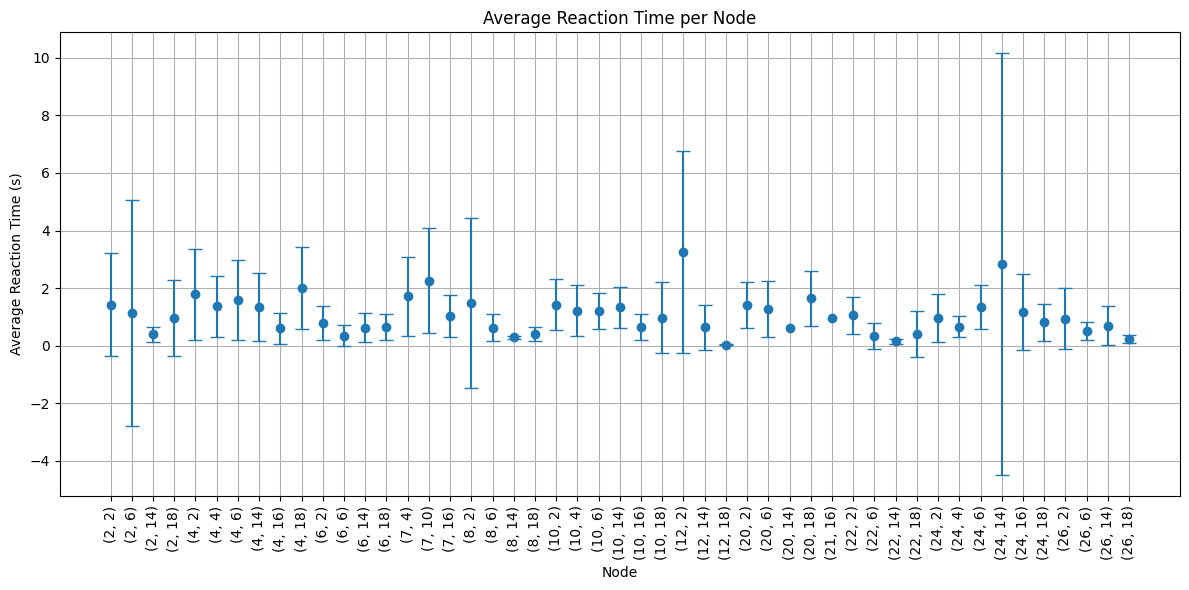

In [119]:
# Calculate the average reaction time for each direction
average_reaction_times = turns_df.groupby("curr")["reaction_time_sec"].mean()
std_reaction_times = turns_df.groupby("curr")["reaction_time_sec"].std()
min_reaction_times = turns_df.groupby("curr")["reaction_time_sec"].min()
max_reaction_times = turns_df.groupby("curr")["reaction_time_sec"].max()

# print("Mean Reaction Time", average_reaction_times)
# print("STD Reaction Time", std_reaction_times)

# Plot the average and std reaction times for each node
plt.figure(figsize=(12, 6))
# Convert the index to a list of strings to avoid issues with non-scalar values
x_values = [str(index) for index in average_reaction_times.index]
# Sort nodes by reaction time
# average_reaction_times = average_reaction_times.sort_values()

# Plot the error bar with properly formatted x and y values
plt.errorbar(x_values, average_reaction_times, yerr=std_reaction_times, fmt='o', capsize=5)
plt.title('Average Reaction Time per Node')
plt.xlabel('Node')
plt.ylabel('Average Reaction Time (s)')
plt.xticks(rotation=90)
plt.grid()
plt.tight_layout()
plt.show()

In [120]:
def compute_node_levels(G):
    """
    Compute the level of each node in the graph based on the distance from the leaves.
    Leaves are set to level 0, and levels increase as you traverse up the tree.

    Args:
        G (networkx.Graph): The graph.

    Returns:
        pd.DataFrame: A DataFrame with columns ['node', 'level'].
    """
    # Find all leaf nodes (nodes with degree 1)
    leaves = [node for node in G.nodes if G.degree[node] == 1]

    # Initialize levels dictionary
    levels = {node: None for node in G.nodes}

    # Set leaves to level 0
    for leaf in leaves:
        levels[leaf] = 0

    # Perform BFS to assign levels to all nodes
    queue = leaves[:]
    while queue:
        current = queue.pop(0)
        current_level = levels[current]

        for neighbor in G.neighbors(current):
            if levels[neighbor] is None:  # If the neighbor's level is not set
                levels[neighbor] = current_level + 1
                queue.append(neighbor)

    # Convert levels dictionary to a DataFrame
    levels_df = pd.DataFrame(list(levels.items()), columns=['node', 'level'])
    return levels_df

# Example usage
node_levels_df = compute_node_levels(G)
print(node_levels_df)

         node  level
0      (2, 1)      0
1      (2, 2)      1
2      (2, 3)      0
3      (2, 5)      0
4      (2, 6)      1
..        ...    ...
121  (26, 14)      1
122  (26, 15)      0
123  (26, 17)      0
124  (26, 18)      1
125  (26, 19)      0

[126 rows x 2 columns]


In [121]:
# Add the level of each node to turns_df
node_levels_dict = dict(zip(node_levels_df['node'], node_levels_df['level']))
turns_df['level'] = turns_df['curr'].map(node_levels_dict)

# Add a new boolean column named "reward" and set all values to False
turns_df['to_reward'] = False
turns_df['from_reward'] = False

# Display the updated DataFrame
turns_df.head()

,prev,curr,next,direction,reaction_time_sec,abs_time_sec,level,to_reward,from_reward
0,"(4, 6)","(4, 4)","(4, 2)",straight,0.450,6.025,3,False,False
1,"(4, 2)","(4, 4)","(4, 6)",straight,0.375,21.950,3,False,False
2,"(2, 7)","(2, 6)","(2, 5)",straight,0.600,23.675,1,False,False
3,"(7, 4)","(7, 10)","(7, 16)",straight,1.275,26.750,5,False,False
4,"(4, 14)","(2, 14)","(2, 15)",left,0.125,30.625,1,False,False


In [122]:
# Manually set up the reward locations

turns_df.loc[turns_df['next'] == (2, 1), 'to_reward'] = True
turns_df.loc[turns_df['next'] == (8, 1), 'to_reward'] = True
turns_df.loc[turns_df['next'] == (20, 1), 'to_reward'] = True
turns_df.loc[turns_df['next'] == (26, 7), 'to_reward'] = True
turns_df.loc[turns_df['next'] == (8, 19), 'to_reward'] = True
turns_df.loc[turns_df['next'] == (26, 13), 'to_reward'] = True
turns_df.loc[turns_df['next'] == (16, 19), 'to_reward'] = True

turns_df.loc[turns_df['prev'] == (2, 1), 'from_reward'] = True
turns_df.loc[turns_df['prev'] == (8, 1), 'from_reward'] = True
turns_df.loc[turns_df['prev'] == (20, 1), 'from_reward'] = True
turns_df.loc[turns_df['prev'] == (26, 7), 'from_reward'] = True
turns_df.loc[turns_df['prev'] == (8, 19), 'from_reward'] = True
turns_df.loc[turns_df['prev'] == (26, 13), 'from_reward'] = True
turns_df.loc[turns_df['prev'] == (16, 19), 'from_reward'] = True

In [123]:
to_reward_count = turns_df[turns_df['to_reward'] == True].shape[0]
from_reward_count = turns_df[turns_df['from_reward'] == True].shape[0]
print(to_reward_count)
print(from_reward_count)

61
58


In [124]:
turns_df

,prev,curr,next,direction,reaction_time_sec,abs_time_sec,level,to_reward,from_reward
0,"(4, 6)","(4, 4)","(4, 2)",straight,0.450,6.025,3,False,False
1,"(4, 2)","(4, 4)","(4, 6)",straight,0.375,21.950,3,False,False
2,"(2, 7)","(2, 6)","(2, 5)",straight,0.600,23.675,1,False,False
3,"(7, 4)","(7, 10)","(7, 16)",straight,1.275,26.750,5,False,False
4,"(4, 14)","(2, 14)","(2, 15)",left,0.125,30.625,1,False,False
...,...,...,...,...,...,...,...,...,...
1110,"(2, 6)","(4, 6)","(4, 4)",left,0.925,4476.100,2,False,False
1111,"(6, 3)","(6, 2)","(4, 2)",left,1.125,4535.150,1,False,False
1112,"(6, 2)","(4, 2)","(2, 2)",straight,1.425,4535.175,2,False,False
1113,"(4, 2)","(2, 2)","(2, 1)",right,0.075,4536.300,1,True,False


In [125]:
def extract_all_sequences(turns_df):
    """
    Extract sequences of consecutive turns from turns_df.

    Parameters:
        turns_df (pd.DataFrame): DataFrame containing turn data.

    Returns:
        pd.DataFrame: DataFrame containing sequences with first node, last node, and total time.
    """
    sequences = []
    start_idx = 0

    for i in range(1, len(turns_df)):
        # Check if the sequence breaks
        if turns_df.iloc[i - 1]['next'] != turns_df.iloc[i]['curr'] and \
            not (turns_df.iloc[i - 1]['curr'] == turns_df.iloc[i]['curr'] and turns_df.iloc[i - 1]['next'] == turns_df.iloc[i]['prev']):
            # Ensure the sequence has at least 2 rows
            # if i - start_idx > 1:
            start_node = turns_df.iloc[start_idx]['prev']
            end_node = turns_df.iloc[i - 1]['next']
            start_time = turns_df.iloc[start_idx]['abs_time_sec']
            end_time = turns_df.iloc[i - 1]['abs_time_sec']
            total_time = end_time - start_time + turns_df.iloc[i-1]['reaction_time_sec']
            total_nodes = i - start_idx
            sequences.append({'first_node': start_node, 'last_node': end_node, 'start_time': start_time, 
                                'total_time': total_time, 'total_nodes': total_nodes, 'turns_df_start_idx': start_idx})
            start_idx = i

    # Add the last sequence if it has at least 2 rows
    if len(turns_df) - start_idx > 1:
        start_node = turns_df.iloc[start_idx]['curr']
        end_node = turns_df.iloc[len(turns_df) - 1]['next']
        start_time = turns_df.iloc[start_idx]['abs_time_sec']
        end_time = turns_df.iloc[len(turns_df) - 1]['abs_time_sec']
        total_time = end_time - start_time
        total_nodes = len(turns_df) - start_idx
        sequences.append({'first_node': start_node, 'last_node': end_node, 'start_time': start_time, 'total_time': total_time, 'total_nodes': total_nodes, 'turns_df_start_idx': start_idx})

    return pd.DataFrame(sequences)

# Create the sequences DataFrame
full_sequences_df = extract_all_sequences(turns_df)
# Filter out sequences with less than 2 nodes
sequences_df = full_sequences_df[full_sequences_df['total_nodes'] > 2]
sequences_df

,first_node,last_node,start_time,total_time,total_nodes,turns_df_start_idx
6,"(4, 16)","(2, 3)",43.450,8.675,6,8
8,"(6, 7)","(4, 4)",67.975,1.400,3,15
11,"(26, 7)","(26, 6)",85.400,14.725,8,20
17,"(7, 10)","(2, 17)",161.975,2.625,4,34
20,"(10, 18)","(8, 15)",183.425,3.550,4,40
...,...,...,...,...,...,...
367,"(2, 5)","(4, 2)",4388.775,10.900,5,1085
371,"(24, 4)","(22, 7)",4423.625,3.375,3,1094
372,"(26, 7)","(22, 1)",4433.450,4.800,6,1097
375,"(21, 10)","(4, 4)",4460.125,16.900,6,1105


In [812]:
turns_df[:10]

,prev,curr,next,direction,reaction_time_sec,abs_time_sec
0,"(21, 16)","(18, 16)","(18, 14)",right,2.300,9.900
1,"(16, 13)","(16, 14)","(16, 15)",straight,0.850,14.425
2,"(18, 18)","(20, 18)","(20, 17)",left,1.550,41.750
3,"(16, 13)","(16, 14)","(16, 15)",straight,0.225,47.300
4,"(22, 15)","(22, 14)","(22, 13)",straight,0.100,50.575
5,"(21, 10)","(21, 4)","(24, 4)",right,1.325,51.100
6,"(26, 1)","(26, 2)","(26, 3)",straight,0.850,54.525
7,"(26, 3)","(26, 2)","(24, 2)",left,0.375,55.875
8,"(22, 3)","(22, 2)","(22, 1)",straight,0.525,58.375
9,"(22, 1)","(22, 2)","(24, 2)",left,1.100,60.775


In [840]:
def extract_reward_to_reward_sequences(turns_df):
    """
    Extract sequences from turns_df that start at a row where 'from_reward' is True and continue 
    as long as one of the two continuity rules holds:
      1. (previous row's 'next' equals current row's 'curr'), OR
      2. (previous row's 'curr' equals current row's 'curr' AND previous row's 'next' equals current row's 'prev')
    The candidate sequence is terminated when:
      - A row with 'to_reward' True is encountered (and the candidate has at least 2 rows), or
      - The continuity rule fails.
      
    Parameters:
        turns_df (pd.DataFrame): DataFrame containing turn data.
            Expected columns: 
                'prev', 'curr', 'next', 'reaction_time_sec', 'abs_time_sec', 'from_reward', 'to_reward'
    
    Returns:
        pd.DataFrame: DataFrame containing sequences with:
            'first_node', 'last_node', 'start_time', 'total_time', 'total_nodes', 'turns_df_start_idx'
    """
    sequences = []
    n = len(turns_df)
    i = 0
    while i < n:
        # Look for a candidate start row (must have from_reward True)
        if not turns_df.iloc[i]['from_reward']:
            i += 1
            continue

        seq_start = i
        seq_end = i  # initialize candidate sequence end index
        j = i + 1
        while j < n:
            row_prev = turns_df.iloc[j - 1]
            row_curr = turns_df.iloc[j]
            # Check continuity with either rule:
            if (row_prev['next'] == row_curr['curr']) or \
               ((row_prev['curr'] == row_curr['curr']) and (row_prev['next'] == row_curr['prev'])):
                seq_end = j
                # If the current row has to_reward True, candidate sequence is complete.
                if row_curr['to_reward']:
                    break
                j += 1
            else:
                break

        # Only record candidate if:
        # - It has at least 2 rows (seq_end > seq_start) and
        # - The candidate sequence ends with a row with to_reward True.
        if seq_end > seq_start and turns_df.iloc[seq_end]['to_reward']:
            first_node = turns_df.iloc[seq_start]['prev']  # using previous node of the first row
            end_node = turns_df.iloc[seq_end]['next']
            start_time = turns_df.iloc[seq_start]['abs_time_sec']
            end_time = turns_df.iloc[seq_end]['abs_time_sec']
            total_time = (end_time - start_time) + turns_df.iloc[seq_end]['reaction_time_sec']
            total_nodes = seq_end - seq_start + 1
            sequences.append({
                'first_node': first_node,
                'last_node': end_node,
                'start_time': start_time,
                'total_time': total_time,
                'total_nodes': total_nodes,
                'turns_df_start_idx': seq_start
            })
            # Advance index beyond the recorded candidate
            i = seq_end + 1
        else:
            i += 1

    import pandas as pd
    return pd.DataFrame(sequences)

# Example usage:
rtr_sequences_df = extract_reward_to_reward_sequences(turns_df)
rtr_sequences_df = rtr_sequences_df[rtr_sequences_df['total_nodes'] > 2]
rtr_sequences_df

,first_node,last_node,start_time,total_time,total_nodes,turns_df_start_idx
2,"(8, 1)","(2, 1)",358.225,10.125,9,154
4,"(8, 1)","(2, 1)",444.250,6.625,8,211
7,"(2, 1)","(2, 1)",1192.100,19.425,17,548
8,"(2, 1)","(2, 1)",1351.925,16.325,3,622
9,"(2, 1)","(2, 1)",1622.500,7.600,6,754
10,"(8, 1)","(2, 1)",1771.925,14.250,16,834
11,"(2, 1)","(8, 1)",1786.850,9.700,8,850
12,"(26, 7)","(26, 7)",1912.600,18.225,3,916
13,"(26, 7)","(26, 7)",1931.000,19.800,14,919
14,"(26, 7)","(2, 1)",1952.625,14.850,13,933


In [839]:
turns_df[153:163]

,prev,curr,next,direction,reaction_time_sec,abs_time_sec,level,to_reward,from_reward
153,"(10, 2)","(8, 2)","(8, 1)",right,0.800,355.950,1,True,False
154,"(8, 1)","(8, 2)","(8, 3)",straight,0.250,358.225,1,False,True
155,"(8, 3)","(8, 2)","(10, 2)",right,0.200,359.300,1,False,False
156,"(8, 2)","(10, 2)","(10, 4)",right,0.175,359.675,2,False,False
157,"(10, 2)","(10, 4)","(7, 4)",right,0.500,359.875,3,False,False
158,"(10, 4)","(7, 4)","(7, 10)",left,0.800,360.050,4,False,False
159,"(7, 10)","(7, 4)","(4, 4)",left,0.650,361.350,4,False,False
160,"(7, 4)","(4, 4)","(4, 2)",right,0.400,364.175,3,False,False
161,"(4, 4)","(4, 2)","(2, 2)",left,1.300,364.825,2,False,False
162,"(4, 2)","(2, 2)","(2, 1)",right,1.525,366.825,1,True,False


In [818]:
reward_sequences_df['total_nodes'].value_counts()

total_nodes
5     22
3     21
8     12
2     11
4      8
7      6
9      5
10     3
6      2
Name: count, dtype: int64

In [825]:
def extract_from_reward_sequences(turns_df):
    """
    Extract continuous sequences from turns_df that start at a row where 'from_reward' is True.
    
    A continuous sequence is defined as one where each row's 'next' equals the following row's 'curr'.  
    Only sequences with at least 2 rows are kept.
    
    Parameters:
        turns_df (pd.DataFrame): DataFrame containing turn data.
            Expected columns: 'curr', 'next', 'abs_time_sec', 'from_reward'
    
    Returns:
        pd.DataFrame: Sequences with columns: 'first_node', 'last_node', 'start_time', 'total_time', 'total_nodes'
    """
    sequences = []
    n = len(turns_df)
    i = 0
    while i < n:
        # Look for a candidate sequence starting where from_reward is True.
        if not turns_df.iloc[i]['from_reward']:
            i += 1
            continue
        seq_start = i
        seq_end = i
        j = i + 1
        while j < n:
            if turns_df.iloc[j - 1]['next'] != turns_df.iloc[j]['curr'] or \
                not (turns_df.iloc[j - 1]['curr'] == turns_df.iloc[j]['curr'] and turns_df.iloc[j - 1]['next'] == turns_df.iloc[j]['prev']):
                break
            seq_end = j
            j += 1
        
        total_nodes = seq_end - seq_start + 2
        if total_nodes >= 2:
            first_node = turns_df.iloc[seq_start]['prev']
            last_node = turns_df.iloc[seq_end]['next']
            start_time = turns_df.iloc[seq_start]['abs_time_sec']
            end_time = turns_df.iloc[seq_end]['abs_time_sec']
            total_time = end_time - start_time
            sequences.append({
                'first_node': first_node,
                'last_node': last_node,
                'start_time': start_time,
                'total_time': total_time,
                'total_nodes': total_nodes
            })
        i = seq_end + 1
    
    import pandas as pd
    return pd.DataFrame(sequences)

def extract_to_reward_sequences(turns_df):
    """
    Extract continuous sequences from turns_df that end at a row where 'to_reward' is True.
    
    A continuous sequence is defined as one where each row's 'next' equals the following row's 'curr'.  
    Only sequences with at least 2 rows are kept.
    
    Parameters:
        turns_df (pd.DataFrame): DataFrame containing turn data.
            Expected columns: 'curr', 'next', 'abs_time_sec', 'to_reward'
    
    Returns:
        pd.DataFrame: Sequences with columns: 'first_node', 'last_node', 'start_time', 'total_time', 'total_nodes'
    """
    sequences = []
    n = len(turns_df)
    i = 0
    while i < n:
        seq_start = i
        seq_end = i
        j = i + 1
        while j < n:
            if turns_df.iloc[j - 1]['next'] != turns_df.iloc[j]['curr'] or \
                not (turns_df.iloc[j - 1]['curr'] == turns_df.iloc[j]['curr'] and turns_df.iloc[j - 1]['next'] == turns_df.iloc[j]['prev']):
                break
            seq_end = j
            j += 1

        total_nodes = seq_end - seq_start + 1
        # Only keep sequences with at least 2 rows AND where the last row has to_reward True.
        if turns_df.iloc[seq_end]['to_reward']:
            first_node = turns_df.iloc[seq_start]['curr']
            last_node = turns_df.iloc[seq_end]['next']
            start_time = turns_df.iloc[seq_start]['abs_time_sec']
            end_time = turns_df.iloc[seq_end]['abs_time_sec']
            total_time = end_time - start_time
            sequences.append({
                'first_node': first_node,
                'last_node': last_node,
                'start_time': start_time,
                'total_time': total_time,
                'total_nodes': total_nodes
            })
        i = seq_end + 1

    import pandas as pd
    return pd.DataFrame(sequences)

# Example usage:
from_reward_sequences_df = extract_from_reward_sequences(turns_df)
to_reward_sequences_df = extract_to_reward_sequences(turns_df)

# Merge the two DataFrames
reward_sequences_df = pd.concat([from_reward_sequences_df, to_reward_sequences_df], ignore_index=True)
reward_sequences_df

,first_node,last_node,start_time,total_time,total_nodes
0,"(2, 1)","(2, 3)",112.175,0.0,2
1,"(2, 1)","(2, 3)",167.475,0.0,2
2,"(2, 1)","(4, 2)",174.250,0.0,2
3,"(26, 13)","(24, 14)",207.975,0.0,2
4,"(16, 19)","(18, 18)",219.350,0.0,2
...,...,...,...,...,...
154,"(2, 2)","(2, 1)",2438.800,0.0,1
155,"(8, 2)","(8, 1)",2446.900,0.0,1
156,"(2, 2)","(2, 1)",2501.850,0.0,1
157,"(20, 2)","(20, 1)",2560.600,0.0,1


In [820]:
# Calculate the average total_time and total_nodes
average_time = sequences_df['total_time'].mean()
average_nodes = sequences_df['total_nodes'].mean()
max_time = sequences_df['total_time'].max()
max_nodes = sequences_df['total_nodes'].max()

print(f"Average Time: {average_time}")
print(f"Average Number of Nodes: {average_nodes}")
print(f"Max Time: {max_time}")
print(f"Max Number of Nodes: {max_nodes}")

Average Time: 19.524731182795716
Average Number of Nodes: 11.978494623655914
Max Time: 107.45000000000013
Max Number of Nodes: 72


In [606]:
# Count the number of sequences at given length
sequences_count = sequences_df['total_nodes'].value_counts().sort_index()
print('seq count:', sequences_count)
reward_sequences_count = reward_sequences_df['total_nodes'].value_counts().sort_index()
print('reward seq count:', reward_sequences_count)

seq count: total_nodes
2     14
3     14
4      8
5      3
6     11
7      7
8      4
9      4
10     4
11     2
12     7
14     1
15     4
16     4
17     1
18     2
20     1
21     1
22     1
23     2
24     3
26     2
27     1
28     1
30     3
55     1
72     1
Name: count, dtype: int64
reward seq count: total_nodes
2     56
3     12
4     16
5     22
6      6
7      5
8     10
9      8
10     4
11     1
Name: count, dtype: int64


In [608]:
sequences_count[-10:]

total_nodes
21    1
22    1
23    2
24    3
26    2
27    1
28    1
30    3
55    1
72    1
Name: count, dtype: int64

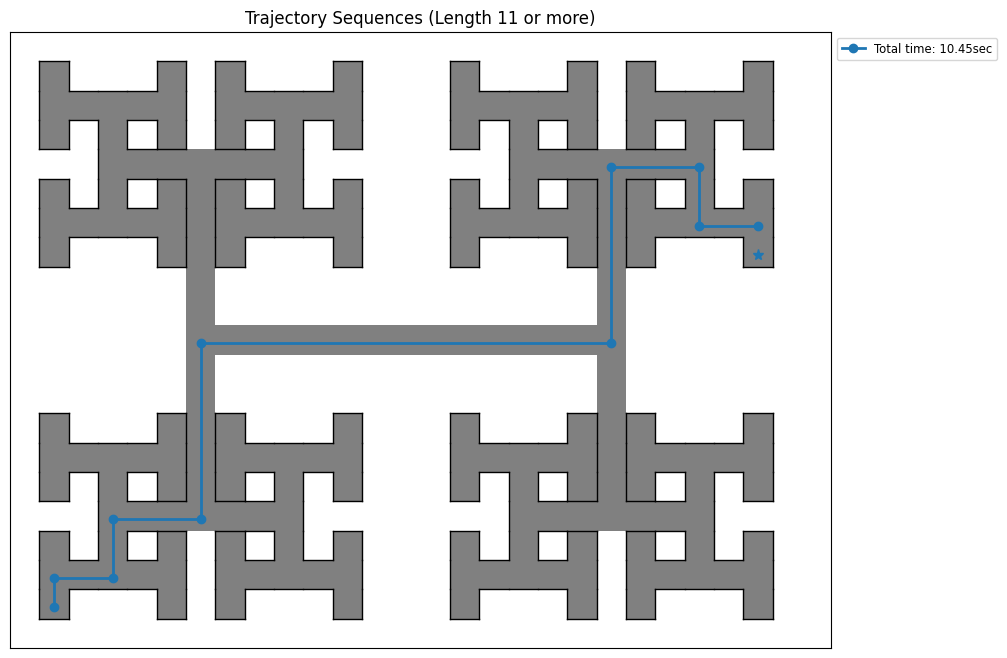

In [592]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

def visualize_sequences_on_tiles(tiles_df, turns_df, sequences_df, sequence_length, export=False):
    """
    Visualize the grid with trajectory sequences overlaid.
    
    Args:
        tiles_df (pd.DataFrame): Contains tile info with columns:
            - 'coordinates': tuple (x, y)
            - 'borders': a list/tuple of booleans for [top, right, bottom, left]
            - 'is_graph': boolean indicating if tile is part of the graph.
        turns_df (pd.DataFrame): Turn events sorted by time.
            Expected columns: ['prev', 'curr', 'next', 'direction', 'reaction_time_sec', 'turn_time_sec', 'abs_time_sec']
        sequences_df (pd.DataFrame): Aggregated sequence info with columns: 
            ['first_node', 'last_node', 'start_time', 'total_nodes']
        sequence_length (int): Only sequences with total_nodes equal to this value are plotted.
        export (bool): If True, saves the plot to disk.
    
    The twist:
        Trajectories that share the same tile will have their point for that tile slightly displaced.
    """
    # Filter sequences_df for sequences with the desired length.
    seq_filtered = sequences_df[sequences_df['total_nodes'] >= sequence_length]
    
    fig, ax = plt.subplots()
    
    # Draw the tile grid.
    for idx, row in tiles_df.iterrows():
        x, y = row['coordinates']
        base_color = 'gray' if row.get('is_graph', False) else 'white'
        rect = plt.Rectangle((x, y), 1, 1, facecolor=base_color, edgecolor='black', linewidth=0)
        ax.add_patch(rect)
        # Draw tile borders (order: top, right, bottom, left)
        if row['borders'][0]:
            ax.plot([x, x + 1], [y, y], color='black', linewidth=1)
        if row['borders'][1]:
            ax.plot([x + 1, x + 1], [y, y + 1], color='black', linewidth=1)
        if row['borders'][2]:
            ax.plot([x, x + 1], [y + 1, y + 1], color='black', linewidth=1)
        if row['borders'][3]:
            ax.plot([x, x], [y, y + 1], color='black', linewidth=1)
    
    # Setup colormap for trajectories.
    cmap = plt.colormaps['tab20']
    traj_count = 0
    # This dictionary will hold, for each tile (by its coordinates), a mapping from sequence ID to an offset.
    tile_offsets = {}
    spacing = 0.1  # maximum displacement per tile
    
    # For each sequence, reconstruct its trajectory from turns_df.
    for seq_id, (_, seq_row) in enumerate(seq_filtered.iterrows()):
        first_node = seq_row['first_node']
        last_node = seq_row['last_node']
        start_time = seq_row['start_time']
        total_time = seq_row['total_time']
        
        # Filter turn events that occur at or after the sequence start time.
        sub_turns = turns_df[turns_df['abs_time_sec'] >= start_time]
        # Build the trajectory. Start with first_node.
        trajectory = [first_node]
        for event in sub_turns.itertuples(index=False):
            # event: (prev, curr, next, direction, reaction_time_sec, turn_time_sec, abs_time_sec)
            if event.prev == trajectory[-1]:
                trajectory.append(event.curr)
                if event.next == last_node:
                    trajectory.append(last_node)
                    break
        if len(trajectory) < 2:
            continue
        
        # For plotting, compute an adjusted center for each tile so that trajectories sharing a tile are offset.
        adjusted_points = []
        for tile in trajectory:
            # Get the default center of the tile.
            center = (tile[0] + 0.5, tile[1] + 0.5)
            # Update tile_offsets: assign an offset for this sequence in this tile.
            if tile not in tile_offsets:
                tile_offsets[tile] = {}  # will hold mapping seq_id -> offset (dx, dy)
            if seq_id not in tile_offsets[tile]:
                # Determine offset: here we use a vertical shift.
                # For example, the nth sequence through a tile is assigned:
                n = len(tile_offsets[tile])
                # Alternate upward and downward: even n upward, odd n downward.
                offset_y = spacing * ((n//2 + 1) if n % 2 == 0 else -(n//2 + 1))
                tile_offsets[tile][seq_id] = (0, offset_y)
            offset = tile_offsets[tile][seq_id]
            adjusted_center = (center[0] + offset[0], center[1] + offset[1])
            adjusted_points.append(adjusted_center)
        
        xs, ys = zip(*adjusted_points)
        color = cmap(traj_count % 10)  # cycle through colors
        # Different marker for start
        ax.plot(xs[0], ys[0], marker='*', color=color, markersize=8)
        ax.plot(xs[1:], ys[1:], marker='o', color=color, linewidth=2, label=f"Total time: {total_time:.2f}sec")
        traj_count += 1

    xs_all = tiles_df['coordinates'].apply(lambda c: c[0])
    ys_all = tiles_df['coordinates'].apply(lambda c: c[1])
    ax.set_xlim(xs_all.min() - 1, xs_all.max() + 2)
    ax.set_ylim(ys_all.min() - 1, ys_all.max() + 2)
    ax.set_aspect('equal')
    plt.gca().invert_yaxis()
    
    ax.set_title(f"Trajectory Sequences (Length {sequence_length} or more)")
    ax.set_xticks([])
    ax.set_yticks([])
    plt.legend()
    # Move the legend so it won't overlap with the plot
    plt.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize='small')
    fig.set_size_inches(12, 8)
    
    if export:
        plt.savefig('/var/home/almogmeir/Documents/M.Sc/Project/Graphs/sequences_trajectories_11.png')
    plt.show()

# Example usage:
visualize_sequences_on_tiles(test_tiles, turns_df, reward_sequences_df, sequence_length=11, export=True)

In [552]:
reward_sequences_df[reward_sequences_df['total_nodes'] >= 10]

,first_node,last_node,start_time,total_time,total_nodes
31,"(2, 1)","(2, 19)",1041.850,7.50,10
65,"(26, 7)","(2, 19)",2059.400,10.45,11
70,"(2, 1)","(20, 14)",2259.400,15.55,10
80,"(22, 2)","(2, 1)",100.400,11.50,10
112,"(26, 2)","(2, 1)",1463.725,9.80,10


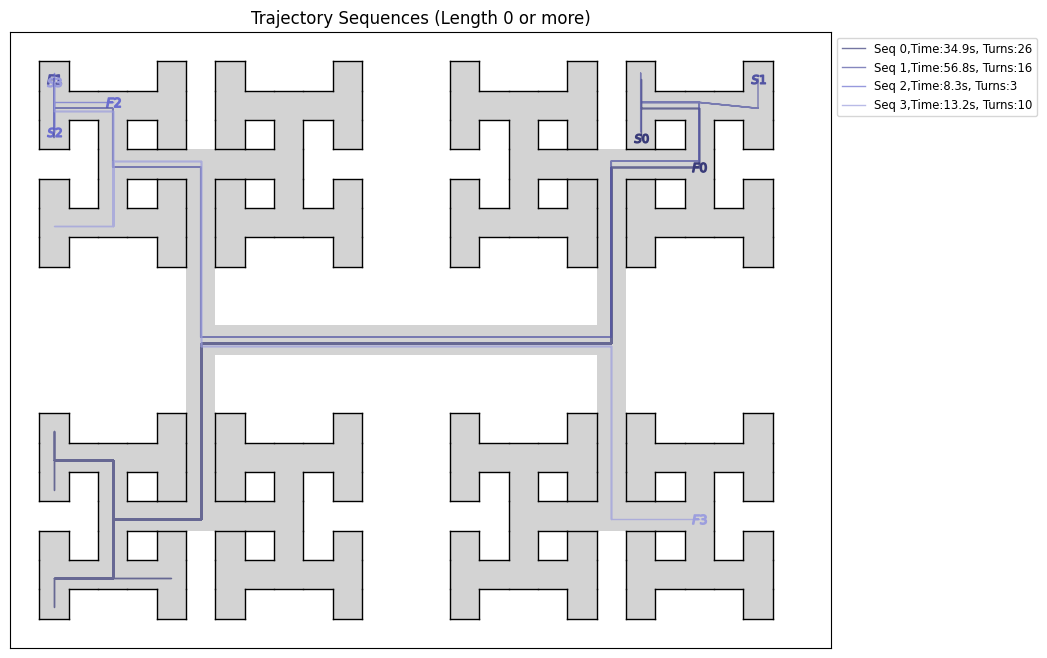

In [884]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

def visualize_sequences_on_tiles(tiles_df, turns_df, sequences_df, sequence_length=0, export=False):
    """
    Visualize the grid with trajectory sequences overlaid.
    
    Args:
        tiles_df (pd.DataFrame): Contains tile info with columns:
            - 'coordinates': tuple (x, y)
            - 'borders': a list/tuple of booleans for [top, right, bottom, left]
            - 'is_graph': boolean indicating if tile is part of the graph.
        turns_df (pd.DataFrame): Turn events sorted by time.
            Expected columns: ['prev', 'curr', 'next', 'direction', 'reaction_time_sec', 'turn_time_sec', 'abs_time_sec']
        sequences_df (pd.DataFrame): Aggregated sequence info with columns: 
            ['first_node', 'last_node', 'start_time', 'total_nodes']
        sequence_length (int): Only sequences with total_nodes equal to this value are plotted.
        export (bool): If True, saves the plot to disk.
    
    The twist:
        Trajectories that share the same tile will have their point for that tile slightly displaced.
    """
    # Filter sequences_df for sequences with the desired length.
    if sequence_length > 0:
        sequences_df = sequences_df[sequences_df['total_nodes'] >= sequence_length]
    
    fig, ax = plt.subplots()
    
    # Draw the tile grid.
    for idx, row in tiles_df.iterrows():
        x, y = row['coordinates']
        base_color = 'lightgray' if row.get('is_graph', False) else 'white'
        rect = plt.Rectangle((x, y), 1, 1, facecolor=base_color, edgecolor='black', linewidth=0)
        ax.add_patch(rect)
        # Draw tile borders (order: top, right, bottom, left)
        if row['borders'][0]:
            ax.plot([x, x + 1], [y, y], color='black', linewidth=1)
        if row['borders'][1]:
            ax.plot([x + 1, x + 1], [y, y + 1], color='black', linewidth=1)
        if row['borders'][2]:
            ax.plot([x, x + 1], [y + 1, y + 1], color='black', linewidth=1)
        if row['borders'][3]:
            ax.plot([x, x], [y, y + 1], color='black', linewidth=1)
    
    # Setup colormap for trajectories.
    cmap = plt.colormaps['tab20b']
    traj_count = 0
    # This dictionary will hold, for each tile (by its coordinates), a mapping from sequence ID to an offset.
    tile_offsets = {}
    spacing = 0.1  # maximum displacement per tile
    
    # For each sequence, reconstruct its trajectory from turns_df.
    for seq_id, (_, seq_row) in enumerate(sequences_df.iterrows()):
        first_node = seq_row['first_node']
        last_node = seq_row['last_node']
        start_time = seq_row['start_time']
        total_time = seq_row['total_time']
        start_idx = seq_row['turns_df_start_idx']
        number_of_nodes = seq_row['total_nodes']
        
        # Filter turn events that occur at or after the sequence start time.
        # sub_turns = turns_df[turns_df['abs_time_sec'] >= start_time]
        sub_turns = turns_df.iloc[start_idx:start_idx + number_of_nodes]
        # Build the trajectory. Start with first_node.
        trajectory = [first_node]
        for event in sub_turns.itertuples(index=False):
            # event: (prev, curr, next, direction, reaction_time_sec, turn_time_sec, abs_time_sec)
            # if event.prev == trajectory[-1]:
            if trajectory[-1] != event.prev: trajectory.append(event.prev) 
            trajectory.append(event.curr)
            trajectory.append(event.next)
        
        # trajectory.append(last_node)
        if len(trajectory) < 2:
            continue
        
        # For plotting, compute an adjusted center for each tile so that trajectories sharing a tile are offset.
        adjusted_points = []
        for tile in trajectory:
            # Get the default center of the tile.
            center = (tile[0] + 0.5, tile[1] + 0.5)
            # Update tile_offsets: assign an offset for this sequence in this tile.
            if tile not in tile_offsets:
                tile_offsets[tile] = {}  # will hold mapping seq_id -> offset (dx, dy)
            if seq_id not in tile_offsets[tile]:
                # Determine offset: here we use a vertical shift.
                # For example, the nth sequence through a tile is assigned:
                n = len(tile_offsets[tile])
                # Alternate upward and downward: even n upward, odd n downward.
                offset_y = spacing * ((n//2 + 1) if n % 2 == 0 else -(n//2 + 1))
                tile_offsets[tile][seq_id] = (0, offset_y)
            offset = tile_offsets[tile][seq_id]
            adjusted_center = (center[0] + offset[0], center[1] + offset[1])
            adjusted_points.append(adjusted_center)
        
        xs, ys = zip(*adjusted_points)
        color = cmap(traj_count % 10)  # cycle through colors
        ax.scatter(xs[0], ys[0], marker=f'$S{seq_id}$', color=color, alpha=1, s=100)
        ax.plot(xs, ys, color=color, markevery=slice(1, -1, 1) ,linewidth=1, alpha=0.7, label=f"Seq {seq_id},Time:{total_time:.1f}s, Turns:{number_of_nodes}")
        ax.scatter(xs[-1], ys[-1], marker=f'$F{seq_id}$', color=color, alpha=1, s=100)

        traj_count += 1

    xs_all = tiles_df['coordinates'].apply(lambda c: c[0])
    ys_all = tiles_df['coordinates'].apply(lambda c: c[1])
    ax.set_xlim(xs_all.min() - 1, xs_all.max() + 2)
    ax.set_ylim(ys_all.min() - 1, ys_all.max() + 2)
    ax.set_aspect('equal')
    plt.gca().invert_yaxis()
    
    ax.set_title(f"Trajectory Sequences (Length {sequence_length} or more)")
    ax.set_xticks([])
    ax.set_yticks([])
    plt.legend()
    # Move the legend so it won't overlap with the plot
    plt.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize='small')
    fig.set_size_inches(12, 8)
    
    if export:
        plt.savefig('/var/home/almogmeir/Documents/M.Sc/Project/Graphs/reward_to_reward_Example1.png')
    plt.show()

# Example usage:
visualize_sequences_on_tiles(test_tiles, turns_df, sequences_df[:4], export=True)

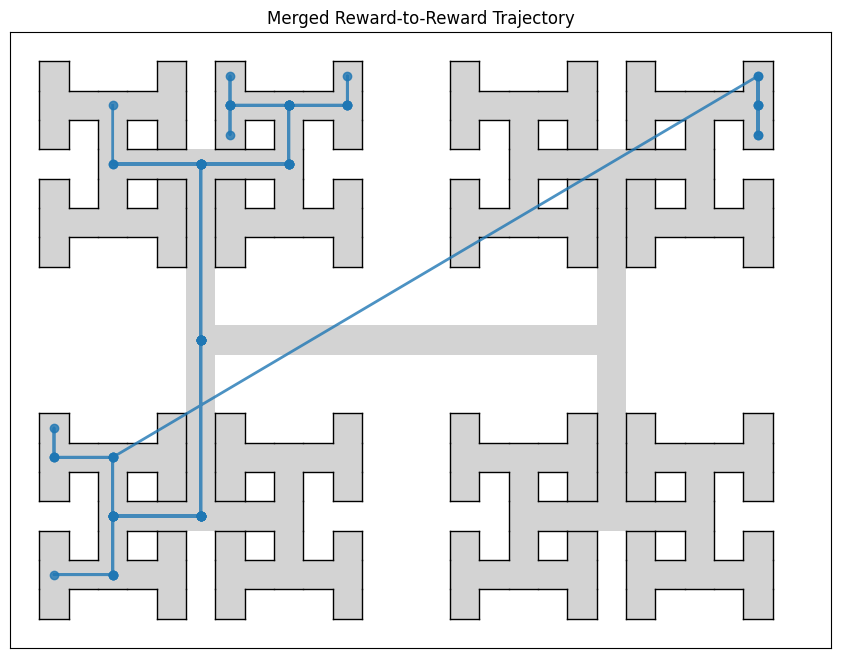

In [918]:
import matplotlib.pyplot as plt
import pandas as pd

def merge_sequences_into_trajectory(turns_df, sequences_df):
    """
    Given a sequences DataFrame (with columns including 'turns_df_start_idx' and 'total_nodes')
    and the turns_df, reconstruct the individual trajectories and merge them in order 
    (sorted by start_time) into one long continuous trajectory.
    
    Returns:
        merged_traj: list of tile coordinates representing the merged trajectory.
    """
    # Sort sequences by start_time.
    # seqs = sequences_df.sort_values('start_time').reset_index(drop=True)
    merged_traj = []
    
    for seq_id, seq_row in sequences_df.iterrows():
        start_idx = seq_row['turns_df_start_idx']
        n_nodes = seq_row['total_nodes']
        # Extract the sub-turns corresponding to the sequence.
        sub_turns = turns_df.iloc[start_idx : start_idx + n_nodes]
        
        # Reconstruct the trajectory for this sequence.
        # We start with the first node from the candidate sequence.
        traj = [seq_row['first_node']]
        for event in sub_turns.itertuples(index=False):
            # Append nodes in order, ensuring no immediate duplicates.
            if traj[-1] != event.prev:
                traj.append(event.prev)
            traj.append(event.curr)
            traj.append(event.next)
        
        # Remove consecutive duplicates.
        filtered = [traj[0]]
        for t in traj[1:]:
            if t != filtered[-1]:
                filtered.append(t)
        
        # Merge: if merged_traj is not empty and its last tile equals the first tile of current sequence,
        # then skip that duplicate.
        if merged_traj and merged_traj[-1] == filtered[0]:
            merged_traj.extend(filtered[1:])
        else:
            merged_traj.extend(filtered)
            
    return merged_traj

def visualize_merged_trajectory_on_tiles(tiles_df, turns_df, sequences_df, export=False):
    """
    Visualize the grid (drawn from tiles_df) and overlay one long merged trajectory that is built 
    by merging all reward-to-reward sequences (from sequences_df) in order.
    
    Args:
        tiles_df (pd.DataFrame): Contains tile info with columns:
            - 'coordinates': tuple (x, y)
            - 'borders': a list/tuple of booleans for [top, right, bottom, left]
            - 'is_graph': boolean indicating if tile is part of the graph.
        turns_df (pd.DataFrame): Turn events sorted by time.
            Expected columns: ['prev', 'curr', 'next', 'direction', 'reaction_time_sec', 'turn_time_sec', 'abs_time_sec']
        sequences_df (pd.DataFrame): Aggregated reward-to-reward sequence info with columns: 
            ['first_node', 'last_node', 'start_time', 'total_nodes', 'turns_df_start_idx', 'total_time']
        export (bool): If True, saves the plot to disk.
    """
    # Merge the trajectories
    merged_traj = merge_sequences_into_trajectory(turns_df, sequences_df)
    
    # Compute centers for all tiles (no additional offset is applied).
    merged_centers = [(tile[0] + 0.5, tile[1] + 0.5) for tile in merged_traj]
    xs, ys = zip(*merged_centers)
    
    fig, ax = plt.subplots()
    
    # Draw the tile grid.
    for idx, row in tiles_df.iterrows():
        x, y = row['coordinates']
        base_color = 'lightgray' if row.get('is_graph', False) else 'white'
        rect = plt.Rectangle((x, y), 1, 1, facecolor=base_color,
                             edgecolor='black', linewidth=0)
        ax.add_patch(rect)
        # Draw borders (order: top, right, bottom, left)
        if row['borders'][0]:
            ax.plot([x, x+1], [y, y], color='black', linewidth=1)
        if row['borders'][1]:
            ax.plot([x+1, x+1], [y, y+1], color='black', linewidth=1)
        if row['borders'][2]:
            ax.plot([x, x+1], [y+1, y+1], color='black', linewidth=1)
        if row['borders'][3]:
            ax.plot([x, x], [y, y+1], color='black', linewidth=1)
    
    # Plot the merged trajectory as one continuous line.
    ax.plot(xs, ys, marker='o', color='tab:blue', linewidth=2, alpha=0.8)
    
    xs_all = tiles_df['coordinates'].apply(lambda c: c[0])
    ys_all = tiles_df['coordinates'].apply(lambda c: c[1])
    ax.set_xlim(xs_all.min()-1, xs_all.max()+2)
    ax.set_ylim(ys_all.min()-1, ys_all.max()+2)
    ax.set_aspect('equal')
    plt.gca().invert_yaxis()
    
    ax.set_title("Merged Reward-to-Reward Trajectory")
    ax.set_xticks([])
    ax.set_yticks([])
    fig.set_size_inches(12, 8)
    
    if export:
        plt.savefig('/var/home/almogmeir/Documents/M.Sc/Project/Graphs/merged_trajectory.png')
    
    plt.show()

# Example usage:
visualize_merged_trajectory_on_tiles(test_tiles, turns_df, sequences_df[7:9], export=False)

In [899]:
sequences_df[7:9]

,first_node,last_node,start_time,total_time,total_nodes,turns_df_start_idx
17,"(4, 2)","(4, 14)",258.075,27.225,28,83
20,"(26, 1)","(26, 3)",291.225,5.500,3,113


In [903]:
turns_df[106:119]


,prev,curr,next,direction,reaction_time_sec,abs_time_sec,level,to_reward,from_reward
106,"(7, 10)","(7, 16)","(4, 16)",right,3.150,275.275,4,False,False
107,"(7, 16)","(4, 16)","(4, 14)",right,1.900,277.825,3,False,False
108,"(4, 16)","(4, 14)","(2, 14)",left,0.525,280.975,2,False,False
109,"(4, 14)","(2, 14)","(2, 13)",right,0.200,282.875,1,False,False
110,"(2, 13)","(2, 14)","(4, 14)",left,0.225,285.075,1,False,False
111,"(7, 16)","(7, 10)","(21, 10)",right,1.925,286.025,5,False,False
112,"(22, 7)","(22, 6)","(22, 5)",straight,0.100,289.250,1,False,False
113,"(26, 1)","(26, 2)","(26, 3)",straight,0.225,291.225,1,False,False
114,"(26, 3)","(26, 2)","(26, 1)",straight,1.500,293.900,1,False,False
115,"(26, 1)","(26, 2)","(26, 3)",straight,0.100,296.625,1,False,False


In [930]:
data[285*40+30:285*40+47]

coords,x,y,likelihood,tile_box,tile_id,tree_position,coordinates
11509,209.344812,631.353977,0.720366,"[136, 423, 28, 28]",340.0,34,"(4, 14)"
11510,235.195374,673.222656,0.726709,"[136, 452, 28, 28]",366.0,"(22, 34)","(4, 15)"
11511,210.380514,628.839799,0.831433,"[136, 423, 28, 28]",340.0,34,"(4, 14)"
11512,214.949973,633.080902,0.850297,"[136, 423, 28, 28]",340.0,34,"(4, 14)"
11513,221.161917,642.597438,0.790150,"[136, 452, 28, 28]",366.0,"(22, 34)","(4, 15)"
11514,288.634308,698.134766,0.655050,"[194, 481, 28, 28]",394.0,"(11, 22)","(6, 16)"
11515,288.634308,699.696228,0.715242,"[194, 481, 28, 28]",394.0,"(11, 22)","(6, 16)"
11516,288.634308,704.280212,0.808493,"[194, 481, 28, 28]",394.0,"(11, 22)","(6, 16)"
11517,293.933868,705.179993,0.842362,"[194, 481, 28, 28]",394.0,"(11, 22)","(6, 16)"
11518,298.829681,705.179993,0.960088,"[194, 481, 28, 28]",394.0,"(11, 22)","(6, 16)"


In [923]:
# Reverse the tiles_dict to map tile_id to coordinates
id_to_coordinates = {v: k for k, v in tiles_dict.items()}

# Map the tile_id in data to the corresponding coordinates
data['coordinates'] = data['tile_id'].map(id_to_coordinates)

/tmp/ipykernel_7955/3135656115.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['coordinates'] = data['tile_id'].map(id_to_coordinates)


In [854]:
sub_turns = turns_df[622:625]
# Build the trajectory. Start with first_node.
trajectory = [(2,1)]
for event in sub_turns.itertuples(index=False):
    # event: (prev, curr, next, direction, reaction_time_sec, turn_time_sec, abs_time_sec)
    if trajectory[-1] != event.prev: trajectory.append(event.prev)
    trajectory.append(event.curr)
    trajectory.append(event.next)

In [855]:
trajectory

[(2, 1), (2, 2), (2, 3), (2, 2), (4, 2), (2, 2), (2, 1)]

In [780]:
turns_df[8:34]

,prev,curr,next,direction,reaction_time_sec,abs_time_sec
8,"(22, 3)","(22, 2)","(22, 1)",straight,0.525,58.375
9,"(22, 1)","(22, 2)","(24, 2)",left,1.100,60.775
10,"(22, 2)","(24, 2)","(24, 4)",right,0.500,60.900
11,"(24, 2)","(24, 4)","(21, 4)",right,0.500,62.000
12,"(24, 4)","(21, 4)","(21, 10)",left,0.750,62.500
13,"(21, 4)","(21, 10)","(7, 10)",right,5.725,63.000
14,"(21, 10)","(7, 10)","(7, 16)",left,1.600,63.750
15,"(7, 10)","(7, 16)","(4, 16)",right,1.125,69.475
16,"(7, 16)","(4, 16)","(4, 14)",right,0.625,71.075
17,"(4, 16)","(4, 14)","(2, 14)",left,0.525,72.200


In [528]:
# save the DataFrames to CSV files
reward_sequences_df.to_csv('/var/home/almogmeir/Documents/M.Sc/Project/Input/reward_sequences.csv', index=False)
sequences_df.to_csv('/var/home/almogmeir/Documents/M.Sc/Project/Input/sequences.csv', index=False)
turns_df.to_csv('/var/home/almogmeir/Documents/M.Sc/Project/Input/turns.csv', index=False)
freq_dict_df = pd.DataFrame(list(freq_dict.items()), columns=['tile_id', 'frequency'])
freq_dict_df.to_csv('/var/home/almogmeir/Documents/M.Sc/Project/Input/freq_dict.csv', index=False)

In [527]:
turns_df

,prev,curr,next,direction,reaction_time_sec,abs_time_sec,level,to_reward,from_reward
0,"(21, 16)","(18, 16)","(18, 14)",right,2.300,11.150,3,False,False
1,"(16, 13)","(16, 14)","(16, 15)",straight,0.850,15.850,1,False,False
2,"(18, 18)","(20, 18)","(20, 17)",left,1.550,43.200,1,False,False
3,"(16, 13)","(16, 14)","(16, 15)",straight,0.225,47.825,1,False,False
4,"(22, 15)","(22, 14)","(22, 13)",straight,0.100,50.750,1,False,False
...,...,...,...,...,...,...,...,...,...
1193,"(4, 4)","(4, 2)","(2, 2)",left,0.400,2613.400,2,False,False
1194,"(4, 2)","(2, 2)","(2, 1)",right,0.250,2613.800,1,True,False
1195,"(4, 2)","(4, 4)","(7, 4)",left,0.450,2621.425,3,False,False
1196,"(4, 4)","(7, 4)","(10, 4)",straight,8.125,2621.875,4,False,False


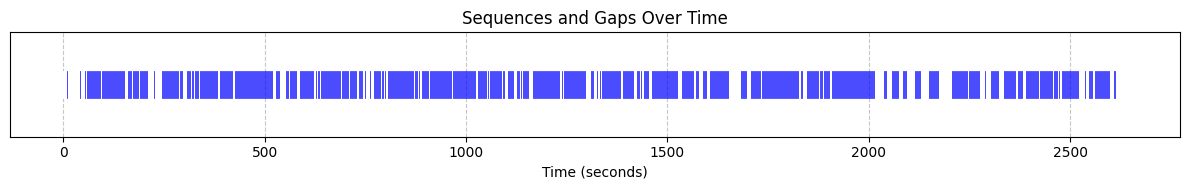

In [810]:
import matplotlib.pyplot as plt

def plot_sequences_and_gaps(sequences_df, total_time):
    """
    Plot sequences and gaps over time.

    Args:
        sequences_df (pd.DataFrame): DataFrame containing sequences with columns:
                                     ['start_time', 'total_time'].
        total_time (float): The total time from start (0) to the end of the last frame.
    """
    # Sort sequences by start time
    # sequences_df = sequences_df.sort_values(by="start_time")

    # Initialize the figure
    plt.figure(figsize=(12, 2))

    # Plot each sequence as a horizontal bar
    for _, row in sequences_df.iterrows():
        start = row["start_time"]
        end = start + row["total_time"]
        plt.plot([start, end], [1, 1], color="blue", linewidth=20, solid_capstyle="butt", alpha=0.7)

    # Highlight gaps between sequences
    prev_end = 0
    for _, row in sequences_df.iterrows():
        start = row["start_time"]
        if start > prev_end:  # Gap exists
            plt.plot([prev_end, start], [1, 1], color="white", linewidth=20, solid_capstyle="butt")
        prev_end = max(prev_end, start + row["total_time"])

    # Check for a gap at the end
    if prev_end < total_time:
        plt.plot([prev_end, total_time], [1, 1], color="white", linewidth=20, solid_capstyle="butt")

    # Add labels and title
    plt.xlabel("Time (seconds)")
    plt.yticks([])
    plt.title("Sequences and Gaps Over Time")
    plt.grid(axis="x", linestyle="--", alpha=0.7)

    # Show the plot
    plt.tight_layout()
    plt.show()

# Example usage
total_time = len(data) / 40 # Total time from the data
plot_sequences_and_gaps(full_sequences_df, total_time)

In [801]:
total_time_in_sequences = full_sequences_df['total_time'].sum()
print(f"Total time in sequences: {total_time_in_sequences:.2f} sec")
print(f"Percent of time in sequences: {total_time_in_sequences / total_time * 100:.2f}%")

Total time in sequences: 1943.15 sec
Percent of time in sequences: 73.59%


In [808]:
total_time

44.01

In [811]:
# Calculate the average reaction time for each level
average_reaction_times = turns_df.groupby("level")["reaction_time_sec"].mean()
std_reaction_times = turns_df.groupby("level")["reaction_time_sec"].std()
min_reaction_times = turns_df.groupby("level")["reaction_time_sec"].min()
max_reaction_times = turns_df.groupby("level")["reaction_time_sec"].max()

# print("Mean Reaction Time", average_reaction_times)
# print("STD Reaction Time", std_reaction_times)

# Plot the average and std reaction times for each node
plt.figure(figsize=(12, 6))
# Convert the index to a list of strings to avoid issues with non-scalar values
x_values = [str(index) for index in average_reaction_times.index]
# Sort nodes by reaction time
# average_reaction_times = average_reaction_times.sort_values()

# Plot the error bar with properly formatted x and y values

plt.errorbar(x_values, average_reaction_times, yerr=std_reaction_times, fmt='o', capsize=5)
plt.title('Average Reaction Time per Level')
plt.xlabel('Level (Distance from Leaves)')
plt.ylabel('Average Reaction Time (s)')
# plt.xticks(rotation=90)
plt.grid()
plt.tight_layout()
plt.show()

KeyError: 'level'

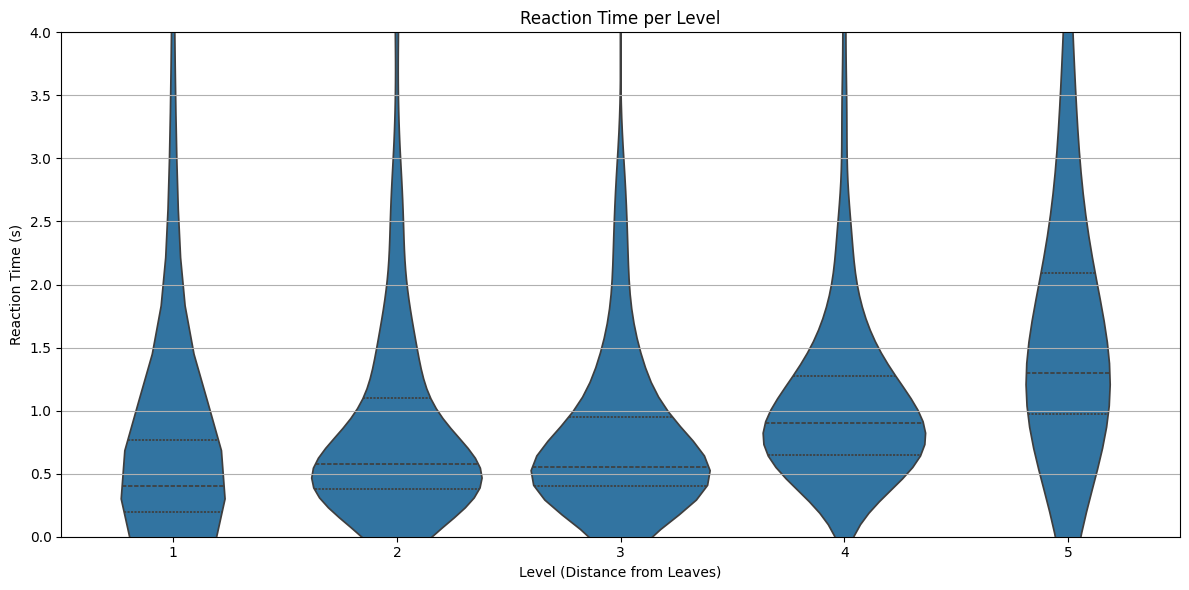

In [536]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.violinplot(x='level', y='reaction_time_sec', data=turns_df, inner='quartile', )
plt.title('Reaction Time per Level')
plt.xlabel('Level (Distance from Leaves)')
plt.ylabel('Reaction Time (s)')
plt.ylim(0, 4)  # Set the y-axis limit to 8 as maximum
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [545]:
# Calculate the average reaction time for each reward, including only level 1
average_reaction_times = turns_df[turns_df['level'] == 1].groupby("to_reward")["reaction_time_sec"].mean()
std_reaction_times = turns_df[turns_df['level'] == 1].groupby("to_reward")["reaction_time_sec"].std()

average_reaction_times_from = turns_df[turns_df['level'] == 1].groupby("from_reward")["reaction_time_sec"].mean()
std_reaction_times_from = turns_df[turns_df['level'] == 1].groupby("from_reward")["reaction_time_sec"].std()

# average_reaction_times = turns_df.groupby("to_reward")["reaction_time_sec"].mean()
# std_reaction_times = turns_df.groupby("to_reward")["reaction_time_sec"].std()

# average_reaction_times_from = turns_df.groupby("from_reward")["reaction_time_sec"].mean()
# std_reaction_times_from = turns_df.groupby("from_reward")["reaction_time_sec"].std()

print("Mean Reaction Time", average_reaction_times)
print("STD Reaction Time", std_reaction_times)
print("Mean Reaction Time", average_reaction_times_from)
print("STD Reaction Time", std_reaction_times_from)

Mean Reaction Time to_reward
False    0.862636
True     0.565190
Name: reaction_time_sec, dtype: float64
STD Reaction Time to_reward
False    2.258733
True     0.829131
Name: reaction_time_sec, dtype: float64
Mean Reaction Time from_reward
False    0.600365
True     1.467188
Name: reaction_time_sec, dtype: float64
STD Reaction Time from_reward
False    0.737515
True     3.996750
Name: reaction_time_sec, dtype: float64


/tmp/ipykernel_7955/548942638.py:21: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('YlOrRd')


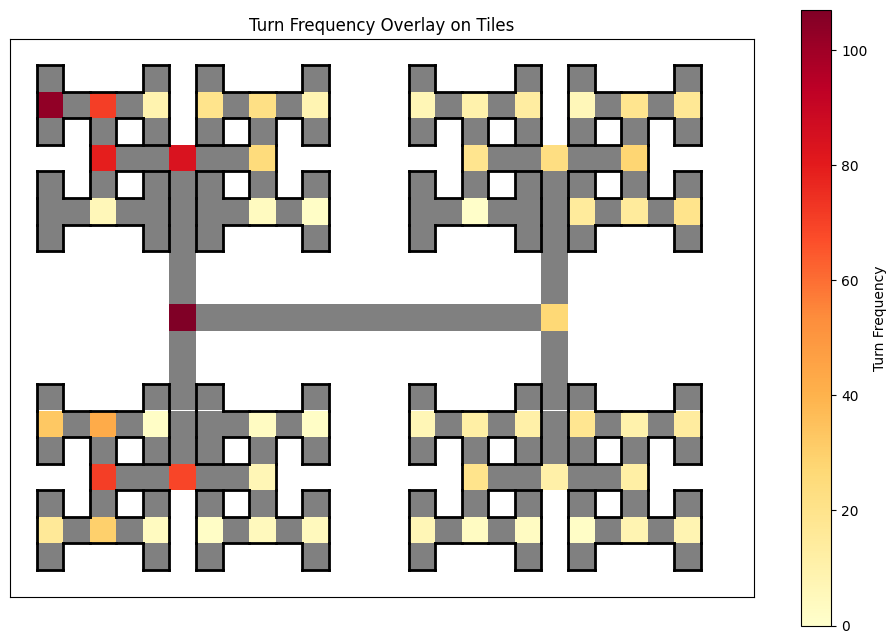

In [546]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

def visualize_turns_on_tiles(tiles_df, turn_tuples, export=False):
    """
    Visualize the grid with turn occurrences overlaid.

    Args:
    - tiles_df (pd.DataFrame): DataFrame containing tile info with 'coordinates', 'is_graph', and 'borders'.
    - turn_tuples (list of tuples): Each tuple is (prev, curr, next, direction).
    - export (bool): Whether to save the plot to disk.
    """
    # Count how many times each turn happened at each curr location
    from collections import Counter
    turn_count = Counter([t[1] for t in turn_tuples])  # t[1] is curr node

    # Normalize counts for color mapping
    max_count = max(turn_count.values()) if turn_count else 1
    norm = mcolors.Normalize(vmin=0, vmax=max_count)
    cmap = cm.get_cmap('YlOrRd')

    fig, ax = plt.subplots()
    for idx, row in tiles_df.iterrows():
        x, y = row['coordinates']
        base_color = 'gray' if row['is_graph'] else 'white'
        curr_coord = (x, y)

        # Overlay color based on number of turns at this tile
        if curr_coord in turn_count:
            color = cmap(norm(turn_count[curr_coord]))
        else:
            color = base_color

        rect = plt.Rectangle((x, y), 1, 1, facecolor=color, edgecolor='black', linewidth=0)
        ax.add_patch(rect)

        # Draw red borders for all tiles
        if row['borders'][0]:
            ax.plot([x, x + 1], [y, y], color='black', linewidth=2)
        if row['borders'][1]:
            ax.plot([x + 1, x + 1], [y, y + 1], color='black', linewidth=2)
        if row['borders'][2]:
            ax.plot([x, x + 1], [y + 1, y + 1], color='black', linewidth=2)
        if row['borders'][3]:
            ax.plot([x, x], [y, y + 1], color='black', linewidth=2)

    ax.set_xlim(tiles_df['coordinates'].apply(lambda x: x[0]).min() - 1,
                tiles_df['coordinates'].apply(lambda x: x[0]).max() + 2)
    ax.set_ylim(tiles_df['coordinates'].apply(lambda x: x[1]).min() - 1,
                tiles_df['coordinates'].apply(lambda x: x[1]).max() + 2)
    ax.set_aspect('equal')
    fig.set_size_inches(12, 8)
    plt.gca().invert_yaxis()
    plt.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label='Turn Frequency')
    # Set the title and labels
    ax.set_title('Turn Frequency Overlay on Tiles')
    # Remove x and y ticks
    ax.set_xticks([])
    ax.set_yticks([])

    if export:
        plt.savefig('/var/home/almogmeir/Documents/M.Sc/Project/Graphs/turn_overlay_grid.png')
    plt.show()

# Example usage:
visualize_turns_on_tiles(test_tiles, turn_tuples, export=True)

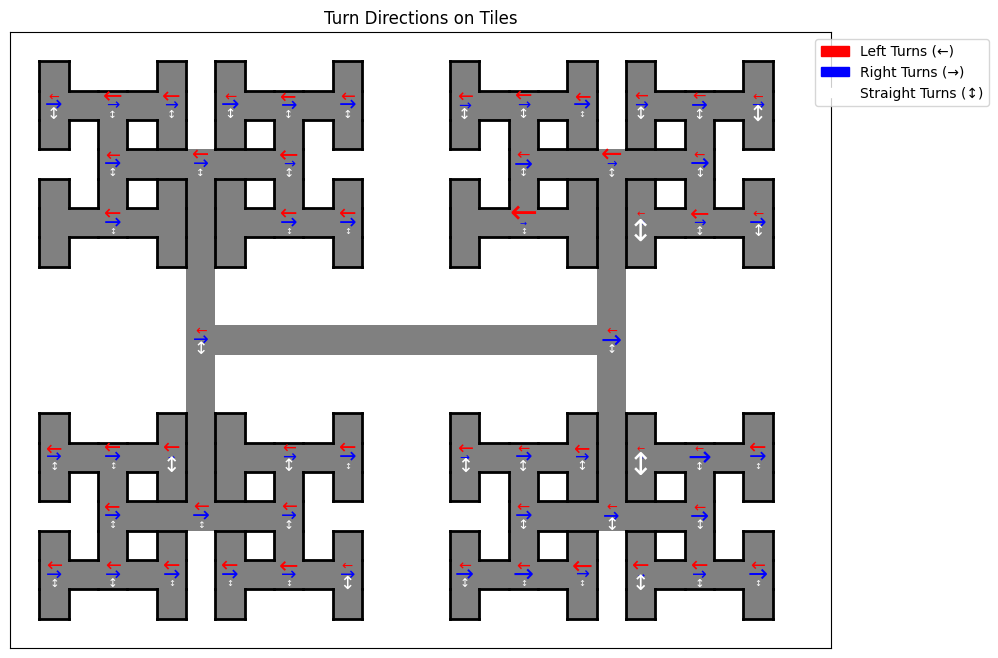

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle
from collections import Counter

def visualize_turns_on_tiles(tiles_df, turn_tuples, export=False):
    """
    Visualize the grid with turn occurrences overlaid using directional markers for left/right/straight.
    Each node's arrows are scaled by its own internal distribution.

    Args:
    - tiles_df (pd.DataFrame): DataFrame containing tile info with 'coordinates', 'is_graph', and 'borders'.
    - turn_tuples (list of tuples): Each tuple is (prev, curr, next, direction).
    - export (bool): Whether to save the plot to disk.
    """
    from matplotlib.patches import Patch

    # Count all turn directions at each tile
    direction_colors = {'left': 'blue', 'right': 'red', 'straight': 'green'}
    turn_by_coord = {'left': Counter(), 'right': Counter(), 'straight': Counter()}

    for prev, curr, next_, direction, _, _ in turn_tuples:
        if direction in direction_colors:
            turn_by_coord[direction][curr] += 1

    # Collect all coordinates with any turn
    all_coords = set(turn_by_coord['left'].keys()) | set(turn_by_coord['right'].keys()) | set(turn_by_coord['straight'].keys())

    fig, ax = plt.subplots()
    for idx, row in tiles_df.iterrows():
        x, y = row['coordinates']
        curr_coord = (x, y)

        # Base tile coloring
        base_color = 'gray' if row['is_graph'] else 'white'
        ax.add_patch(Rectangle((x, y), 1, 1, facecolor=base_color, edgecolor='black', linewidth=0))

        # Draw direction markers normalized per-tile
        if curr_coord in all_coords:
            left = turn_by_coord['left'][curr_coord]
            right = turn_by_coord['right'][curr_coord]
            straight = turn_by_coord['straight'][curr_coord]
            total = left + right + straight

            if total > 0:
                # Normalize by total for relative comparison
                left_ratio = left / total
                right_ratio = right / total
                straight_ratio = straight / total

                ax.text(x + 0.5, y + 0.2, '←', color='red', ha='center', va='center', fontsize=6 + 18 * left_ratio)
                ax.text(x + 0.5, y + 0.5, '→', color='blue', ha='center', va='center', fontsize=6 + 18 * right_ratio)
                ax.text(x + 0.5, y + 0.8, '↕', color='white', ha='center', va='center', fontsize=6 + 18 * straight_ratio)

        # Draw black borders
        if row['borders'][0]:
            ax.plot([x, x + 1], [y, y], color='black', linewidth=2)
        if row['borders'][1]:
            ax.plot([x + 1, x + 1], [y, y + 1], color='black', linewidth=2)
        if row['borders'][2]:
            ax.plot([x, x + 1], [y + 1, y + 1], color='black', linewidth=2)
        if row['borders'][3]:
            ax.plot([x, x], [y, y + 1], color='black', linewidth=2)

    ax.set_xlim(tiles_df['coordinates'].apply(lambda x: x[0]).min() - 1,
                tiles_df['coordinates'].apply(lambda x: x[0]).max() + 2)
    ax.set_ylim(tiles_df['coordinates'].apply(lambda x: x[1]).min() - 1,
                tiles_df['coordinates'].apply(lambda x: x[1]).max() + 2)
    ax.set_aspect('equal')
    fig.set_size_inches(12, 8)
    plt.gca().invert_yaxis()

    # Add legend
    legend_elements = [
        Patch(color='red', label='Left Turns (←)'),
        Patch(color='blue', label='Right Turns (→)'),
        Patch(color='white', label='Straight Turns (↕)')
    ]
    ax.legend(handles=legend_elements, loc='upper right')
    # make sure it is outside of the grid
    ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.2, 1))
    # Remove ticks
    ax.set_xticks([])
    ax.set_yticks([])
    # Set title
    ax.set_title('Turn Directions on Tiles')

    if export:
        plt.savefig('/var/home/almogmeir/Documents/M.Sc/Project/Graphs/turn_directions_grid.png')
    plt.show()

# Example usage:
visualize_turns_on_tiles(test_tiles, turn_tuples, export=False)


In [548]:
def extract_turns_with_reaction_time(data, tiles_dict, G, full_turns, debug=False):
    """
    Extracts (prev, curr, next, direction, reaction_time_sec) from subject path.
    Reaction time is time spent in 'curr' before moving to 'next'.
    """
    from collections import defaultdict

    # Make sure coordinates are integers
    def safe_coord(tid):
        return tuple(map(int, tiles_dict.get(tid, (999, 999))))

    # Create lookup from full_turns
    turn_lookup = {
        (tuple(row.prev), tuple(row.curr), tuple(row.next)): row.direction
        for row in full_turns.itertuples(index=False)
    }
    valid_turns = set(turn_lookup.keys())

    buffer = []
    last_coord = None
    curr_start_idx = None
    results = []

    for idx, tile_id in enumerate(data['tile_id']):
        coord = safe_coord(tile_id)
        if coord not in G:
            continue
        if coord == last_coord:
            continue

        last_coord = coord
        buffer.append((idx, coord))
        if len(buffer) > 3:
            buffer.pop(0)

        if len(buffer) == 3:
            idx_prev, prev = buffer[0]
            idx_curr, curr = buffer[1]
            idx_next, next_ = buffer[2]
            key = (prev, curr, next_)
            if debug:
                print(f"Checking: {key}")
            if key in valid_turns:
                direction = turn_lookup[key]
                duration = idx_next - idx_curr
                reaction_time_sec = duration / 40.0
                results.append((prev, curr, next_, direction, reaction_time_sec))

    if debug:
        print(f"Found {len(results)} valid turns with RTs.")

    return results

# Example usage:
turns_with_reaction_time = extract_turns_with_reaction_time(data, tiles_dict, G, full_turns_df, debug=True)
turns_with_reaction_time

Found 0 valid turns with RTs.


[]

In [258]:
tiles_dict.get(tuple(test_tiles.iloc[1]['coordinates']))

26

In [ ]:
tile_id_counts = data['tile_id'].value_counts()
print(tile_id_counts)

tile_id
0.0      14468
6.0       6990
26.0      3607
27.0      3134
239.0     1494
         ...  
403.0        1
89.0         1
88.0         1
417.0        1
371.0        1
Name: count, Length: 297, dtype: int64


In [80]:
# Get the key of a value in tiles_dict
key_list = list(tiles_dict.keys())
val_list = list(tiles_dict.values())
# position = val_list.index(data['tile_id'][0])
# position = val_list.index(24)
# key_list[position]
data['graph_node'] = data['tile_id'].apply(lambda x: key_list[val_list.index(x)] if x in val_list else None)
# data_before['graph_node'] = data_before['tile_id'].apply(lambda x: key_list[val_list.index(x)] if x in val_list else None)
# data['tree_position'] = data['tile_id'].apply(lambda x: nodes_dict[x] if x in nodes_dict else None)

/tmp/ipykernel_7955/1991796407.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['graph_node'] = data['tile_id'].apply(lambda x: key_list[val_list.index(x)] if x in val_list else None)


In [143]:
# Get rows where tile_id equals 241
tile_1_rows = data[data['tile_id'] == -1]

# Calculate the average likelihood for tile_id 241
avg_likelihood_1 = tile_1_rows['likelihood'].mean()

# Get rows where tile_id does not equal 241
other_rows = data[data['tile_id'] != 241]

# Calculate the average likelihood for all other rows
avg_likelihood_others = other_rows['likelihood'].mean()

print(f"Average likelihood for tile_id -1: {avg_likelihood_1}")
print(f"Average likelihood for all other rows: {avg_likelihood_others}")

Average likelihood for tile_id -1: 0.7927494824755724
Average likelihood for all other rows: 0.8049322299474102


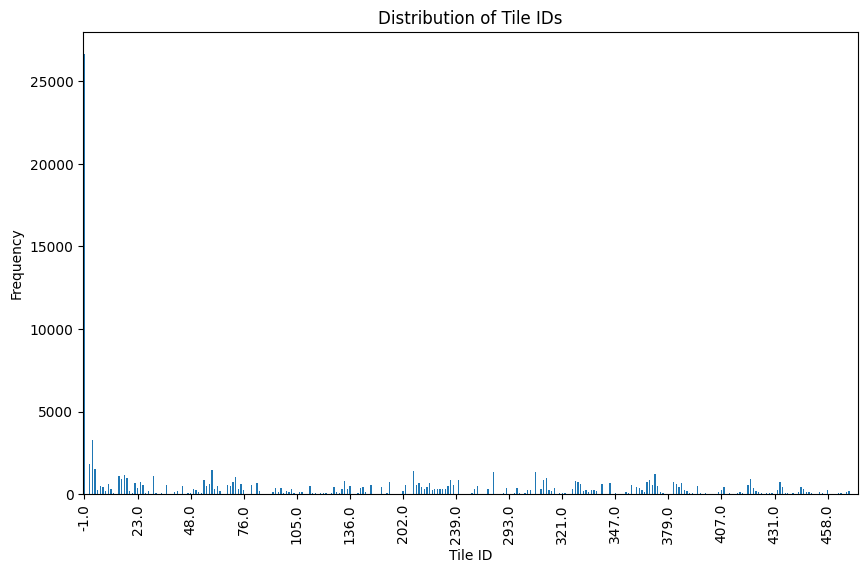

In [82]:
import matplotlib.pyplot as plt

# Plot the distribution of tile_ids
plt.figure(figsize=(10, 6))
ax = data['tile_id'].value_counts().sort_index().plot(kind='bar')
plt.xlabel('Tile ID')
plt.ylabel('Frequency')
plt.title('Distribution of Tile IDs')

# Set x-ticks to show only every other 20 tiles
xticks = ax.get_xticks()
ax.set_xticks(xticks[::20])
ax.set_xticklabels(data['tile_id'].value_counts().sort_index().index[::20])

plt.show()

In [85]:
# Sum the amount of every tile_id and show the top 20 most frequent
top_20_tile_ids = data['tile_id'].value_counts().head(20)
print(top_20_tile_ids)

tile_id
-1.0      26653
 2.0       3252
 1.0       1845
 3.0       1492
 58.0      1456
 214.0     1380
 287.0     1338
 311.0     1318
 370.0     1207
 18.0      1136
 16.0      1099
 29.0      1074
 73.0      1015
 315.0      992
 19.0       952
 418.0      914
 17.0       904
 368.0      877
 314.0      874
 55.0       855
Name: count, dtype: int64


In [ ]:
def fix_none_tree_positions(data):
    """
    Fix rows with 'None' tree_position in the data by checking the majority tile_id
    in the previous and next 10 rows around the batch of rows with the same 'None' tree_position.

    Args:
        data (pd.DataFrame): The DataFrame containing the data.

    Returns:
        pd.DataFrame: The updated DataFrame with fixed tree_position and tile_id.
    """
    # Get indices of rows with 'None' tree_position
    none_indices = data[data['tree_position'].isnull()].index

    # Initialize a set to track processed indices
    processed_indices = set()

    for idx in none_indices:
        if idx in processed_indices:
            continue

        # Find the batch of consecutive rows with the same tile_id and 'None' tree_position
        tile_id = data.loc[idx, 'tile_id']
        batch_indices = []
        current_idx = idx

        while current_idx in none_indices and data.loc[current_idx, 'tile_id'] == tile_id:
            batch_indices.append(current_idx)
            current_idx += 1

        # Mark these indices as processed
        processed_indices.update(batch_indices)

        # Check if the batch is larger than 20 rows
        if len(batch_indices) > 20:
            print(f"Batch larger than 20 rows found at indices: {batch_indices}")

        # Get the range of rows to check (previous 10 and next 10 rows)
        start_idx = max(batch_indices[0] - 10, 0)
        end_idx = min(batch_indices[-1] + 10, len(data) - 1)

        # Get the surrounding rows
        surrounding_rows = data.loc[start_idx:end_idx]

        # Exclude rows with 'None' tree_position from the surrounding rows
        surrounding_rows = surrounding_rows[surrounding_rows['tree_position'].notnull()]

        # Find the majority tile_id and tree_position in the surrounding rows
        if not surrounding_rows.empty:
            majority_tile_id = surrounding_rows['tile_id'].mode()[0]
            majority_tree_position = surrounding_rows['tree_position'].mode()[0]

            # Update the batch rows with the majority tile_id and tree_position
            for batch_idx in batch_indices:
                data.at[batch_idx, 'tile_id'] = majority_tile_id
                data.at[batch_idx, 'tree_position'] = majority_tree_position
            # data.loc[batch_indices, 'tile_id'] = [majority_tile_id] * len(batch_indices)
            # data.loc[batch_indices, 'tree_position'] = [majority_tree_position] * len(batch_indices)

    return data

# Apply the function to the data DataFrame
data = fix_none_tree_positions(data)

IndexError: list index out of range

In [248]:
data.iloc[0]['tile_id']

np.int64(27)

In [31]:
!pip install seaborn

Defaulting to user installation because normal site-packages is not writeable


In [249]:
import seaborn as sns

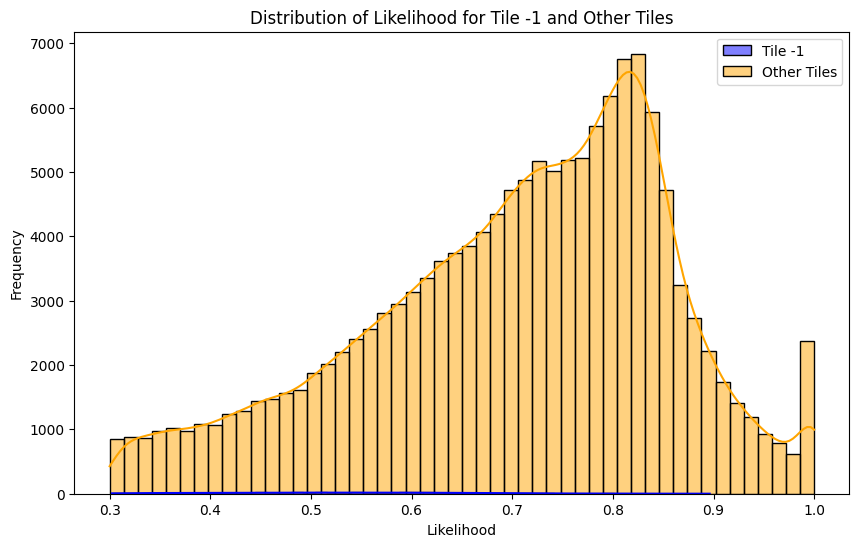

In [250]:
# Separate the likelihood of tile 241 and other tiles
tile_1_likelihood = tile_1_rows['likelihood']
other_likelihood = other_rows['likelihood']

# Plot the histogram
plt.figure(figsize=(10, 6))
sns.histplot(tile_1_likelihood, bins=50, kde=True, color='blue', label='Tile -1')
sns.histplot(other_likelihood, bins=50, kde=True, color='orange', label='Other Tiles')
plt.xlabel('Likelihood')
plt.ylabel('Frequency')
plt.title('Distribution of Likelihood for Tile -1 and Other Tiles')
plt.legend()
plt.show()

In [251]:
tile_1_rows

coords,x,y,likelihood,tile_box,tile_id,tree_position,graph_node
47712,974.580322,82.104881,0.659954,None,-1,None,None
47713,975.122131,80.236832,0.724234,None,-1,None,None
47714,975.225281,81.303329,0.766551,None,-1,None,None
47715,974.560852,81.558304,0.631578,None,-1,None,None
47716,974.794861,81.358131,0.618975,None,-1,None,None
...,...,...,...,...,...,...,...
134030,1010.427490,77.014442,0.485952,None,-1,None,None
134031,1012.220764,76.694214,0.488659,None,-1,None,None
134032,1011.063599,76.100945,0.462331,None,-1,None,None
134033,1009.753662,75.195251,0.321394,None,-1,None,None


In [252]:
data

coords,x,y,likelihood,tile_box,tile_id,tree_position,graph_node
529,115.747284,214.473267,0.369943,"[182, 179, 31, 31]",27,"(48, (48, 516))","(2, 5)"
530,115.991318,218.273148,0.476091,"[182, 179, 31, 31]",27,"(48, (48, 516))","(2, 5)"
531,119.645279,220.516998,0.401826,"[182, 179, 31, 31]",27,"(48, (48, 516))","(2, 5)"
532,122.177162,222.227798,0.509229,"[182, 179, 31, 31]",27,"(48, (48, 516))","(2, 5)"
533,126.510262,222.003983,0.310757,"[182, 179, 31, 31]",27,"(48, (48, 516))","(2, 5)"
...,...,...,...,...,...,...,...
143534,351.806629,601.829053,0.489967,"[342, 403, 31, 31]",221,0,"(7, 12)"
143535,358.459320,539.885132,0.580908,"[342, 371, 31, 31]",194,"(0, 11)","(7, 11)"
143536,361.499756,528.984314,0.570087,"[342, 371, 31, 31]",194,"(0, 11)","(7, 11)"
143537,365.625793,526.033142,0.716686,"[342, 371, 31, 31]",194,"(0, 11)","(7, 11)"


In [253]:
# Count rows where tree_position is an int
count_single_number_tree_position = data['tree_position'].apply(lambda x: isinstance(x, int)).sum()
print(count_single_number_tree_position)

# Count rows where tree_position is a tuple
count_tuple_tree_position = data['tree_position'].apply(lambda x: isinstance(x, tuple)).sum()
print(count_tuple_tree_position)

# Filter rows where 'tree_position' is neither a tuple nor an int
non_tuple_or_int_rows = data[~data['tree_position'].apply(lambda x: isinstance(x, (tuple, int)))]

# Display the filtered rows
print(non_tuple_or_int_rows)

# Count rows where tree_position is an frozen_set
count_frozenset_tree_position = data['tree_position'].apply(lambda x: isinstance(x, frozenset)).sum()
print(count_frozenset_tree_position)

count_none_tree_position = data['tree_position'].isnull().sum()
print(count_none_tree_position)

# int + frozenset are all the rows that are nodes in the graph
# tuple rows are edges in the graph

# Get all the rows that are nodes to new df
nodes_df = data[data['tree_position'].apply(lambda x: isinstance(x, (int, frozenset)))]


18771
61483
coords           x           y  likelihood            tile_box  tile_id  \
529     115.747284  214.473267    0.369943  [182, 179, 31, 31]       27   
530     115.991318  218.273148    0.476091  [182, 179, 31, 31]       27   
531     119.645279  220.516998    0.401826  [182, 179, 31, 31]       27   
532     122.177162  222.227798    0.509229  [182, 179, 31, 31]       27   
533     126.510262  222.003983    0.310757  [182, 179, 31, 31]       27   
...            ...         ...         ...                 ...      ...   
143508  381.697968  758.830017    0.518405  [374, 499, 31, 31]      303   
143509  380.839600  759.143982    0.509210  [374, 499, 31, 31]      303   
143510  380.377228  758.822021    0.484850  [374, 499, 31, 31]      303   
143511  376.740265  755.869629    0.390080  [374, 499, 31, 31]      303   
143512  375.234192  757.854980    0.456204  [374, 499, 31, 31]      303   

coords    tree_position graph_node  
529     (48, (48, 516))     (2, 5)  
530     (48, 

In [254]:
nodes_df

coords,x,y,likelihood,tile_box,tile_id,tree_position,graph_node
529,115.747284,214.473267,0.369943,"[182, 179, 31, 31]",27,"(48, (48, 516))","(2, 5)"
530,115.991318,218.273148,0.476091,"[182, 179, 31, 31]",27,"(48, (48, 516))","(2, 5)"
531,119.645279,220.516998,0.401826,"[182, 179, 31, 31]",27,"(48, (48, 516))","(2, 5)"
532,122.177162,222.227798,0.509229,"[182, 179, 31, 31]",27,"(48, (48, 516))","(2, 5)"
533,126.510262,222.003983,0.310757,"[182, 179, 31, 31]",27,"(48, (48, 516))","(2, 5)"
...,...,...,...,...,...,...,...
143510,380.377228,758.822021,0.484850,"[374, 499, 31, 31]",303,"(59, (44, 59))","(8, 15)"
143511,376.740265,755.869629,0.390080,"[374, 499, 31, 31]",303,"(59, (44, 59))","(8, 15)"
143512,375.234192,757.854980,0.456204,"[374, 499, 31, 31]",303,"(59, (44, 59))","(8, 15)"
143529,352.501465,592.729858,0.357139,"[342, 403, 31, 31]",221,0,"(7, 12)"


In [255]:
data['tile_id_diff'] = data['tile_id'].diff()
# data_before['tile_id_diff'] = data_before['tile_id'].diff()
filtered_data_not_241 = data[(data['tile_id_diff'] > 28) & (data['tile_id'] != 241)]
filtered_data_not_241

/tmp/ipykernel_13771/1788562994.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['tile_id_diff'] = data['tile_id'].diff()


coords,x,y,likelihood,tile_box,tile_id,tree_position,graph_node,tile_id_diff
875,261.935425,292.143799,0.390138,"[278, 211, 31, 31]",110,"(22, 35)","(5, 6)",54.0
918,361.401489,295.143219,0.431236,"[374, 243, 31, 31]",87,"(11, 23)","(8, 7)",29.0
1004,481.150513,351.870941,0.908424,"[470, 275, 31, 31]",145,"((415, 530), 415)","(11, 8)",29.0
1925,169.284576,669.072754,0.348450,"[214, 435, 31, 31]",272,30,"(3, 13)",29.0
3928,298.226379,772.410583,0.835198,"[310, 499, 31, 31]",301,"((41, 53), 53)","(6, 15)",29.0
...,...,...,...,...,...,...,...,...
137978,295.941895,771.287415,0.833533,"[310, 499, 31, 31]",301,"((41, 53), 53)","(6, 15)",29.0
138061,631.916321,524.074280,0.850331,"[566, 403, 31, 31]",228,"(0, 12)","(14, 12)",60.0
138065,620.602356,523.105896,0.818587,"[566, 403, 31, 31]",228,"(0, 12)","(14, 12)",60.0
138067,619.880920,523.128540,0.791752,"[566, 403, 31, 31]",228,"(0, 12)","(14, 12)",60.0


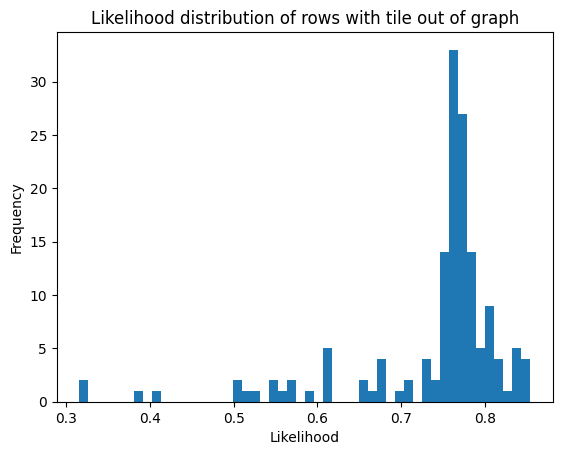

In [256]:
rows_with_none_tree_position = data[data['tree_position'].isnull() & (data['tile_id'] != 241) & data['likelihood'].notna()]
# rows_with_none_tree_position_before = data_before[data_before['tree_position'].isnull() & (data_before['tile_id'] != 241) & data_before['likelihood'].notna()]

# Plot the likelihood ditribution of the rows with none tree position
plt.hist(rows_with_none_tree_position['likelihood'], bins=50)
plt.xlabel('Likelihood')
plt.ylabel('Frequency')
plt.title('Likelihood distribution of rows with tile out of graph')
plt.show()

In [257]:
rows_with_none_tree_position

coords,x,y,likelihood,tile_box,tile_id,tree_position,graph_node,tile_id_diff
143030,289.765381,767.367676,0.671504,"[278, 499, 31, 31]",300,None,"(5, 15)",-1.0
143031,284.036163,767.474915,0.713371,"[278, 499, 31, 31]",300,None,"(5, 15)",0.0
143032,280.322510,765.770874,0.728072,"[278, 499, 31, 31]",300,None,"(5, 15)",0.0
143033,275.010956,768.776917,0.707583,"[278, 499, 31, 31]",300,None,"(5, 15)",0.0
143034,268.311646,772.939575,0.752677,"[278, 499, 31, 31]",300,None,"(5, 15)",0.0
...,...,...,...,...,...,...,...,...
143412,170.151733,680.602478,0.746864,"[214, 435, 31, 31]",244,None,"(3, 13)",1.0
143413,173.475021,682.449829,0.667683,"[214, 435, 31, 31]",244,None,"(3, 13)",0.0
143414,175.479172,681.214417,0.609948,"[214, 435, 31, 31]",244,None,"(3, 13)",0.0
143464,212.070602,678.597961,0.318033,"[246, 435, 31, 31]",245,None,"(4, 13)",-27.0


In [258]:
# Get number of rows with tile_id 241 in data and in data_before
rows_with_tile_241 = data[data['tile_id'] == 241]
rows_with_tile_241_before = data_before[data_before['tile_id'] == 241]

print('Number of rows with tile_id 241 in data:', len(rows_with_tile_241))
print('Number of rows with tile_id 241 in data_before:', len(rows_with_tile_241_before))

NameError: name 'data_before' is not defined

In [259]:
# Function to update tile_id based on previous and next rows' tile_ids
def update_tile_id(data):
    for idx in data[(data['tree_position'].isnull()) & (data['likelihood'].notna())].index:
        prev_tile_id = data.loc[idx - 1, 'tile_id'] if idx > 0 else None
        next_tile_id = data.loc[idx + 1, 'tile_id'] if idx < len(data) - 1 else None
        # prev_tree_pos = data.loc[idx - 1, 'tree_position'] if idx > 0 else None
        # next_tree_pos = data.loc[idx + 1, 'tree_position'] if idx < len(data) - 1 else None
        
        if prev_tile_id == next_tile_id:
            data.at[idx, 'tile_id'] = prev_tile_id
        elif prev_tile_id is not None and next_tile_id is not None:
            data.at[idx, 'tile_id'] = prev_tile_id if abs(data.loc[idx, 'tile_id'] - prev_tile_id) < abs(data.loc[idx, 'tile_id'] - next_tile_id) else next_tile_id
            new_tile_id = data.at[idx, 'tile_id']
        elif prev_tile_id is not None:
            data.at[idx, 'tile_id'] = prev_tile_id
        # elif next_tile_id is not None:
        else:
            data.at[idx, 'tile_id'] = next_tile_id
        # After updating the tile_id, update the tree_position as well
        if data.at[idx, 'tile_id'] in final_dict:
            data.at[idx, 'tree_position'] = final_dict[data.at[idx, 'tile_id']]

# Update the tile_id for the specified rows
update_tile_id(data)

# Verify the updates
# updated = data[(data['tree_position'].isnull()) & (data['likelihood'].notna())]
# updated[200:220]

In [260]:
data[200:220]

coords,x,y,likelihood,tile_box,tile_id,tree_position,graph_node,tile_id_diff
729,294.118134,177.690521,0.755398,"[310, 147, 31, 31]",4,"((49, 518), 518)","(6, 4)",0.0
730,294.287354,176.869217,0.748999,"[310, 147, 31, 31]",4,"((49, 518), 518)","(6, 4)",0.0
731,294.297394,177.478317,0.749488,"[310, 147, 31, 31]",4,"((49, 518), 518)","(6, 4)",0.0
732,293.769989,175.440475,0.726156,"[310, 147, 31, 31]",4,"((49, 518), 518)","(6, 4)",0.0
733,294.446045,176.584671,0.751153,"[310, 147, 31, 31]",4,"((49, 518), 518)","(6, 4)",0.0
734,294.743622,176.539719,0.757219,"[310, 147, 31, 31]",4,"((49, 518), 518)","(6, 4)",0.0
735,294.887939,175.302307,0.729709,"[310, 147, 31, 31]",4,"((49, 518), 518)","(6, 4)",0.0
736,294.961060,176.630875,0.753304,"[310, 147, 31, 31]",4,"((49, 518), 518)","(6, 4)",0.0
737,295.203278,175.150375,0.735559,"[310, 147, 31, 31]",4,"((49, 518), 518)","(6, 4)",0.0
738,295.127563,175.381683,0.739809,"[310, 147, 31, 31]",4,"((49, 518), 518)","(6, 4)",0.0


In [263]:
# Count the number of rows where likelihood is Nan
nan_likelihood_count = data['likelihood'].isnull().sum()
# nan_likelihood_count_before = data_before['likelihood'].isnull().sum()

# print(f'Number of rows where likelihood is Nan before update: {nan_likelihood_count_before}')
print(f'Number of rows where likelihood is Nan after update: {nan_likelihood_count}')

Number of rows where likelihood is Nan after update: 209


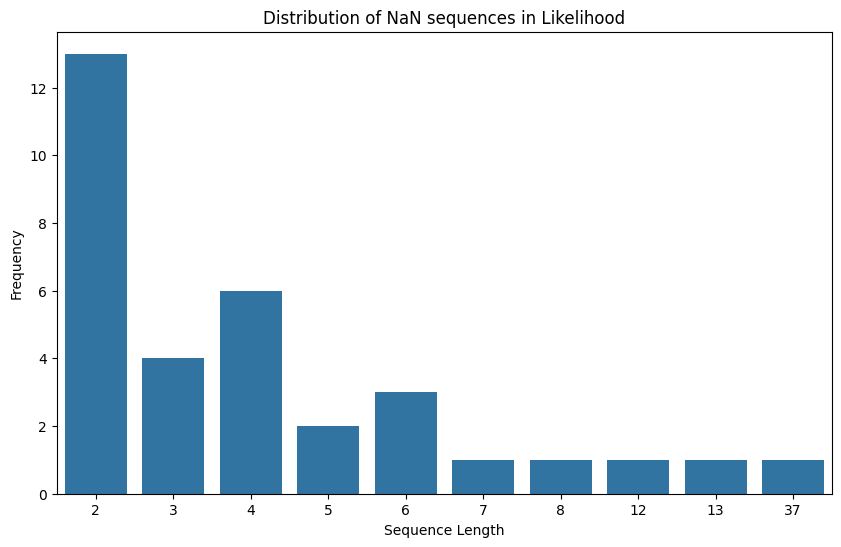

In [264]:
# Initialize variables
nan_counters = {}
current_count = 0
streak_start = None
streaks = []

# Iterate through the rows
for i in range(len(data)):
    if pd.isna(data['likelihood'].iloc[i]):
        if current_count == 0:
            streak_start = i
        current_count += 1
    else:
        if current_count > 1:  # Exclude cases of 1 NaN only
            if current_count in nan_counters:
                nan_counters[current_count] += 1
            else:
                nan_counters[current_count] = 1
            streaks.append((streak_start, current_count))
        current_count = 0

# Handle the case where the last rows are NaNs
if current_count > 1:
    if current_count in nan_counters:
        nan_counters[current_count] += 1
    else:
        nan_counters[current_count] = 1
    streaks.append((streak_start, current_count))

# Convert the dictionary to a DataFrame for easier plotting
nan_streaks_df = pd.DataFrame(nan_counters.items(), columns=['Streak Length', 'Frequency'])

# Add streak start locations to the DataFrame
streak_starts_df = pd.DataFrame(streaks, columns=['Start Index', 'Streak Length'])
nan_streaks_df = nan_streaks_df.merge(streak_starts_df, on='Streak Length', how='left')

# Plot the distribution of NaN streaks
plt.figure(figsize=(10, 6))
sns.barplot(x='Streak Length', y='Frequency', data=nan_streaks_df)
plt.xlabel('Sequence Length')
plt.ylabel('Frequency')
plt.title('Distribution of NaN sequences in Likelihood')
plt.show()

/tmp/ipykernel_13771/2607252938.py:61: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


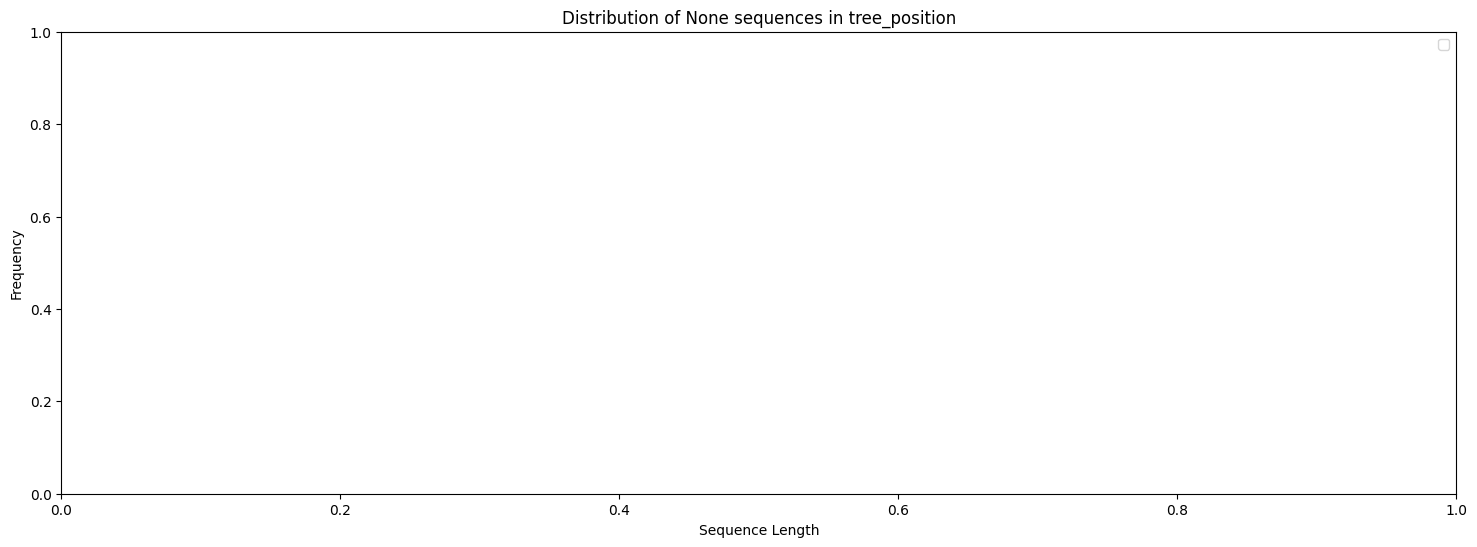

In [266]:
def find_none_sequences(data, column):
    """
    Find sequences of None values in the specified column of the DataFrame.

    Args:
    - data (pd.DataFrame): The DataFrame to search.
    - column (str): The column name to search for None values.

    Returns:
    - dict: A dictionary with sequence lengths as keys and their frequencies as values.
    - list: A list of tuples with the start index and length of each sequence.
    """
    none_counters = {}
    current_count = 0
    streak_start = None
    streaks = []

    # Iterate through the rows
    for i in range(len(data)):
        if data[column].iloc[i] is None:
            if current_count == 0:
                streak_start = i
            current_count += 1
        else:
            if current_count > 1:  # Exclude cases of 1 None only
                if current_count in none_counters:
                    none_counters[current_count] += 1
                else:
                    none_counters[current_count] = 1
                streaks.append((streak_start, current_count))
            current_count = 0

    # Handle the case where the last rows are None
    if current_count > 1:
        if current_count in none_counters:
            none_counters[current_count] += 1
        else:
            none_counters[current_count] = 1
        streaks.append((streak_start, current_count))

    return none_counters, streaks

# Find sequences of None values in the 'tree_position' column
none_counters, none_streaks = find_none_sequences(data, 'tree_position')

# Convert the dictionary to a DataFrame for easier plotting
none_streaks_df = pd.DataFrame(none_counters.items(), columns=['Streak Length', 'Frequency'])
# Find sequences of None values in the 'tree_position' column for data_before
# none_counters_before, none_streaks_before = find_none_sequences(data_before, 'tree_position')

# Convert the dictionary to a DataFrame for easier plotting
# none_streaks_df_before = pd.DataFrame(none_counters_before.items(), columns=['Streak Length', 'Frequency'])

# Plot the distribution of None sequences for both data and data_before
plt.figure(figsize=(18, 6))
sns.barplot(x='Streak Length', y='Frequency', data=none_streaks_df, color='blue', label='data')
# sns.barplot(x='Streak Length', y='Frequency', data=none_streaks_df_before, color='orange', label='data_before', alpha=0.6)
plt.xlabel('Sequence Length')
plt.ylabel('Frequency')
plt.title('Distribution of None sequences in tree_position')
plt.legend()
plt.show()

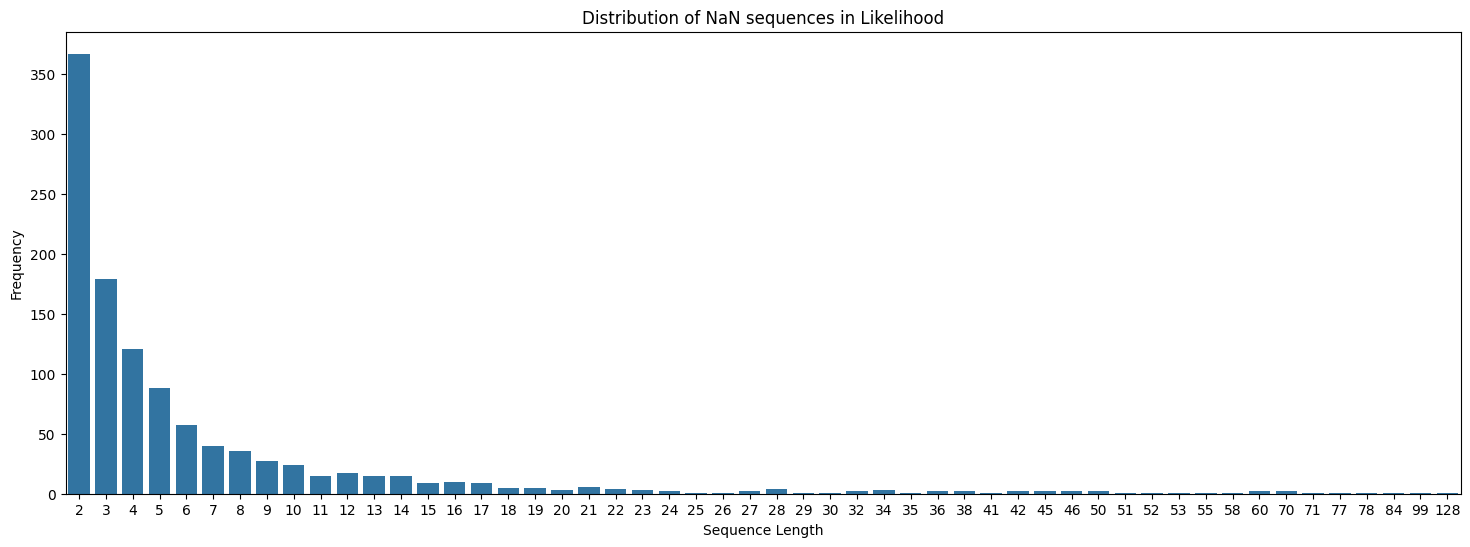

In [165]:
# Initialize variables
nan_counters = {}
current_count = 0
streak_start = None
streaks = []

# Iterate through the rows
for i in range(len(data_before)):
    if pd.isna(data_before['likelihood'].iloc[i]):
        if current_count == 0:
            streak_start = i
        current_count += 1
    else:
        if current_count > 1:  # Exclude cases of 1 NaN only
            if current_count in nan_counters:
                nan_counters[current_count] += 1
            else:
                nan_counters[current_count] = 1
            streaks.append((streak_start, current_count))
        current_count = 0

# Handle the case where the last rows are NaNs
if current_count > 1:
    if current_count in nan_counters:
        nan_counters[current_count] += 1
    else:
        nan_counters[current_count] = 1
    streaks.append((streak_start, current_count))

# Convert the dictionary to a DataFrame for easier plotting
nan_streaks_df = pd.DataFrame(nan_counters.items(), columns=['Streak Length', 'Frequency'])

# Add streak start locations to the DataFrame
streak_starts_df = pd.DataFrame(streaks, columns=['Start Index', 'Streak Length'])
nan_streaks_df = nan_streaks_df.merge(streak_starts_df, on='Streak Length', how='left')

# Plot the distribution of NaN streaks
plt.figure(figsize=(18, 6))
sns.barplot(x='Streak Length', y='Frequency', data=nan_streaks_df)
plt.xlabel('Sequence Length')
plt.ylabel('Frequency')
plt.title('Distribution of NaN sequences in Likelihood')
plt.show()

In [267]:
# Calculate the difference in tile_id between the current row and the next row
data['tile_id_diff'] = data['tile_id'].diff(-1)
# data['tile_id_diff'] = data['tile_id'].diff()

# Define the condition
condition = data['tile_id_diff'].isin([27, -27, 1, -1])

# Get the indices of rows meeting the condition
matching_indices = data.index[condition]

# Build a set of indices: for each matching row, add itself and the previous row if available.
indices_to_keep = []
for i in matching_indices:
    if not isinstance(data.at[i, 'tree_position'], tuple) and data.at[i, 'tree_position'] is not None \
        and i + 1 <= data.index.max() and data.at[i + 1, 'tree_position'] is not None:
        indices_to_keep.append(i + 1)
        indices_to_keep.append(i)

# Create filtered DataFrame using the sorted indices
filtered_df = data.loc[sorted(indices_to_keep)]
filtered_df

/tmp/ipykernel_13771/2965889268.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['tile_id_diff'] = data['tile_id'].diff(-1)


coords,x,y,likelihood,tile_box,tile_id,tree_position,graph_node,tile_id_diff
535,136.442535,228.692368,0.420155,"[182, 179, 31, 31]",27,"(48, (48, 516))","(2, 5)",-1.0
536,163.881620,205.899971,0.547746,"[214, 147, 31, 31]",28,"(34, 48)","(3, 4)",0.0
555,207.757657,213.495341,0.577724,"[246, 179, 31, 31]",29,34,"(4, 5)",1.0
556,182.260289,219.797430,0.684329,"[214, 179, 31, 31]",28,"(34, 48)","(3, 5)",0.0
560,209.186075,210.239003,0.561679,"[246, 179, 31, 31]",29,34,"(4, 5)",1.0
...,...,...,...,...,...,...,...,...
143513,360.519470,743.900391,0.522617,"[342, 499, 31, 31]",302,"(0, 10)","(7, 15)",0.0
143529,352.501465,592.729858,0.357139,"[342, 403, 31, 31]",221,0,"(7, 12)",-27.0
143530,354.549457,633.258321,0.536028,"[342, 435, 31, 31]",248,"(0, 10)","(7, 13)",0.0
143534,351.806629,601.829053,0.489967,"[342, 403, 31, 31]",221,0,"(7, 12)",27.0


In [268]:
filtered_df['tile_id_diff'].unique()

array([ -1.,   0.,   1.,  -2., -27.,  27., -26., -54.,  28., -28.,  55.,
        26., -29.,  29.,  54.,   2., -25.])

In [269]:
# Create a new DataFrame to store the results
reaction_time_df = pd.DataFrame(columns=['index', 'tile_id', 'reaction_time'])

# Iterate through every even row in filtered_df
for idx in filtered_df.index[::2]:  # Step by 2 to get even rows
    tile_id = filtered_df.loc[idx, 'tile_id']
    
    # Get the original index in the data
    original_index = idx
    
    previous_rows_count = data.loc[:original_index - 1, 'tile_id'].eq(tile_id).sum()
    
    # Calculate the reaction time
    reaction_time = previous_rows_count / 40.0
    
    # Append the result to the new DataFrame using pd.concat
    new_row = pd.DataFrame({'index': [original_index], 'tile_id': [tile_id], 'reaction_time': [reaction_time]})
    reaction_time_df = pd.concat([reaction_time_df, new_row], ignore_index=True)

# Display the new DataFrame
print(reaction_time_df)


/tmp/ipykernel_13771/2208775625.py:18: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  reaction_time_df = pd.concat([reaction_time_df, new_row], ignore_index=True)


       index tile_id  reaction_time
0        535      27          0.150
1        555      29          0.000
2        560      29          0.025
3        573      31          0.075
4        575      31          0.100
...      ...     ...            ...
3668  143483     303          7.575
3669  143491     303          7.650
3670  143512     303          8.100
3671  143529     221         25.800
3672  143534     221         25.825

[3673 rows x 3 columns]


In [270]:
reaction_time_df[:20]

,index,tile_id,reaction_time
0,535,27,0.150
1,555,29,0.000
2,560,29,0.025
3,573,31,0.075
4,575,31,0.100
5,588,29,0.125
6,601,29,0.225
7,620,31,0.175
8,661,31,0.450
9,678,4,0.400


In [271]:
# Ensure the 'tile_id' column is numeric before converting to integer
reaction_time_df['tile_id'] = pd.to_numeric(reaction_time_df['tile_id'], errors='coerce').fillna(0).astype(int)

# Filter rows where 'tile_id' equals 4
reaction_time_df[reaction_time_df['tile_id'] == 4][:20]

,index,tile_id,reaction_time
9,678,4,0.400
11,754,4,2.250
154,7461,4,7.700
156,7476,4,8.050
158,7481,4,8.100
166,7670,4,11.625
168,7685,4,11.925
173,7707,4,12.025
193,8146,4,13.000
228,8962,4,13.100


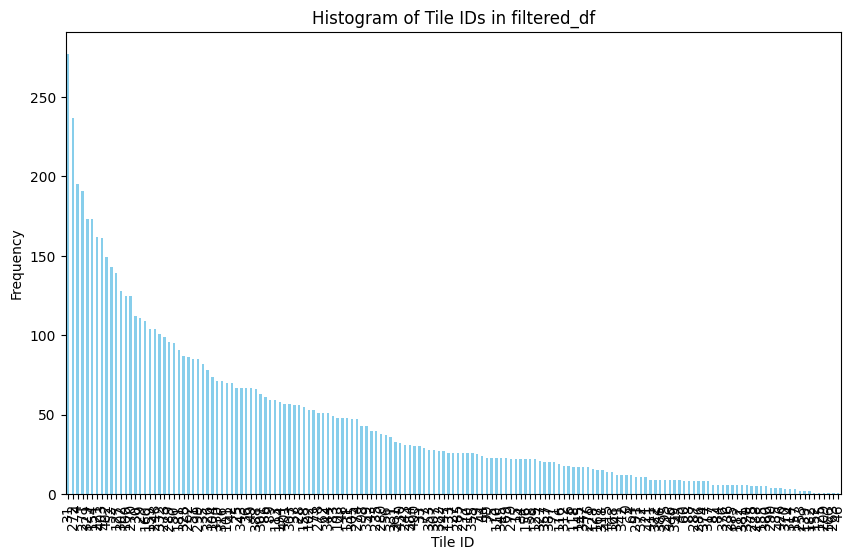

In [272]:
# Count unique appearances of tile_ids in filtered_df
tile_id_counts = filtered_df['tile_id'].value_counts()

# Plot histogram of all tiles
plt.figure(figsize=(10, 6))
tile_id_counts.plot(kind='bar', color='skyblue')
plt.xlabel('Tile ID')
plt.ylabel('Frequency')
plt.title('Histogram of Tile IDs in filtered_df')
plt.xticks(rotation=90)
plt.show()

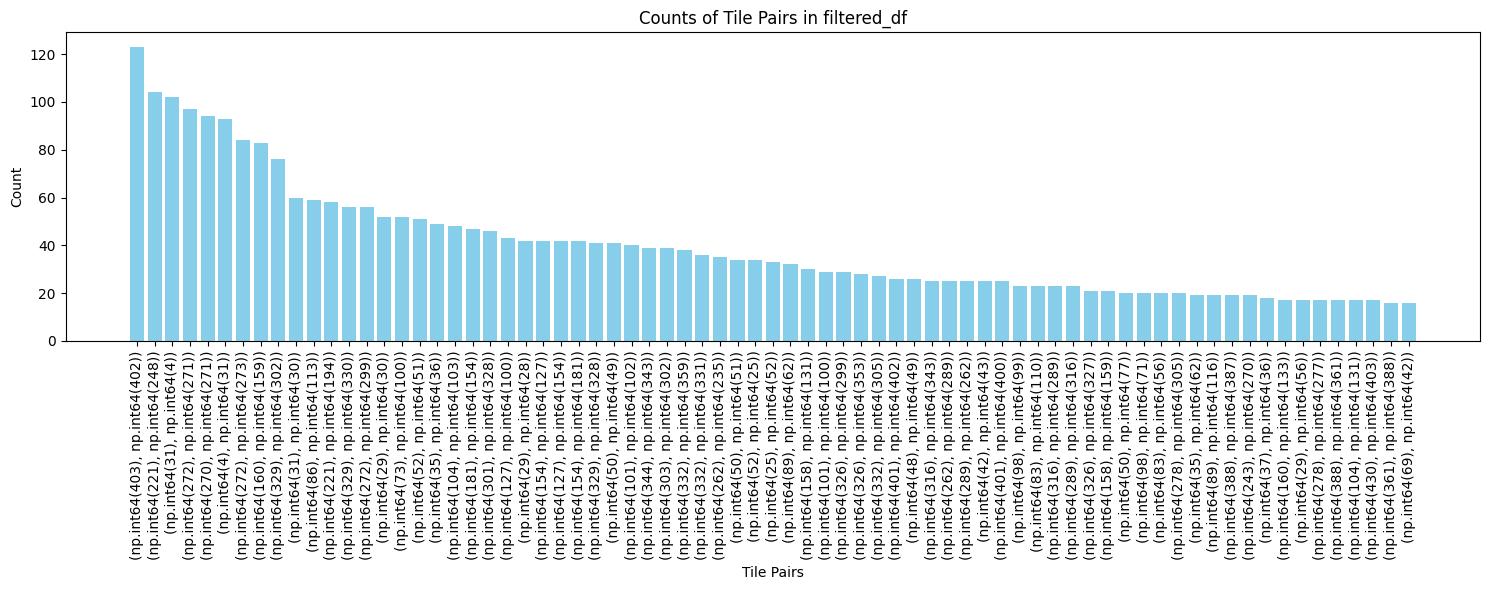

,Tile Pair,Count
55,"(403, 402)",123
21,"(221, 248)",104
5,"(31, 4)",102
23,"(272, 271)",97
32,"(270, 271)",94
...,...,...
102,"(388, 361)",17
39,"(104, 131)",17
56,"(430, 403)",17
129,"(361, 388)",16


In [283]:
from collections import Counter
import matplotlib.pyplot as plt

# Create a list of tuples for each pair of consecutive rows in filtered_df
tile_tuples = [
    tuple((filtered_df.iloc[i]['tile_id'], filtered_df.iloc[i + 1]['tile_id']))
    for i in range(0, len(filtered_df) - 1, 2)
]

# Count the occurrences of each tuple
tuple_counts = Counter(tile_tuples)
# Convert the counts to a DataFrame for easier plotting
tile_tuples = [(int(t[0]), int(t[1])) for t in tile_tuples]
tuple_counts_df = pd.DataFrame(tuple_counts.items(), columns=['Tile Pair', 'Count']).sort_values(by='Count', ascending=False)

# For plot, create a df without all tuples that occurs only once
tuple_counts_df_plot = tuple_counts_df[tuple_counts_df['Count'] > 15]

# Plot the counts
plt.figure(figsize=(15, 6))
plt.bar(tuple_counts_df_plot['Tile Pair'].astype(str), tuple_counts_df_plot['Count'], color='skyblue')
plt.xlabel('Tile Pairs')
plt.ylabel('Count')
plt.title('Counts of Tile Pairs in filtered_df')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Display the DataFrame
tuple_counts_df_plot

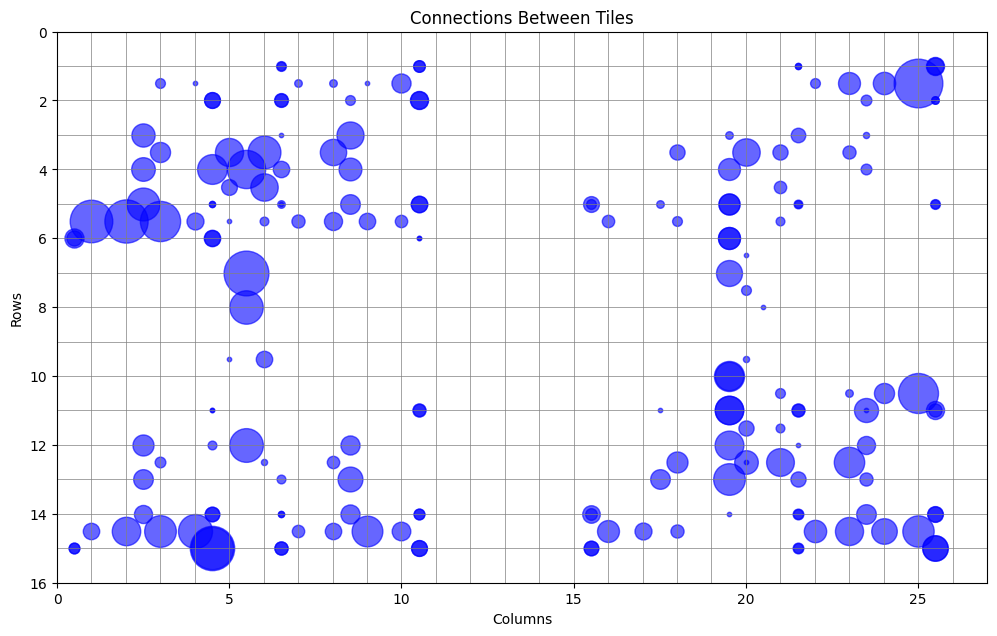

In [311]:
import matplotlib.pyplot as plt

# Define grid size
rows, cols = 16, 27

# Create a figure
plt.figure(figsize=(12, 8))

# Draw the grid
for row in range(rows + 1):
    plt.plot([0, cols], [row, row], color='gray', linewidth=0.5)
for col in range(cols + 1):
    plt.plot([col, col], [0, rows], color='gray', linewidth=0.5)

# Plot the connections
for _, row in tuple_counts_df.iterrows():
    tile1, tile2 = row['Tile Pair']
    count = row['Count']

    # Calculate the coordinates of the two tiles
    x1, y1 = tile1 % cols, tile1 // cols
    x2, y2 = tile2 % cols, tile2 // cols

    # Calculate the midpoint between the two tiles
    mid_x, mid_y = (x1 + x2) / 2, (y1 + y2) / 2

    # Plot a circle at the midpoint with size proportional to the count
    plt.scatter(mid_x + 0.5, rows - mid_y - 0.5, s=count * 10, color='blue', alpha=0.6)

# Set axis limits and labels
plt.xlim(0, cols)
plt.ylim(0, rows)
plt.gca().invert_yaxis()
plt.gca().set_aspect('equal', adjustable='box')
plt.title('Connections Between Tiles')
plt.xlabel('Columns')
plt.ylabel('Rows')

# Show the plot
plt.show()

In [346]:
test_tiles.loc[4, 'coordinates']

(2, 8)

In [347]:
test_tiles

,coordinates,is_graph,borders
0,"(2, 4)",True,"[True, True, False, True]"
1,"(2, 5)",True,"[False, False, False, True]"
2,"(2, 6)",True,"[False, True, True, True]"
3,"(2, 7)",False,"[False, False, False, False]"
4,"(2, 8)",True,"[True, True, False, True]"
...,...,...,...
427,"(28, 15)",False,"[False, False, False, False]"
428,"(28, 16)",False,"[False, False, False, False]"
429,"(28, 17)",False,"[False, False, False, False]"
430,"(28, 18)",False,"[False, False, False, False]"


In [196]:
import matplotlib.pyplot as plt

def visualize_full_grid(tiles_df, tile_pairs_df, export=False):
    """
    Visualize the entire grid with green for graph tiles, red borders, and circles representing tile pair counts.
    The midpoint for each tile pair is calculated using the tile centers from the 'coordinates' column.
    """
    fig, ax = plt.subplots()
    
    # Draw tiles using their stored coordinates [(x, y) is the lower-left corner, center is (x+0.5, y+0.5)]
    for idx, row in tiles_df.iterrows():
        x, y = row['coordinates']
        color = 'green' if row['is_graph'] else 'white'
        rect = plt.Rectangle((x, y), 1, 1, facecolor=color, edgecolor='black')
        ax.add_patch(rect)
        
        # Draw red borders if specified
        if row['borders'][0]:  # Top border
            ax.plot([x, x + 1], [y, y], color='red', linewidth=2)
        if row['borders'][1]:  # Right border
            ax.plot([x + 1, x + 1], [y, y + 1], color='red', linewidth=2)
        if row['borders'][2]:  # Bottom border
            ax.plot([x, x + 1], [y + 1, y + 1], color='red', linewidth=2)
        if row['borders'][3]:  # Left border
            ax.plot([x, x], [y, y + 1], color='red', linewidth=2)
    
    # Draw circles for tile pair counts using each tile's center from the tiles_df
    for _, pair_row in tile_pairs_df.iterrows():
        tile1_id, tile2_id = pair_row['Tile Pair']
        count = pair_row['Count']
        
        # Retrieve the tile coordinates (assume tile id corresponds to the index in tiles_df)
        tile1_coord = tiles_df.loc[tile1_id, 'coordinates']
        tile2_coord = tiles_df.loc[tile2_id, 'coordinates']
        
        # Calculate the centers of each tile (center = lower-left corner + (0.5, 0.5))
        center1 = (tile1_coord[0] + 0.5, tile1_coord[1] + 0.5)
        center2 = (tile2_coord[0] + 0.5, tile2_coord[1] + 0.5)
        
        # The midpoint between the two centers
        mid_x = (center1[0] + center2[0]) / 2
        mid_y = (center1[1] + center2[1]) / 2
        
        # Plot a circle at the midpoint with a size proportional to the count
        ax.scatter(mid_x, mid_y, s=count * 10, color='blue', alpha=0.6)
        # Add text with the tile pair at the circle's midpoint
        # ax.text(mid_x, mid_y, f"{tile1_id}-{tile2_id}", color='black', fontsize=8, ha='center', va='center')
        # ax.scatter(mid_x, mid_y, s=count * 10, color='blue', alpha=0.6)
    
    # Set axis limits based on the tiles coordinates
    xs = tiles_df['coordinates'].apply(lambda c: c[0])
    ys = tiles_df['coordinates'].apply(lambda c: c[1])
    ax.set_xlim(xs.min() - 1, xs.max() + 2)
    ax.set_ylim(ys.min() - 1, ys.max() + 2)
    ax.set_aspect('equal')
    fig.set_size_inches(12, 8)
    
    ax.invert_yaxis()
    
    if export:
        plt.savefig('/var/home/almogmeir/Documents/M.Sc/Project/Input/full_grid_with_circles.png')
    plt.show()

# Call the function to visualize the full grid with circles
visualize_full_grid(test_tile_rows, tuple_counts_df_plot, export=False)

NameError: name 'tuple_counts_df_plot' is not defined

In [275]:
tuple_counts_df

NameError: name 'tuple_counts_df' is not defined

In [276]:
filtered_df[30:31]

coords,x,y,likelihood,tile_box,tile_id,tree_position,graph_node,tile_id_diff
842,232.865326,360.029358,0.690709,"[246, 243, 31, 31]",83,22,"(4, 7)",-27.0


In [277]:
def count_tile_sequences(data):
    """
    Count sequences of the same tile position for tiles with tree_position as int or frozenset.
    Save the tile's sequences by first frame (start) and sequence length (in seconds).

    Args:
        data (pd.DataFrame): The DataFrame containing the data.

    Returns:
        list: A list of dictionaries with 'start', 'sequence_length' (in seconds), and 'tile_id'.
    """

    sequences = []
    current_tile = None
    current_start = None
    current_length = 0

    for idx, row in data.iterrows():
        tree_position = row['tree_position']
        if isinstance(tree_position, (int, frozenset)):
            if row['tile_id'] == current_tile:
                current_length += 1
            else:
                if current_tile is not None:
                    # Save the completed sequence
                    sequences.append({
                        'start': current_start,
                        'sequence_length': current_length / 40,  # Convert to seconds
                        'tile_id': current_tile
                    })
                # Start a new sequence
                current_tile = row['tile_id']
                current_start = idx
                current_length = 1
        else:
            if current_tile is not None:
                # Save the completed sequence
                sequences.append({
                    'start': current_start,
                    'sequence_length': current_length / 40,  # Convert to seconds
                    'tile_id': current_tile
                })
                current_tile = None
                current_start = None
                current_length = 0

    # Save the last sequence if it exists
    if current_tile is not None:
        sequences.append({
            'start': current_start,
            'sequence_length': current_length / 40,  # Convert to seconds
            'tile_id': current_tile
        })

    return sequences

# Apply the function to the data DataFrame
tile_sequences = count_tile_sequences(data)

# Display the results
tile_sequences[:10]  # Show the first 10 sequences

[{'start': 529, 'sequence_length': 0.175, 'tile_id': 27},
 {'start': 555, 'sequence_length': 0.025, 'tile_id': 29},
 {'start': 560, 'sequence_length': 0.025, 'tile_id': 29},
 {'start': 570, 'sequence_length': 0.1, 'tile_id': 31},
 {'start': 575, 'sequence_length': 0.025, 'tile_id': 31},
 {'start': 585, 'sequence_length': 0.1, 'tile_id': 29},
 {'start': 598, 'sequence_length': 0.1, 'tile_id': 29},
 {'start': 618, 'sequence_length': 0.075, 'tile_id': 31},
 {'start': 621, 'sequence_length': 0.05, 'tile_id': 58},
 {'start': 630, 'sequence_length': 0.025, 'tile_id': 58}]

In [334]:
from collections import defaultdict
from collections import OrderedDict

def group_tile_sequences(tile_sequences):
    """
    Group tile sequences by tile_id and aggregate all sequences for each tile.

    Args:
        tile_sequences (list): List of dictionaries with 'start', 'sequence_length', and 'tile_id'.

    Returns:
        dict: A dictionary where keys are tile_ids and values are lists of tuples (start, sequence_length).
    """
    grouped_sequences = defaultdict(list)
    
    for seq in tile_sequences:
        grouped_sequences[seq['tile_id']].append((seq['start'], seq['sequence_length']))
    
    # Sort the sequences for each tile_id by start
    for tile_id in grouped_sequences:
        grouped_sequences[tile_id].sort(key=lambda x: x[0])
    
    return grouped_sequences

# Group the tile sequences
grouped_tile_sequences = group_tile_sequences(tile_sequences)

def sort_grouped_sequences_by_tile_id(grouped_sequences):
    """
    Sort the grouped sequences dictionary by tile_id.

    Args:
        grouped_sequences (dict): Dictionary where keys are tile_ids and values are lists of tuples.

    Returns:
        OrderedDict: Sorted dictionary by tile_id.
    """
    return OrderedDict(sorted(grouped_sequences.items()))

# Sort the grouped sequences
grouped_tile_sequences = sort_grouped_sequences_by_tile_id(grouped_tile_sequences)

# Display the grouped sequences
grouped_tile_sequences

OrderedDict([(0,
              [(1340, 0.175),
               (7147, 0.95),
               (8932, 0.175),
               (15334, 0.225),
               (42307, 0.8),
               (68842, 0.35),
               (83275, 0.05),
               (83278, 0.025),
               (83280, 0.1),
               (97577, 0.275)]),
             (4,
              [(662, 0.425),
               (681, 1.85),
               (7244, 5.45),
               (7463, 0.35),
               (7480, 0.05),
               (7483, 0.025),
               (7531, 3.5),
               (7674, 0.3),
               (7704, 0.1),
               (7713, 0.025),
               (8109, 0.95),
               (8959, 0.1),
               (8966, 2.6),
               (10699, 0.15),
               (10709, 2.2),
               (10799, 0.025),
               (10805, 0.05),
               (10815, 12.15),
               (11302, 0.025),
               (11317, 0.025),
               (15377, 0.025),
               (15384, 3.975),
               (

In [337]:
# Sort tile_sequences by sequence_length in descending order
sorted_tile_sequences = sorted(tile_sequences, key=lambda x: x['sequence_length'], reverse=True)

# Display the sorted sequences
sorted_tile_sequences[:10]  # Show the top 10 longest sequences

[{'start': 35634, 'sequence_length': 20.1, 'tile_id': 430},
 {'start': 37610, 'sequence_length': 18.45, 'tile_id': 399},
 {'start': 108980, 'sequence_length': 16.925, 'tile_id': 243},
 {'start': 138727, 'sequence_length': 16.75, 'tile_id': 4},
 {'start': 104860, 'sequence_length': 15.7, 'tile_id': 4},
 {'start': 41223, 'sequence_length': 14.2, 'tile_id': 4},
 {'start': 27344, 'sequence_length': 13.775, 'tile_id': 430},
 {'start': 36555, 'sequence_length': 13.675, 'tile_id': 430},
 {'start': 45533, 'sequence_length': 13.3, 'tile_id': 243},
 {'start': 92640, 'sequence_length': 13.225, 'tile_id': 160}]

In [338]:
# Get the maximum sequence length per tile
max_length_per_tile = {tile_id: max(seq_length for _, seq_length in seq_list)
                       for tile_id, seq_list in grouped_tile_sequences.items()}
print(max_length_per_tile)

{0: 0.95, 4: 16.75, 6: 0.9, 10: 1.2, 15: 3.9, 21: 3.25, 25: 4.975, 27: 0.9, 28: 0.075, 29: 1.475, 30: 0.075, 31: 2.0, 33: 0.475, 35: 8.675, 37: 2.575, 42: 7.375, 44: 1.5, 46: 2.1, 48: 4.525, 50: 4.5, 52: 1.45, 56: 0.6, 58: 2.175, 60: 1.7, 64: 0.925, 69: 1.1, 71: 0.15, 73: 1.3, 75: 1.9, 79: 3.2, 83: 1.4, 86: 2.15, 89: 2.95, 98: 0.7, 100: 0.05, 101: 1.475, 103: 0.175, 104: 0.8, 108: 2.6, 112: 0.85, 114: 1.225, 118: 2.1, 123: 3.35, 127: 0.8, 129: 1.875, 131: 0.025, 133: 2.775, 139: 0.625, 145: 0.375, 152: 0.05, 154: 1.175, 156: 0.3, 158: 0.475, 159: 0.525, 160: 13.225, 166: 0.025, 168: 3.125, 181: 1.8, 221: 1.275, 235: 1.125, 236: 0.5, 243: 16.925, 247: 1.625, 249: 0.025, 253: 0.05, 262: 2.175, 270: 0.9, 271: 0.05, 272: 6.7, 274: 1.825, 276: 1.525, 278: 4.925, 280: 1.55, 285: 8.45, 287: 0.225, 289: 0.9, 291: 0.15, 295: 0.65, 299: 1.475, 301: 1.325, 303: 1.675, 307: 0.85, 312: 0.825, 316: 2.05, 318: 1.775, 320: 0.275, 322: 0.55, 326: 1.025, 329: 1.525, 332: 1.3, 341: 2.4, 344: 1.475, 347: 

In [250]:
filtered_df

coords,pair_group,tile_id,likelihood,tile_pair
4,280,"[29, 28]",0.478603,"(29, 28)"
6,287,"[30, 31]",0.385407,"(30, 31)"
8,294,"[29, 30]",0.373536,"(29, 30)"
11,310,"[31, 58]",0.440201,"(31, 58)"
14,339,"[4, 31]",0.785266,"(4, 31)"
...,...,...,...,...
5248,71729,"[272, 273]",0.576087,"(272, 273)"
5249,71735,"[301, 328]",0.761746,"(301, 328)"
5250,71737,"[329, 302]",0.572703,"(329, 302)"
5255,71756,"[303, 302]",0.489410,"(303, 302)"


In [53]:
nan_streaks_df[nan_streaks_df['Streak Length'] > 7]

NameError: name 'nan_streaks_df' is not defined

In [279]:
num_nan_likelihood_rows = data['likelihood'].isna().sum()
print(f"Number of rows where likelihood is NaN: {num_nan_likelihood_rows}")
print(f"Percentage of rows where likelihood is NaN: {num_nan_likelihood_rows / len(data) * 100:.2f}%")

Number of rows where likelihood is NaN: 209
Percentage of rows where likelihood is NaN: 0.15%


In [278]:
data[-100:-50]

coords,x,y,likelihood,tile_box,tile_id,tree_position,graph_node,tile_id_diff
143439,171.073517,716.913696,0.370814,"[214, 467, 31, 31]",271,"(30, 40)","(3, 14)",0.0
143440,171.267136,717.311462,0.396756,"[214, 467, 31, 31]",271,"(30, 40)","(3, 14)",0.0
143441,172.704803,715.463928,0.471783,"[214, 467, 31, 31]",271,"(30, 40)","(3, 14)",0.0
143442,173.953430,713.233765,0.473101,"[214, 467, 31, 31]",271,"(30, 40)","(3, 14)",0.0
143443,177.173233,712.809814,0.513745,"[214, 467, 31, 31]",271,"(30, 40)","(3, 14)",0.0
143444,177.383591,711.503357,0.591990,"[214, 467, 31, 31]",271,"(30, 40)","(3, 14)",0.0
143445,182.998184,710.632385,0.605069,"[214, 467, 31, 31]",271,"(30, 40)","(3, 14)",0.0
143446,185.129623,708.021545,0.609666,"[214, 467, 31, 31]",271,"(30, 40)","(3, 14)",0.0
143447,186.964417,707.674927,0.655727,"[214, 467, 31, 31]",271,"(30, 40)","(3, 14)",0.0
143448,188.369461,706.130981,0.615772,"[214, 467, 31, 31]",271,"(30, 40)","(3, 14)",0.0
